<a href="https://colab.research.google.com/github/Andrellz27/Foundtions-models-to-histology-classification/blob/main/avaliacao_uni_conch_virchow_gigapath.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# super_codigo_4 — Avaliação de foundation models em histopatologia (severidade ordinal)

**Ordem de execução:** rode as células 1 → 10 em sequência. A célula 10 roda as checagens de sanidade e a bateria de testes do UNI (fases 0 a 7).

- **Se o Colab desconectar:** rode tudo de novo. A bateria pula o que já foi salvo em `resultados_histopatologia/bateria_uni`.
- **Para rodar só algumas fases:** edite `FASES` na célula 10.
- **Para trocar a foundation:** edite `SUITE_BACKBONE` na célula 10.
- **Pré-requisitos:** GPU T4 ativa; token `HF_TOKEN` nos Secrets do Colab; acesso aprovado ao repositório `MahmoodLab/uni` no Hugging Face.


In [ ]:
# -*- coding: utf-8 -*-
"""super_codigo_4

Versão revisada de super_codigo_3, alinhada ao novo prompt. Mudanças principais:

  0. Split: holdout 70/20/10 com train_test_split (pedido no prompt), repetido em várias
     sementes. A divisão é feita sobre IMAGENS DE ORIGEM (grupo = pasta da classe + prefixo
     antes de '-roiN') e estratificada pela classe: ROIs da mesma imagem nunca ficam em
     partições diferentes (split_by_group=False desliga isso, mas gera vazamento).
  1. Batch size dinâmico: tabela por backbone (calibrada para T4 16 GB) separada em
     'extract' (embeddings, sem gradiente) e 'partial' (treino), escalonada pela VRAM da GPU,
     com fallback automático de OOM (divide o lote por 2 e dobra a acumulação, preservando o
     batch efetivo). O lote realmente usado é registrado em todas as tabelas.
  2. Tabelas com metadados (Modelo, Regime, Loss, LR, Época, Batch size, Accum, Batch efetivo,
     tempos e pico de VRAM), exibidas com display() e exportadas em .csv no Drive.
  3. Gráficos com plt.show() + plt.savefig(): curvas de aprendizado (loss e métricas por
     época), curvas de regularização C (frozen), matrizes de confusão do teste, resumo com IC
     e análise do impacto do batch size.
  4. Retomada (resume): cada (cenário, semente) é salvo assim que termina; rodar de novo pula
     o que já existe. Essencial no Colab gratuito, que desconecta.
  5. Rotina de testes: checagens de sanidade (gradiente da sonda, losses torch x numpy,
     métricas rápidas x sklearn, split sem vazamento), smoke test e uma bateria de fases para
     uma foundation (UNI por padrão), com escolha da melhor loss feita pela VALIDAÇÃO.
"""

# %% [CÉLULA 1] Configuração global, hiperparâmetros e seleção de testes
from __future__ import annotations

import argparse
import dataclasses
import hashlib
import json
import math
import warnings
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple

import numpy as np

CLASS_NAMES = ["healthy", "mild", "moderate", "severe"]  # ordem = ordem ordinal
NUM_CLASSES = len(CLASS_NAMES)
SEEDS = list(range(10))  # cada semente = um split 70/20/10 diferente (holdout repetido)

FOUNDATION_BACKBONES = ("gigapath_flash", "virchow", "uni", "conch")
BASELINES = ("imagenet_r50", "color")
BACKBONES = FOUNDATION_BACKBONES + BASELINES
FROZEN_ONLY = set(BASELINES)  # baselines não têm blocos ViT para o regime partial
LOSSES = ("coral", "corn", "ce")
# frozen       : sonda linear L2 sobre embeddings sem augmentation
# frozen_aug   : idem, com cópias aumentadas dos embeddings de treino (controle do ablation)
# partial      : últimos N blocos destravados, com augmentation
# partial_noaug: idem, sem augmentation (controle do ablation)
REGIMES = ("frozen", "frozen_aug", "partial", "partial_noaug")
LR_VARIANTS = ("low", "mid", "high")  # usadas SÓ no regime partial

HF_IDS = {
    "gigapath_flash": "hf_hub:prov-gigapath/prov-gigapath-flash",  # conferir origem deste checkpoint
    "virchow": "hf-hub:paige-ai/Virchow",
    "uni": "hf-hub:MahmoodLab/uni",
    "conch": "hf_hub:MahmoodLab/conch",
    "imagenet_r50": "resnet50.tv_in1k",  # ResNet-50 supervisionada em ImageNet (timm)
}
HF_REPOS = {  # repositório no HF de cada peso (para registrar o commit usado)
    "gigapath_flash": "prov-gigapath/prov-gigapath-flash",
    "virchow": "paige-ai/Virchow",
    "uni": "MahmoodLab/uni",
    "conch": "MahmoodLab/conch",
    "imagenet_r50": "timm/resnet50.tv_in1k",
}
# Resolução (µm/pixel) aproximada dos tiles de pré-treino, para o relatório de magnificação.
MODEL_TRAIN_MPP = {"gigapath_flash": 0.5, "virchow": 0.5, "uni": 0.5, "conch": 0.5,
                   "imagenet_r50": None, "color": None}

# Learning rates do regime partial (o frozen não tem LR: é resolvido por L-BFGS).
BACKBONE_HPARAMS: Dict[str, Dict] = {
    "gigapath_flash": {"lr_head": {"low": 1e-4, "mid": 5e-4, "high": 1e-3},
                       "lr_backbone_partial": {"low": 1e-6, "mid": 5e-6, "high": 1e-5}},
    "virchow": {"lr_head": {"low": 5e-6, "mid": 1e-5, "high": 5e-5},
                "lr_backbone_partial": {"low": 1e-7, "mid": 5e-7, "high": 1e-6}},
    "uni": {"lr_head": {"low": 1e-5, "mid": 5e-5, "high": 1e-4},
            "lr_backbone_partial": {"low": 1e-6, "mid": 5e-6, "high": 1e-5}},
    "conch": {"lr_head": {"low": 1e-5, "mid": 5e-5, "high": 1e-4},
              "lr_backbone_partial": {"low": 1e-6, "mid": 5e-6, "high": 1e-5}},
}

# ---------------------------------------------------------------------------------------
# BATCH SIZE DINÂMICO. Unidade = ROIs por lote (cada ROI 450x250 vira 2 janelas no
# multi-crop, então o nº de imagens que passam pela rede é ~2x o valor abaixo).
# Calibrado para Tesla T4 (16 GB, fp16 — o T4 não tem bf16). Em GPUs maiores o valor é
# multiplicado por vram_factor() (potência de 2: 1x até ~28 GB, 2x no A100-40, 4x no A100-80).
#   extract: só inferência (sem gradiente) -> lotes grandes.
#   partial: guarda ativações dos blocos destravados -> lotes menores.
# ViTs pesados (Virchow ViT-H/14, GigaPath ViT-g) recebem lotes pequenos; a ResNet-50, grandes.
# CONCH usa janelas de 448 px (4x mais tokens por janela que 224 px).
# Se mesmo assim faltar memória, o fallback de OOM divide o lote por 2 automaticamente.
# ---------------------------------------------------------------------------------------
BATCH_SIZE_T4: Dict[str, Dict[str, Optional[int]]] = {
    "imagenet_r50":   {"extract": 128, "partial": None},  # ~25M params
    "conch":          {"extract": 32,  "partial": 8},     # ViT-B/16 @ 448 px
    "uni":            {"extract": 64,  "partial": 32},    # ViT-L/16 @ 224 px (~300M)
    "virchow":        {"extract": 16,  "partial": 8},     # ViT-H/14 @ 224 px (~630M)
    "gigapath_flash": {"extract": 8,   "partial": 4},     # ViT-g/14 (~1,1B)
    "color":          {"extract": None, "partial": None},  # sem rede neural
}


@dataclass
class Config:
    # --- caminhos ---
    drive_dataset_dir: str = "/content/drive/MyDrive/Original_ROI_images (1).zip"  # ajustado na célula
    local_dataset_dir: str = "/content/dataset"
    drive_results_dir: str = "/content/drive/MyDrive/resultados_histopatologia"
    embeddings_dir: str = "/content/drive/MyDrive/resultados_histopatologia/embeddings_cache"
    run_name: Optional[str] = None   # None => run_AAAAMMDD_HHMMSS; com nome fixo, permite retomar
    resume: bool = True              # pula (cenário, semente) já salvos em run_name
    # --- seleção de testes ---
    seeds: List[int] = field(default_factory=lambda: list(SEEDS))
    partial_seeds: Optional[List[int]] = None   # None => as mesmas de 'seeds'
    backbone: List[str] = field(default_factory=lambda: ["all"])
    regime: List[str] = field(default_factory=lambda: ["all"])
    loss: List[str] = field(default_factory=lambda: ["all"])
    lr_variant: List[str] = field(default_factory=lambda: ["mid"])
    # --- split holdout (train_test_split) ---
    train_frac: float = 0.70
    val_frac: float = 0.20
    test_frac: float = 0.10
    split_by_group: bool = True      # divide imagens de origem (evita vazamento entre ROIs)
    subset_groups_per_class: Optional[int] = None  # só para smoke test (nº de imagens/classe)
    # --- multi-crop e magnificação ---
    scales: List[float] = field(default_factory=lambda: [1.0])  # ex.: [1.0, 0.5] p/ sensibilidade
    native_mpp: Optional[float] = None   # µm/pixel da captura original, se conhecido
    # --- sonda linear (regimes frozen) ---
    c_grid: List[float] = field(default_factory=lambda: np.logspace(-5, 1, 13).tolist())
    c_patience: int = 3          # para a busca de C após N valores sem melhora (0 = grade toda)
    probe_max_iter: int = 3000
    frozen_aug_copies: int = 4   # nº de cópias aumentadas por ROI no regime frozen_aug
    # --- regime partial ---
    n_unfrozen_blocks: int = 2
    weight_decay: float = 1e-2
    epochs: int = 20
    patience: int = 6
    warmup_ratio: float = 0.05
    grad_clip: float = 1.0
    label_smoothing: float = 0.0   # 0 para todas as losses (evita confundir CE vs ordinais)
    use_amp: bool = True
    num_workers: int = 2
    # --- batch size ---
    effective_batch: int = 32    # ROIs por passo do otimizador (lote físico x acumulação)
    # Lista de configurações do partial: None = automático (tabela + VRAM); (lote, efetivo)
    # = fixo, para o estudo de impacto do batch size.
    partial_batch_configs: List[Optional[Tuple[int, int]]] = field(default_factory=lambda: [None])
    vram_scaling: bool = True
    max_oom_retries: int = 4
    # --- estatística ---
    n_boot: int = 1000
    ci_level: float = 0.95
    # --- saídas ---
    show_plots: bool = True
    # --- ambiente ---
    install_deps: bool = True


def _expand(values: List[str], universe) -> List[str]:
    return list(universe) if "all" in values else list(values)


def _in_notebook() -> bool:
    import sys
    return "ipykernel" in sys.modules


def build_config(argv=None) -> Config:
    """CLI (--backbone, --regime, --loss, --lr_variant etc.). Ignora argumentos do Colab."""
    p = argparse.ArgumentParser(allow_abbrev=False)
    p.add_argument("--backbone", nargs="+", default=["all"], choices=list(BACKBONES) + ["all"])
    p.add_argument("--regime", nargs="+", default=["all"], choices=list(REGIMES) + ["all"])
    p.add_argument("--loss", nargs="+", default=["all"], choices=list(LOSSES) + ["all"])
    p.add_argument("--lr_variant", nargs="+", default=["mid"], choices=list(LR_VARIANTS) + ["all"])
    p.add_argument("--seeds", nargs="+", type=int, default=list(SEEDS))
    p.add_argument("--scales", nargs="+", type=float, default=[1.0])
    p.add_argument("--native_mpp", type=float, default=None)
    p.add_argument("--epochs", type=int, default=Config.epochs)
    p.add_argument("--effective_batch", type=int, default=Config.effective_batch)
    p.add_argument("--run_name", default=None)
    args, _ = p.parse_known_args(argv if argv is not None else [] if _in_notebook() else None)
    return Config(
        backbone=_expand(args.backbone, BACKBONES), regime=_expand(args.regime, REGIMES),
        loss=_expand(args.loss, LOSSES), lr_variant=_expand(args.lr_variant, LR_VARIANTS),
        seeds=args.seeds, scales=args.scales, native_mpp=args.native_mpp, epochs=args.epochs,
        effective_batch=args.effective_batch, run_name=args.run_name,
    )


CFG = build_config()

# ---------------------------------------------------------------------------------------
# No Colab, a bateria de testes da CÉLULA 10 cria as configurações de cada fase a partir
# deste CFG base. Para uma execução avulsa, edite aqui e chame main(CFG) na CÉLULA 10.
# A lista de backbones abaixo só controla quais dependências extras a CÉLULA 2 instala.
# ---------------------------------------------------------------------------------------
if _in_notebook():
    CFG = Config(backbone=["uni", "conch", "virchow",
                            "imagenet_r50", "color"],
                 regime=["all"], loss=["all"])

import zipfile  # noqa: E402
from pathlib import Path  # noqa: E402

from google.colab import drive  # noqa: E402

drive.mount("/content/drive")
pasta_extraida = Path("/content/Original_ROI_images")


def localizar_zip_dataset(mydrive: Path, pista: str = "Original_ROI_images") -> Path:
    """Procura o zip do dataset em MyDrive por conteúdo do nome (o Drive adiciona '(1)' etc.)."""
    candidatos = sorted(mydrive.rglob(f"*{pista}*.zip"))
    if len(candidatos) == 1:
        print(f"[dataset] zip localizado: {candidatos[0]}")
        return candidatos[0]
    if not candidatos:
        todos_zips = sorted(p.name for p in mydrive.rglob("*.zip"))
        raise FileNotFoundError(f"Nenhum .zip com '{pista}' em {mydrive}. Zips: {todos_zips[:30]}")
    raise FileNotFoundError(f"Mais de um candidato: {[str(p) for p in candidatos]}. Escolha um.")


if not pasta_extraida.exists():
    with zipfile.ZipFile(localizar_zip_dataset(Path("/content/drive/MyDrive")), "r") as z:
        z.extractall(pasta_extraida)


def encontrar_raiz_classes(base: Path, classes) -> Path:
    for cand in [base] + [p for p in base.rglob("*") if p.is_dir()]:
        if all((cand / c).is_dir() for c in classes):
            return cand
    raise FileNotFoundError(f"Não encontrei as pastas {classes} dentro de {base}.")


CFG.drive_dataset_dir = str(encontrar_raiz_classes(pasta_extraida, CLASS_NAMES))
print("Raiz do dataset:", CFG.drive_dataset_dir)
print(CFG)


In [ ]:
# %% [CÉLULA 2] Dependências (com lock de versões), login no HF e registro do ambiente
import importlib.metadata as imd  # noqa: E402
import importlib.util  # noqa: E402
import os  # noqa: E402
import re  # noqa: E402
import subprocess  # noqa: E402
import sys  # noqa: E402


def pip_install(*pkgs: str) -> None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


# Pacotes cujas versões são congeladas no lock (torch/torchvision vêm do Colab e são só registrados).
LOCK_PACKAGES = {"timm", "huggingface-hub", "scikit-learn", "scikit-image", "scipy", "pandas",
                 "tabulate", "matplotlib", "conch"}
LOCK_PATH = Path(CFG.drive_results_dir) / "requirements_lock.txt"


def _norm_pkg(name: str) -> str:
    return name.strip().lower().replace("_", "-")


def write_lock(path: Path) -> None:
    """Grava as versões exatas instaladas. Nas execuções seguintes, o lock é reinstalado."""
    freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True,
                            text=True, check=True).stdout.splitlines()
    keep = [ln for ln in freeze if _norm_pkg(re.split(r"[=@ ]", ln, maxsplit=1)[0]) in LOCK_PACKAGES]
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text("\n".join(keep) + "\n")
    print(f"[deps] lock gravado em {path}:\n  " + "\n  ".join(keep))


if CFG.install_deps:
    if LOCK_PATH.exists():
        print(f"[deps] instalando versões congeladas de {LOCK_PATH}")
        pip_install("-r", str(LOCK_PATH))
    else:
        pip_install("timm>=1.0.3", "huggingface_hub", "scikit-learn", "scikit-image", "scipy",
                    "pandas", "tabulate", "matplotlib")
    if "conch" in CFG.backbone and importlib.util.find_spec("conch") is None:
        pip_install("git+https://github.com/Mahmoodlab/CONCH.git")
    if not LOCK_PATH.exists():
        write_lock(LOCK_PATH)

GIGAPATH_COMMIT = None
if "gigapath_flash" in CFG.backbone:
    import shutil  # noqa: E402
    gp_dir = Path("/content/prov-gigapath")
    if not (gp_dir / "gigapath").is_dir():
        if gp_dir.exists():
            shutil.rmtree(gp_dir)
        subprocess.run(["git", "clone", "https://github.com/prov-gigapath/prov-gigapath", str(gp_dir)],
                       check=True)
    pip_install("-e", str(gp_dir))
    if str(gp_dir) not in sys.path:
        sys.path.insert(0, str(gp_dir))
    GIGAPATH_COMMIT = subprocess.run(["git", "-C", str(gp_dir), "rev-parse", "HEAD"],
                                     capture_output=True, text=True).stdout.strip()

from huggingface_hub import HfApi, get_token, login, notebook_login  # noqa: E402



from huggingface_hub import HfApi, get_token, login  # noqa: E402


def _hf_login() -> Optional[str]:
    """Obtém e VALIDA o token do Hugging Face. Ordem: Secret HF_TOKEN do Colab, variável de
    ambiente HF_TOKEN, token já salvo na sessão. Se nenhum servir, PEDE o token digitado
    (getpass: o código ESPERA você colar e teclar Enter; Enter vazio = seguir sem token).
    Obs.: o notebook_login() da versão anterior só exibia um widget e deixava a célula seguir
    sem esperar; por isso o código parecia 'não pedir' o login."""
    candidatos = []
    try:
        from google.colab import userdata  # noqa: E402
        candidatos.append(("Secret HF_TOKEN do Colab", userdata.get("HF_TOKEN")))
    except Exception:   # noqa: BLE001 — fora do Colab, sem Secret ou sem acesso do notebook ao Secret
        pass
    candidatos += [("variável de ambiente HF_TOKEN", os.environ.get("HF_TOKEN")),
                   ("token salvo na sessão", get_token())]
    for origem, tok in candidatos:
        if not tok:
            continue
        try:
            usuario = HfApi().whoami(token=tok).get("name")
        except Exception as e:   # noqa: BLE001
            print(f"[hf] token de '{origem}' recusado ({type(e).__name__}); ignorado")
            continue
        login(token=tok)
        print(f"[hf] login ok via {origem} (usuário {usuario})")
        return tok
    import getpass
    for _ in range(3):
        tok = getpass.getpass("Cole o token do Hugging Face (huggingface.co/settings/tokens) e tecle Enter "
                              "(Enter vazio = seguir sem token): ").strip()
        if not tok:
            break
        try:
            usuario = HfApi().whoami(token=tok).get("name")
        except Exception as e:   # noqa: BLE001
            print(f"[hf] token recusado ({type(e).__name__}); tente de novo")
            continue
        login(token=tok)
        print(f"[hf] login ok (usuário {usuario})")
        return tok
    print("[hf] SEM TOKEN: os modelos fechados (UNI, CONCH, Virchow, TITAN, PRISM, GigaPath, "
          "Hibou-B, Athena, path-foundation) vão falhar com erro de acesso.")
    return None


HF_TOKEN = _hf_login()


def collect_env() -> Dict:
    """Versões de pacotes, GPU e commit (sha) dos pesos usados no HF."""
    import torch  # noqa: E402
    pkgs = {}
    for name in sorted(LOCK_PACKAGES | {"torch", "torchvision", "numpy"}):
        try:
            pkgs[name] = imd.version(name)
        except imd.PackageNotFoundError:
            pass
    hf_sha = {}
    api = HfApi()
    for bb, repo in HF_REPOS.items():
        try:
            hf_sha[bb] = api.model_info(repo, token=HF_TOKEN).sha
        except Exception as e:  # repositório sem acesso: registra o motivo
            hf_sha[bb] = f"indisponível ({type(e).__name__})"
    return {
        "python": sys.version.split()[0], "packages": pkgs,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "vram_gb": (round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)
                    if torch.cuda.is_available() else None),
        "cuda": torch.version.cuda, "hf_sha": hf_sha, "gigapath_commit": GIGAPATH_COMMIT,
    }


ENV_INFO = collect_env()
print(json.dumps(ENV_INFO, indent=2))


In [ ]:
# %% [CÉLULA 3] Dataset, grupos, split holdout 70/20/10, multi-crop e augmentações
import gc  # noqa: E402
import random  # noqa: E402
import shutil  # noqa: E402
import time  # noqa: E402
from datetime import datetime  # noqa: E402

import torch  # noqa: E402
import torch.nn as nn  # noqa: E402
import torch.nn.functional as F  # noqa: E402
import torchvision.transforms as T  # noqa: E402
from PIL import Image  # noqa: E402
from skimage.color import hed2rgb, rgb2hed  # noqa: E402
from sklearn.exceptions import UndefinedMetricWarning  # noqa: E402
from sklearn.model_selection import train_test_split  # noqa: E402
from torch.utils.data import DataLoader, Dataset  # noqa: E402

# Com poucos exemplos por classe no teste/validação, o sklearn avisa a cada chamada quando uma
# classe some; o valor resultante (nan) já é tratado nas métricas.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "Ative uma GPU no Colab (Ambiente de execução > Alterar tipo)."
IMG_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}


def _list_images(class_dir: Path) -> List[Path]:
    return sorted(p for p in class_dir.rglob("*") if p.suffix.lower() in IMG_EXTS)


def copy_dataset_to_local(src: str, dst: str) -> Path:
    """Copia para o disco local ANTES de criar os DataLoaders (evita gargalo de I/O)."""
    src_p, dst_p = Path(src), Path(dst)
    n_src = sum(len(_list_images(src_p / c)) for c in CLASS_NAMES)
    n_dst = sum(len(_list_images(dst_p / c)) for c in CLASS_NAMES if (dst_p / c).is_dir())
    if n_src == n_dst:
        print(f"[dataset] cópia local já completa ({n_dst} imagens) em {dst_p}")
        return dst_p
    for c in CLASS_NAMES:
        shutil.copytree(src_p / c, dst_p / c, dirs_exist_ok=True)
    assert sum(len(_list_images(dst_p / c)) for c in CLASS_NAMES) == n_src, "Cópia incompleta"
    return dst_p


def scan_dataset(root: Path):
    paths, labels = [], []
    for idx, c in enumerate(CLASS_NAMES):
        files = _list_images(root / c)
        assert files, f"Nenhuma imagem em {root / c}"
        paths += [str(p) for p in files]
        labels += [idx] * len(files)
    return paths, np.array(labels, dtype=np.int64)


# --- Grupos (imagem de origem) ---
ROI_RE = re.compile(r"(.*)-roi\d+$")


def group_id(path: str) -> str:
    """'healthy/image032-roi1' -> 'healthy/image032' (pasta de classe + imagem de origem)."""
    p = Path(path)
    m = ROI_RE.match(p.stem)
    return f"{p.parent.name}/{m.group(1) if m else p.stem}"


def subset_by_groups(labels: np.ndarray, groups: np.ndarray, k: int, seed: int = 0) -> np.ndarray:
    """Índices de um subconjunto com k imagens de origem por classe (só para o smoke test)."""
    rng = np.random.default_rng(seed)
    keep = []
    for c in range(NUM_CLASSES):
        g = np.unique(groups[labels == c])
        rng.shuffle(g)
        keep += list(g[:k])
    return np.flatnonzero(np.isin(groups, keep))


# --- Split holdout 70/20/10 com train_test_split ---
def make_holdout_split(labels: np.ndarray, groups: np.ndarray, seed: int, cfg: Config) -> Dict[str, np.ndarray]:
    """Split treino/validação/teste com duas chamadas de train_test_split, estratificadas pela
    classe. Com split_by_group=True as unidades sorteadas são as IMAGENS DE ORIGEM (todas as
    ROIs de uma imagem vão juntas para a mesma partição): sem isso, ROIs vizinhas da mesma
    lâmina aparecem no treino e no teste e o desempenho fica inflado. As proporções 70/20/10
    valem para as imagens; para as ROIs ficam aproximadas (impressas no log)."""
    fr = (cfg.train_frac, cfg.val_frac, cfg.test_frac)
    assert min(fr) > 0 and abs(sum(fr) - 1) < 1e-6, f"frações inválidas: {fr}"
    if cfg.split_by_group:
        units, first = np.unique(groups, return_index=True)
        unit_y = labels[first]
        for u, yu in zip(units, unit_y):   # grupo = pasta da classe + imagem => uma classe só
            assert (labels[groups == u] == yu).all(), f"grupo {u} com mais de uma classe"
    else:
        units, unit_y = np.arange(len(labels)), labels
    u = np.arange(len(units))
    u_tv, u_te = train_test_split(u, test_size=cfg.test_frac, stratify=unit_y[u], random_state=seed)
    u_tr, u_va = train_test_split(u_tv, test_size=cfg.val_frac / (cfg.train_frac + cfg.val_frac),
                                  stratify=unit_y[u_tv], random_state=seed)

    def to_idx(uu):
        return np.flatnonzero(np.isin(groups, units[uu])) if cfg.split_by_group else np.sort(units[uu])

    sp = {"train": to_idx(u_tr), "val": to_idx(u_va), "test": to_idx(u_te)}
    allidx = np.concatenate(list(sp.values()))
    assert len(allidx) == len(labels) and len(np.unique(allidx)) == len(labels), "split não particiona"
    if cfg.split_by_group:
        g = {k: set(groups[v]) for k, v in sp.items()}
        assert not (g["train"] & g["val"] or g["train"] & g["test"] or g["val"] & g["test"]), \
            "vazamento: imagem de origem em mais de uma partição"
    return sp


def split_summary(splits: Dict[int, Dict[str, np.ndarray]], labels, groups) -> "pd.DataFrame":
    rows = []
    for seed, sp in splits.items():
        r = {"semente": seed}
        for part in ("train", "val", "test"):
            idx = sp[part]
            r[f"{part}_rois"] = len(idx)
            r[f"{part}_%"] = round(100 * len(idx) / len(labels), 1)
            r[f"{part}_imagens"] = len(set(groups[idx]))
            r[f"{part}_por_classe"] = np.bincount(labels[idx], minlength=NUM_CLASSES).tolist()
        rows.append(r)
    import pandas as pd
    return pd.DataFrame(rows)


# --- Multi-crop: janelas no tamanho nativo do backbone cobrindo toda a ROI ---
def _resize_height(img: Image.Image, height: int) -> Image.Image:
    w, h = img.size
    return img.resize((max(1, round(w * height / h)), height), Image.BICUBIC)


def roi_views(img: Image.Image, size: int, scale: float = 1.0) -> List[Image.Image]:
    """Redimensiona a altura da ROI para size*scale e extrai janelas size x size que cobrem
    toda a imagem (2 janelas para 450x250). Com scale < 1 (análise de magnificação), a ROI
    reduzida não preenche a janela e é completada por reflexão."""
    arr = np.asarray(_resize_height(img, max(1, round(size * scale))))
    ph, pw = max(0, size - arr.shape[0]), max(0, size - arr.shape[1])
    if ph or pw:
        arr = np.pad(arr, ((ph // 2, ph - ph // 2), (pw // 2, pw - pw // 2), (0, 0)), mode="reflect")
    H, W = arr.shape[:2]
    ys = np.linspace(0, H - size, num=max(1, math.ceil(H / size))).round().astype(int)
    xs = np.linspace(0, W - size, num=max(1, math.ceil(W / size))).round().astype(int)
    return [Image.fromarray(np.ascontiguousarray(arr[y:y + size, x:x + size]))
            for y in ys for x in xs]


# --- Augmentações morfologicamente seguras (RNG do torch => reprodutível com workers) ---
class RandomRotate90:
    """Rotação em {0, 90, 180, 270} graus, aplicada a cada janela quadrada."""
    _OPS = [None, Image.Transpose.ROTATE_90, Image.Transpose.ROTATE_180, Image.Transpose.ROTATE_270]

    def __call__(self, img):
        op = self._OPS[int(torch.randint(0, 4, (1,)))]
        return img if op is None else img.transpose(op)


class HEDJitter:
    """Perturbação leve no espaço H&E (hematoxilina-eosina-DAB): x' = a*x + b por canal."""

    def __init__(self, alpha: float = 0.05, beta: float = 0.005, p: float = 0.5):
        self.alpha, self.beta, self.p = alpha, beta, p

    def __call__(self, img):
        if float(torch.rand(1)) > self.p:
            return img
        hed = rgb2hed(np.asarray(img))
        a = 1.0 + (torch.rand(3).numpy() * 2 - 1) * self.alpha
        b = (torch.rand(3).numpy() * 2 - 1) * self.beta
        rgb = np.clip(hed2rgb(hed * a + b), 0.0, 1.0)
        return Image.fromarray((rgb * 255).astype(np.uint8))


def build_train_aug() -> T.Compose:
    """Aplicada à ROI inteira (só operações que preservam o formato 450x250);
    a rotação de 90 graus é aplicada depois, em cada janela quadrada."""
    return T.Compose([
        T.RandomHorizontalFlip(0.5),
        T.RandomVerticalFlip(0.5),
        T.RandomApply([T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02)], p=0.8),
        HEDJitter(),
    ])


AUG_DESC = "hflip0.5|vflip0.5|cj(0.1,0.1,0.1,0.02)p0.8|hed(0.05,0.005)p0.5|rot90/janela"


class ROIDataset(Dataset):
    """Devolve TODAS as janelas da ROI (V x 3 x S x S), já normalizadas para o backbone."""

    def __init__(self, paths, labels, size: int, normalize, scale: float = 1.0, aug=None,
                 item_seed: Optional[int] = None):
        self.paths, self.labels, self.size = paths, labels, size
        self.normalize, self.scale, self.aug = normalize, scale, aug
        self.item_seed = item_seed   # semente por ROI: augmentation independe de lote/workers
        self._rot = RandomRotate90()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        if self.aug is not None and self.item_seed is not None:
            torch.manual_seed(self.item_seed * 1_000_003 + i)
        if self.aug is not None:
            img = self.aug(img)
        views = roi_views(img, self.size, self.scale)
        if self.aug is not None:
            views = [self._rot(v) for v in views]
        return torch.stack([self.normalize(v) for v in views]), int(self.labels[i]), i


def collate_views(batch):
    """Concatena as janelas de todas as ROIs do lote; 'counts' diz quantas são de cada ROI."""
    xs, ys, idx = zip(*batch)
    return (torch.cat(xs), torch.tensor([x.shape[0] for x in xs]),
            torch.tensor(ys, dtype=torch.long), torch.tensor(idx, dtype=torch.long))


def _seed_worker(worker_id: int):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


def make_loader(ds: Dataset, batch_size: int, shuffle: bool, seed: int, cfg: Config) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=cfg.num_workers,
                      pin_memory=True, generator=g, worker_init_fn=_seed_worker,
                      collate_fn=collate_views, persistent_workers=cfg.num_workers > 0)


def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# --- Baseline de cor: nenhuma informação morfológica, só distribuição de cor da ROI ---
def color_features(paths: List[str], bins: int = 8) -> np.ndarray:
    feats = []
    for p in paths:
        img = Image.open(p).convert("RGB")
        rgb = np.asarray(img, dtype=np.float64).reshape(-1, 3) / 255
        hsv = np.asarray(img.convert("HSV"), dtype=np.float64).reshape(-1, 3) / 255
        hist = [np.histogram(rgb[:, k], bins=bins, range=(0, 1))[0] / len(rgb) for k in range(3)]
        feats.append(np.concatenate([rgb.mean(0), rgb.std(0), hsv.mean(0), hsv.std(0), *hist]))
    return np.stack(feats)


In [ ]:
# %% [CÉLULA 4] Backbones, cabeças (regime partial) e relatório de magnificação
import timm  # noqa: E402
from timm.data import resolve_data_config  # noqa: E402
from timm.data.transforms_factory import create_transform  # noqa: E402

AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def split_preprocess(preprocess, fallback_size: int = 224):
    """Do transform OFICIAL do modelo extrai o tamanho de entrada (CenterCrop) e a
    normalização; o Resize/CenterCrop é substituído pelo multi-crop."""
    size, norm = None, None
    for t in getattr(preprocess, "transforms", []):
        if isinstance(t, T.CenterCrop):
            size = t.size[0] if isinstance(t.size, (tuple, list)) else t.size
        if isinstance(t, T.Normalize):
            norm = t
    assert norm is not None, f"Normalize não encontrado em {preprocess}"
    return int(size or fallback_size), T.Compose([T.ToTensor(), norm])


class Backbone(nn.Module):
    """Interface única sobre os modelos. encode(x) segue a receita oficial de cada um;
    encode_views faz o mean pooling das janelas de cada ROI."""

    def __init__(self, name: str, model: nn.Module, preprocess, n_unfrozen: int):
        super().__init__()
        self.name, self.model, self.preprocess = name, model, preprocess
        fallback = getattr(model, "pretrained_cfg", {}).get("input_size", (3, 224, 224))[-1]
        self.view_size, self.normalize = split_preprocess(preprocess, fallback)
        print(f"[{name}] janela={self.view_size}px | {self.normalize.transforms[-1]}")
        self.to(DEVICE).eval().requires_grad_(False)
        self._n_unfrozen = n_unfrozen
        self._ft = None
        self.embed_dim = self._probe()

    @property
    def _ft_params(self):
        if self._ft is None:
            vit = self._vit()
            params = [p for blk in vit.blocks[-self._n_unfrozen:] for p in blk.parameters()]
            norm = getattr(vit, "norm", None)
            if norm is not None:
                params += list(norm.parameters())
            self._ft = params
            self._init_state = [p.detach().cpu().clone() for p in params]
        return self._ft

    def _vit(self) -> nn.Module:
        if self.name in FROZEN_ONLY:
            raise NotImplementedError(f"{self.name} não suporta o regime partial")
        if self.name == "conch":
            trunk = getattr(self.model.visual, "trunk", None)
            if trunk is None:
                raise NotImplementedError("CONCH: model.visual.trunk não encontrado.")
            return trunk
        return self.model

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        if self.name in ("gigapath_flash", "uni", "imagenet_r50"):
            return self.model(x)
        if self.name == "virchow":
            out = self.model(x)                                           # B x 257 x 1280
            return torch.cat([out[:, 0], out[:, 1:].mean(1)], dim=-1)     # CLS + média = 2560-d
        if self.name == "conch":
            return self.model.encode_image(x, proj_contrast=False, normalize=False)
        raise ValueError(self.name)

    def encode_views(self, x: torch.Tensor, counts: torch.Tensor) -> torch.Tensor:
        z = self.encode(x)                                                # (soma das janelas) x D
        return torch.stack([c.mean(0) for c in torch.split(z, counts.tolist())])

    @torch.no_grad()
    def _probe(self) -> int:
        x = self.normalize(Image.new("RGB", (self.view_size,) * 2, (200, 150, 200)))
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            out = self.encode(x.unsqueeze(0).to(DEVICE))
        return int(out.shape[-1])

    def reset_and_configure(self, regime: str) -> None:
        """Restaura os pesos originais e define o que é treinável."""
        if regime == "frozen" and self._ft is None:
            return  # nada foi alterado ainda
        with torch.no_grad():
            for p, init in zip(self._ft_params, self._init_state):
                p.copy_(init.to(p.device))
        self.requires_grad_(False)
        if regime == "partial":
            for p in self._ft_params:
                p.requires_grad_(True)
        elif regime != "frozen":
            raise ValueError(regime)

    def train(self, mode: bool = True):  # sempre em eval (sem dropout/droppath, BN congelado)
        return super().train(False)


def build_backbone(name: str, cfg: Config) -> Backbone:
    if name == "gigapath_flash":
        import gigapath.tile_encoder as tile_encoder
        model = tile_encoder.create_model(HF_IDS[name])
        preprocess = T.Compose([
            T.Resize(256, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224),
            T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    elif name == "virchow":
        from timm.layers import SwiGLUPacked
        model = timm.create_model(HF_IDS[name], pretrained=True,
                                  mlp_layer=SwiGLUPacked, act_layer=torch.nn.SiLU)
        preprocess = create_transform(**resolve_data_config(model.pretrained_cfg, model=model))
    elif name == "uni":
        model = timm.create_model(HF_IDS[name], pretrained=True, init_values=1e-5, dynamic_img_size=True)
        preprocess = create_transform(**resolve_data_config(model.pretrained_cfg, model=model))
    elif name == "conch":
        from conch.open_clip_custom import create_model_from_pretrained
        model, preprocess = create_model_from_pretrained("conch_ViT-B-16", HF_IDS[name],
                                                         hf_auth_token=HF_TOKEN)
    elif name == "imagenet_r50":
        model = timm.create_model(HF_IDS[name], pretrained=True, num_classes=0)  # 2048-d
        preprocess = create_transform(**resolve_data_config(model.pretrained_cfg, model=model))
    else:
        raise ValueError(name)
    return Backbone(name, model, preprocess, cfg.n_unfrozen_blocks)


def magnification_report(bb_name: str, view_size: int, scale: float, roi_wh, native_mpp) -> Dict:
    """Compara a resolução efetiva que o modelo vê com a do pré-treino."""
    roi_w, roi_h = roi_wh
    factor = view_size * scale / roi_h                  # >1: ROI ampliada, <1: reduzida
    new_w = round(roi_w * factor)
    n_views = max(1, math.ceil(max(new_w, view_size) / view_size))
    rep = {"backbone": bb_name, "scale": scale, "view_size": view_size, "resize_factor": factor,
           "n_views": n_views, "native_mpp": native_mpp,
           "effective_mpp": (native_mpp / factor) if native_mpp else None,
           "pretrain_mpp": MODEL_TRAIN_MPP.get(bb_name)}
    msg = (f"[magnificação] {bb_name} scale={scale:g}: ROI {roi_w}x{roi_h} -> fator {factor:.3f}, "
           f"{n_views} janela(s) de {view_size}px")
    if native_mpp and rep["pretrain_mpp"]:
        msg += (f" | efetivo {rep['effective_mpp']:.3f} µm/px vs pré-treino "
                f"~{rep['pretrain_mpp']} µm/px (razão {rep['pretrain_mpp'] / rep['effective_mpp']:.2f}x)")
    elif not native_mpp:
        msg += " | informe Config.native_mpp para comparar com o pré-treino"
    print(msg)
    return rep


class CoralHead(nn.Module):
    """CORAL: um vetor de pesos compartilhado + K-1 vieses (rank-consistente)."""

    def __init__(self, in_dim: int, num_classes: int):
        super().__init__()
        self.fc = nn.Linear(in_dim, 1, bias=False)
        self.bias = nn.Parameter(torch.zeros(num_classes - 1))

    def forward(self, z):
        return self.fc(z) + self.bias


def build_head(loss_name: str, in_dim: int, num_classes: int) -> nn.Module:
    if loss_name == "coral":
        return CoralHead(in_dim, num_classes)
    if loss_name == "corn":
        return nn.Linear(in_dim, num_classes - 1)
    if loss_name == "ce":
        return nn.Linear(in_dim, num_classes)
    raise ValueError(loss_name)


class LinearProbeModel(nn.Module):
    """Backbone parcialmente destravado + cabeça linear sobre o embedding médio das janelas."""

    def __init__(self, backbone: Backbone, loss_name: str, num_classes: int):
        super().__init__()
        self.backbone = backbone
        self.head = build_head(loss_name, backbone.embed_dim, num_classes)

    def forward(self, x, counts):
        return self.head(self.backbone.encode_views(x, counts))

    def train(self, mode: bool = True):
        super().train(mode)
        self.backbone.eval()
        return self


def build_optimizer(model: LinearProbeModel, cfg: Config, hp: Dict, lr_variant: str):
    return torch.optim.AdamW([
        {"params": list(model.head.parameters()), "lr": hp["lr_head"][lr_variant],
         "weight_decay": cfg.weight_decay},
        {"params": list(model.backbone._ft_params), "lr": hp["lr_backbone_partial"][lr_variant],
         "weight_decay": cfg.weight_decay},
    ])


# --- Batch size dinâmico + fallback de OOM ---
def vram_factor() -> int:
    """Multiplicador (potência de 2) da tabela calibrada para 16 GB: 1x no T4/L4, 2x no
    A100-40GB, 4x no A100-80GB/H100. Nunca reduz abaixo de 1x; o fallback de OOM cuida disso."""
    gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
    return int(min(4, 2 ** max(0, math.floor(math.log2(gb / 14.0)))))


def resolve_batch_size(bb_name: str, role: str, cfg: Config) -> Optional[int]:
    """Lote (em ROIs) de 'extract' ou 'partial' para o backbone, escalonado pela VRAM."""
    base = BATCH_SIZE_T4.get(bb_name, {}).get(role)
    if base is None:
        return None
    return int(base * (vram_factor() if cfg.vram_scaling else 1))


def partial_batch_plan(bb_name: str, cfg: Config, batch_cfg) -> Dict:
    """Lote físico, acumulação e batch efetivo do regime partial.
    batch_cfg=None -> automático (tabela/VRAM, efetivo = cfg.effective_batch);
    batch_cfg=(lote, efetivo) -> fixo (estudo de batch size)."""
    if batch_cfg is None:
        eff = cfg.effective_batch
        bs = min(resolve_batch_size(bb_name, "partial", cfg), eff)
    else:
        bs, eff = int(batch_cfg[0]), int(batch_cfg[1])
        bs = min(bs, eff)
    return {"batch_size": bs, "effective_target": eff, "accum_steps": max(1, math.ceil(eff / bs))}


def batch_cfg_tag(batch_cfg) -> str:
    return "auto" if batch_cfg is None else f"bs{batch_cfg[0]}_eff{batch_cfg[1]}"


def run_with_oom_fallback(fn, batch_size: int, cfg: Config, label: str):
    """Executa fn(batch_size); em CUDA OOM libera a memória, divide o lote por 2 e tenta de novo.
    Devolve (resultado, lote_usado, nº_de_retentativas)."""
    retries = 0
    while True:
        oom = False
        try:
            return fn(batch_size), batch_size, retries
        except torch.cuda.OutOfMemoryError:
            oom = True
        if oom:   # fora do 'except' para que os frames com tensores sejam liberados
            gc.collect()
            torch.cuda.empty_cache()
            if batch_size <= 1 or retries >= cfg.max_oom_retries:
                raise RuntimeError(f"[{label}] OOM mesmo com lote {batch_size}")
            retries += 1
            print(f"    [OOM] {label}: lote {batch_size} -> {max(1, batch_size // 2)}")
            batch_size = max(1, batch_size // 2)


In [ ]:
# %% [CÉLULA 5] Perdas, sonda linear L2 (L-BFGS) e métricas
from scipy.optimize import minimize  # noqa: E402
from scipy.special import expit, logsumexp  # noqa: E402
from scipy.stats import rankdata  # noqa: E402
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, cohen_kappa_score,  # noqa: E402
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.preprocessing import StandardScaler  # noqa: E402


# --- Perdas em torch (regime partial) ---
def coral_loss(logits: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    levels = (y.unsqueeze(1) > torch.arange(NUM_CLASSES - 1, device=y.device)).float()
    ls = F.logsigmoid(logits)
    return -(ls * levels + (ls - logits) * (1 - levels)).sum(dim=1).mean()


def corn_loss(logits: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    """CORN: tarefa k = P(y > k | y >= k), treinada só nas amostras com y >= k."""
    total, n = logits.new_zeros(()), 0
    for k in range(NUM_CLASSES - 1):
        mask = y >= k
        if not mask.any():
            continue
        target = (y[mask] > k).float()
        total = total + F.binary_cross_entropy_with_logits(logits[mask, k], target, reduction="sum")
        n += int(mask.sum())
    return total / n


def make_criterion(name: str, label_smoothing: float):
    if name == "coral":
        return coral_loss
    if name == "corn":
        return corn_loss
    if name == "ce":
        return nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    raise ValueError(name)


# --- Sonda linear L2 em numpy/scipy (regimes frozen): convexa, determinística, converge ---
def _log_sigmoid(z):
    return -np.logaddexp(0.0, -z)


def _probe_shapes(loss: str, D: int):
    K = NUM_CLASSES
    return {"ce": ((D, K), K), "corn": ((D, K - 1), K - 1), "coral": ((D, 1), K - 1)}[loss]


def _unpack(theta, loss, D):
    wshape, nb = _probe_shapes(loss, D)
    nw = wshape[0] * wshape[1]
    return theta[:nw].reshape(wshape), theta[nw:nw + nb]


def probe_logits(X, W, b):
    return X @ W + b   # CORAL: (n,1) + (K-1,) -> (n,K-1), peso compartilhado


def _probe_objective(theta, X, y, loss, lam):
    """Média da loss + (lam/2)*||W||^2 (viés sem penalidade), com gradiente analítico.
    lam = 1/(C*n) reproduz a convenção de C do scikit-learn."""
    n, D = X.shape
    W, b = _unpack(theta, loss, D)
    Z = probe_logits(X, W, b)
    ks = np.arange(NUM_CLASSES - 1)
    if loss == "ce":
        logP = Z - logsumexp(Z, axis=1, keepdims=True)
        nll = -logP[np.arange(n), y].mean()
        dZ = np.exp(logP)
        dZ[np.arange(n), y] -= 1.0
        dZ /= n
    elif loss == "coral":
        L = (y[:, None] > ks).astype(np.float64)
        nll = -(L * _log_sigmoid(Z) + (1 - L) * _log_sigmoid(-Z)).sum(1).mean()
        dZ = (expit(Z) - L) / n
    elif loss == "corn":
        M = (y[:, None] >= ks).astype(np.float64)
        Tt = (y[:, None] > ks).astype(np.float64)
        N = M.sum()
        nll = -(M * (Tt * _log_sigmoid(Z) + (1 - Tt) * _log_sigmoid(-Z))).sum() / N
        dZ = M * (expit(Z) - Tt) / N
    else:
        raise ValueError(loss)
    gW = X.T @ (dZ.sum(1, keepdims=True) if loss == "coral" else dZ)
    gb = dZ.sum(0)
    f = nll + 0.5 * lam * np.sum(W * W)
    return f, np.concatenate([(gW + lam * W).ravel(), gb])


def fit_probe(X, y, loss: str, C: float, max_iter: int, theta0=None):
    n, D = X.shape
    wshape, nb = _probe_shapes(loss, D)
    if theta0 is None:
        theta0 = np.zeros(wshape[0] * wshape[1] + nb)
    res = minimize(_probe_objective, theta0, args=(X, y, loss, 1.0 / (C * n)), jac=True,
                   method="L-BFGS-B", options={"maxiter": max_iter, "maxfun": 2 * max_iter})
    if not res.success:
        print(f"    [aviso] L-BFGS não convergiu ({loss}, C={C:g}): {res.message}")
    return res.x, int(res.nit)


def np_probs_preds(logits: np.ndarray, loss_name: str):
    """Logits -> probabilidades por classe (n x K) e predição (ordinal para CORAL/CORN)."""
    logits = np.asarray(logits, dtype=np.float64)
    if loss_name == "ce":
        P = np.exp(logits - logsumexp(logits, axis=1, keepdims=True))
        return P, P.argmax(1)
    S = expit(logits)
    cum = S if loss_name == "coral" else np.cumprod(S, axis=1)   # P(y > k)
    n = len(cum)
    P = np.clip(np.hstack([np.ones((n, 1)), cum]) - np.hstack([cum, np.zeros((n, 1))]), 0, None)
    P = P / np.clip(P.sum(1, keepdims=True), 1e-12, None)
    return P, (cum > 0.5).sum(1)


def compute_metrics(y_true: np.ndarray, probs: np.ndarray, y_pred: np.ndarray) -> Dict[str, float]:
    probs = np.asarray(probs, dtype=np.float64)
    probs = probs / probs.sum(1, keepdims=True)
    labels = list(range(NUM_CLASSES))
    try:
        auroc = roc_auc_score(y_true, probs, multi_class="ovr", average="macro", labels=labels)
    except ValueError:   # reamostragem sem alguma classe
        auroc = float("nan")
    return {
        "qwk": cohen_kappa_score(y_true, y_pred, weights="quadratic", labels=labels),
        "f1_macro": f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0),
        "bacc": balanced_accuracy_score(y_true, y_pred),
        "acc": accuracy_score(y_true, y_pred),
        "auroc": auroc,
        "mod": float(np.abs(np.asarray(y_true) - np.asarray(y_pred)).mean()),  # Mean Ordinal Distance
    }


METRIC_KEYS = ("qwk", "f1_macro", "bacc", "acc", "auroc", "mod")


def _safe(v: float) -> float:
    return v if np.isfinite(v) else -2.0   # QWK indefinido (predição constante) perde a seleção



def fast_metrics(y_true: np.ndarray, probs: np.ndarray, y_pred: np.ndarray) -> Dict[str, float]:
    """MESMAS métricas de compute_metrics, calculadas direto da matriz de confusão e de postos
    (Mann-Whitney) — ~20x mais rápido, usado só no bootstrap. A equivalência com o sklearn é
    verificada em run_sanity_checks()."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    P = np.asarray(probs, dtype=np.float64)
    P = P / P.sum(1, keepdims=True)
    K, n = NUM_CLASSES, len(y_true)
    cm = np.bincount(y_true * K + y_pred, minlength=K * K).reshape(K, K).astype(np.float64)
    tp, true_n, pred_n = np.diag(cm), cm.sum(1), cm.sum(0)
    w = (np.arange(K)[:, None] - np.arange(K)[None, :]) ** 2
    den = (w * np.outer(true_n, pred_n) / n).sum()
    qwk = 1 - (w * cm).sum() / den if den > 0 else float("nan")
    f1d = 2 * tp + (pred_n - tp) + (true_n - tp)
    f1 = np.where(f1d > 0, 2 * tp / np.where(f1d > 0, f1d, 1), 0.0).mean()
    present = true_n > 0
    bacc = (tp[present] / true_n[present]).mean()
    aucs = []
    for c in range(K):
        pos = y_true == c
        n_pos = int(pos.sum())
        if n_pos == 0 or n_pos == n:
            aucs.append(float("nan"))
            continue
        r = rankdata(P[:, c])
        aucs.append((r[pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * (n - n_pos)))
    return {"qwk": float(qwk), "f1_macro": float(f1), "bacc": float(bacc),
            "acc": float(tp.sum() / n), "auroc": float(np.mean(aucs)),
            "mod": float(np.abs(y_true - y_pred).mean())}


In [ ]:
# %% [CÉLULA 6] Cache de embeddings (com hash) e sonda linear com busca de C
def _hash(obj) -> str:
    return hashlib.sha1(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:16]


def embedding_meta(bb: Backbone, paths: List[str], scale: float, aug_copy: Optional[int]) -> Dict:
    """Tudo que altera os embeddings entra no hash: mudou algo, o cache é recalculado.
    (Mantido idêntico à versão anterior para reaproveitar o cache sem augmentation já salvo.)"""
    norm = bb.normalize.transforms[-1]
    meta = {
        "backbone": bb.name, "hf_id": HF_IDS[bb.name], "hf_sha": ENV_INFO["hf_sha"].get(bb.name),
        "view_size": bb.view_size, "scale": scale, "pooling": "mean_das_janelas",
        "norm_mean": [float(m) for m in norm.mean], "norm_std": [float(s) for s in norm.std],
        "aug_copy": aug_copy, "aug": AUG_DESC if aug_copy is not None else None,
        "timm": ENV_INFO["packages"].get("timm"), "torch": ENV_INFO["packages"].get("torch"),
        "amp": str(AMP_DTYPE), "paths_sha": _hash(paths),
    }
    if aug_copy is not None:
        meta["aug_rng"] = "semente_por_roi"   # cópias aumentadas não dependem do batch size
    return meta


@torch.no_grad()
def _extract(bb: Backbone, paths: List[str], cfg: Config, scale: float, aug_copy: Optional[int],
             batch_size: int) -> np.ndarray:
    aug = build_train_aug() if aug_copy is not None else None
    seed = 10_000 + (aug_copy or 0)
    ds = ROIDataset(paths, np.zeros(len(paths), dtype=np.int64), bb.view_size, bb.normalize, scale,
                    aug, item_seed=seed if aug is not None else None)
    loader = make_loader(ds, batch_size, shuffle=False, seed=seed, cfg=cfg)
    feats = []
    for x, counts, _, _ in loader:
        with torch.autocast("cuda", dtype=AMP_DTYPE, enabled=cfg.use_amp):
            e = bb.encode_views(x.to(DEVICE, non_blocking=True), counts)
        feats.append(e.float().cpu().numpy())
    return np.concatenate(feats)


def extract_embeddings(bb: Backbone, paths: List[str], cfg: Config, scale: float = 1.0,
                       aug_copy: Optional[int] = None) -> Tuple[np.ndarray, Optional[int]]:
    """Extrai 1x os embeddings (média das janelas) de TODAS as ROIs. aug_copy=k gera a k-ésima
    cópia aumentada (reprodutível). O encoder congelado não depende do split, então o cache
    vale para todas as sementes. Devolve (X, batch size usado na extração)."""
    meta = embedding_meta(bb, paths, scale, aug_copy)
    cache = Path(cfg.embeddings_dir) / f"{bb.name}_{_hash(meta)}.npz"
    cache.parent.mkdir(parents=True, exist_ok=True)
    if cache.exists():
        z = np.load(cache, allow_pickle=False)
        if np.array_equal(z["paths"], np.array(paths)):
            bs = int(z["batch_size"]) if "batch_size" in z.files else None
            print(f"[embeddings] cache reutilizado: {cache.name} {z['X'].shape} (lote={bs})")
            return z["X"], bs
    bs0 = resolve_batch_size(bb.name, "extract", cfg)
    t0 = time.time()
    X, bs, _ = run_with_oom_fallback(lambda b: _extract(bb, paths, cfg, scale, aug_copy, b),
                                     bs0, cfg, f"extração {bb.name}")
    np.savez(cache, X=X, paths=np.array(paths), meta=json.dumps(meta), batch_size=bs)
    print(f"[embeddings] {bb.name} scale={scale:g} aug_copy={aug_copy}: {X.shape} lote={bs} "
          f"({time.time() - t0:.0f}s) -> {cache.name}")
    return X, bs


def run_frozen_probe(X: np.ndarray, y: np.ndarray, sp: Dict[str, np.ndarray], loss: str,
                     cfg: Config, X_aug: Optional[np.ndarray] = None) -> Dict:
    """1) busca C na validação (QWK; empate -> maior regularização), em ordem crescente de C
    com warm start, parando após c_patience valores sem melhora (os C altos são os mais lentos
    e, com n << D, sobreajustam; o platô inicial de predição constante não conta); 2) reajusta com o C escolhido em treino+validação;
    3) avalia o teste uma única vez. Com X_aug (cópias x N x D), as linhas de ajuste incluem
    as cópias aumentadas. Devolve também a curva C -> métricas de validação."""

    def rows(idx):
        Xs, ys = [X[idx]], [y[idx]]
        if X_aug is not None:
            for Xa in X_aug:
                Xs.append(Xa[idx])
                ys.append(y[idx])
        return np.concatenate(Xs), np.concatenate(ys)

    Xf, yf = rows(sp["train"])
    sc = StandardScaler().fit(Xf)
    Xf, Xv = sc.transform(Xf), sc.transform(X[sp["val"]])
    yv = y[sp["val"]]
    best, theta, since_best, curve, total_iter = None, None, 0, [], 0
    for C in sorted(cfg.c_grid):
        theta, nit = fit_probe(Xf, yf, loss, C, cfg.probe_max_iter, theta)
        total_iter += nit
        W, b = _unpack(theta, loss, Xf.shape[1])
        pv, dv = np_probs_preds(probe_logits(Xv, W, b), loss)
        vm = compute_metrics(yv, pv, dv)
        curve.append({"C": C, "lbfgs_iter": nit, **{f"val_{k}": v for k, v in vm.items()}})
        q = _safe(vm["qwk"])
        if best is None or q > best["q"] + 1e-12:
            best, since_best = {"q": q, "C": C, "val": (yv, pv, dv)}, 0
        elif len(np.unique(dv)) > 1:   # platô de predição constante (C muito baixo) não conta
            since_best += 1
            if cfg.c_patience and since_best >= cfg.c_patience:
                break

    tv = np.concatenate([sp["train"], sp["val"]])
    Xr, yr = rows(tv)
    sc2 = StandardScaler().fit(Xr)
    theta, nit = fit_probe(sc2.transform(Xr), yr, loss, best["C"], cfg.probe_max_iter)
    W, b = _unpack(theta, loss, Xr.shape[1])
    pt, dt = np_probs_preds(probe_logits(sc2.transform(X[sp["test"]]), W, b), loss)
    return {"C": best["C"], "val": best["val"], "test": (y[sp["test"]], pt, dt),
            "curve": curve, "lbfgs_iter": total_iter + nit}


In [ ]:
# %% [CÉLULA 7] Regime partial (backbone no grafo, AMP + acumulação + OOM fallback)
import pandas as pd  # noqa: E402


@torch.no_grad()
def predict_partial(model: LinearProbeModel, loader, loss_name: str, cfg: Config, criterion=None):
    """Predições (y, probs, preds) e, se criterion for dado, a loss média no conjunto."""
    model.eval()
    logits_all, y_all, loss_sum = [], [], 0.0
    for x, counts, y, _ in loader:
        with torch.autocast("cuda", dtype=AMP_DTYPE, enabled=cfg.use_amp):
            logits = model(x.to(DEVICE, non_blocking=True), counts)
        if criterion is not None:
            loss_sum += float(criterion(logits.float(), y.to(DEVICE))) * len(y)
        logits_all.append(logits.float().cpu().numpy())
        y_all.append(y.numpy())
    probs, preds = np_probs_preds(np.concatenate(logits_all), loss_name)
    y_all = np.concatenate(y_all)
    return y_all, probs, preds, (loss_sum / len(y_all) if criterion is not None else float("nan"))


def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def train_partial(bb: Backbone, cfg: Config, seed: int, sp, paths, labels, loss_name: str,
                  hp: Dict, lr_variant: str, use_aug: bool, batch_size: int, accum_steps: int) -> Dict:
    """Treina cabeça + últimos blocos. Seleciona a época pelo QWK de validação (early stopping)
    e devolve predições de val/teste, histórico por época, tempos e pico de VRAM."""
    set_global_seed(seed)
    bb.reset_and_configure("partial")
    model = LinearProbeModel(bb, loss_name, NUM_CLASSES).to(DEVICE)
    optimizer = build_optimizer(model, cfg, hp, lr_variant)
    criterion = make_criterion(loss_name, cfg.label_smoothing)

    def mk(idx, aug):
        return ROIDataset([paths[i] for i in idx], labels[idx], bb.view_size, bb.normalize, 1.0, aug)

    # avaliação sem gradiente cabe em lotes maiores
    eval_bs = max(batch_size, resolve_batch_size(bb.name, "extract", cfg) or batch_size)
    train_loader = make_loader(mk(sp["train"], build_train_aug() if use_aug else None),
                               batch_size, True, seed, cfg)
    val_loader = make_loader(mk(sp["val"], None), eval_bs, False, seed, cfg)
    test_loader = make_loader(mk(sp["test"], None), eval_bs, False, seed, cfg)

    total_steps = cfg.epochs * math.ceil(len(train_loader) / accum_steps)
    warmup = max(1, int(cfg.warmup_ratio * total_steps))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: (s + 1) / warmup if s < warmup else
                                                  0.5 * (1 + math.cos(math.pi * (s - warmup) /
                                                                      max(1, total_steps - warmup))))
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp and AMP_DTYPE == torch.float16)
    trainable = [p for p in model.parameters() if p.requires_grad]

    torch.cuda.reset_peak_memory_stats()
    _sync()
    t_start = time.time()
    best_q, best_state, best_epoch, bad_epochs, history = -np.inf, None, 0, 0, []
    for epoch in range(cfg.epochs):
        t_ep = time.time()
        model.train()
        optimizer.zero_grad(set_to_none=True)
        running, n_seen = 0.0, 0
        for step, (x, counts, y, _) in enumerate(train_loader):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=AMP_DTYPE, enabled=cfg.use_amp):
                logits = model(x, counts)
            loss = criterion(logits.float(), y)
            scaler.scale(loss / accum_steps).backward()
            running += float(loss) * len(y)
            n_seen += len(y)
            if (step + 1) % accum_steps == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(trainable, cfg.grad_clip)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

        yv, pv, dv, val_loss = predict_partial(model, val_loader, loss_name, cfg, criterion)
        vm = compute_metrics(yv, pv, dv)
        _sync()
        history.append({"epoch": epoch + 1, "train_loss": running / n_seen, "val_loss": val_loss,
                        **{f"val_{k}": v for k, v in vm.items()},
                        "lr_head": optimizer.param_groups[0]["lr"],
                        "epoch_time_s": time.time() - t_ep, "cum_time_s": time.time() - t_start})
        print(f"      ep {epoch + 1:02d} loss={running / n_seen:.4f} val_loss={val_loss:.4f} "
              f"val_qwk={vm['qwk']:.4f} ({time.time() - t_ep:.1f}s)")
        q = _safe(vm["qwk"])
        if q > best_q:
            best_q, best_epoch, bad_epochs = q, epoch + 1, 0
            best_state = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
        else:
            bad_epochs += 1
            if bad_epochs >= cfg.patience:
                print(f"      early stopping na época {epoch + 1} (melhor: {best_epoch})")
                break
    train_time = time.time() - t_start

    with torch.no_grad():
        for n, p in model.named_parameters():
            if n in best_state:
                p.copy_(best_state[n].to(p.device))
    val = predict_partial(model, val_loader, loss_name, cfg)[:3]
    test = predict_partial(model, test_loader, loss_name, cfg)[:3]
    peak = torch.cuda.max_memory_allocated() / 1024**3
    del model, optimizer, scaler
    bb.reset_and_configure("frozen")   # devolve o backbone intacto para o próximo cenário
    torch.cuda.empty_cache()
    hist = pd.DataFrame(history)
    return {"val": val, "test": test, "history": hist, "best_epoch": best_epoch,
            "epochs_run": len(history), "train_time_s": train_time,
            "time_to_best_s": float(hist.loc[hist.epoch == best_epoch, "cum_time_s"].iloc[0]),
            "time_per_epoch_s": float(hist.epoch_time_s.mean()), "peak_vram_gb": peak}


def train_partial_dynamic(bb: Backbone, cfg: Config, seed: int, sp, paths, labels, loss_name: str,
                          hp: Dict, lr_variant: str, use_aug: bool, batch_cfg) -> Dict:
    """Resolve o lote (tabela/VRAM ou fixo) e treina; em OOM divide o lote físico por 2 e
    recalcula a acumulação para manter o batch efetivo."""
    plan = partial_batch_plan(bb.name, cfg, batch_cfg)
    eff = plan["effective_target"]

    def attempt(bs):
        accum = max(1, math.ceil(eff / bs))
        out = train_partial(bb, cfg, seed, sp, paths, labels, loss_name, hp, lr_variant, use_aug, bs, accum)
        out["accum_steps"] = accum
        return out

    print(f"      lote={plan['batch_size']} ROIs x accum {plan['accum_steps']} "
          f"(efetivo alvo {eff})")
    out, bs, retries = run_with_oom_fallback(attempt, plan["batch_size"], cfg, f"partial {bb.name}")
    out.update(batch_size=bs, effective_batch=bs * out["accum_steps"], oom_retries=retries)
    return out


In [ ]:
# %% [CÉLULA 8] Bootstrap por imagem, tabelas (display + CSV) e gráficos (show + savefig)
import matplotlib.pyplot as plt  # noqa: E402

try:
    from IPython.display import display  # noqa: E402
except ImportError:  # fora do notebook
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

KEY_COLS = ["backbone", "regime", "loss", "lr_variant", "scale", "batch_cfg"]
PT_NAMES = {"backbone": "Modelo", "regime": "Regime", "loss": "Loss", "lr_variant": "LR",
            "scale": "Escala", "batch_cfg": "Config. batch"}


def _slug(s: str) -> str:
    return "".join(ch if ch.isalnum() or ch in "-_.|" else "_" for ch in s).replace("|", "__")


def key_tag(key) -> str:
    return _slug("|".join(str(k) for k in key))


def norm_key(key) -> tuple:
    bb, reg, loss, lrv, sc, bc = key
    return (str(bb), str(reg), str(loss), str(lrv), round(float(sc), 6), str(bc))


def save_table(df: pd.DataFrame, path: Path, title: str, show: bool = True) -> None:
    """Exporta imediatamente para o Drive e exibe."""
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
    if show:
        print(f"\n===== {title} =====  ->  {path}")
        display(df)


def show_and_save(fig, path: Path, cfg: Config) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if cfg.show_plots:
        plt.show()
    plt.close(fig)


# --- Estatística: média entre sementes e IC por bootstrap de imagens de origem ---
def seed_mean_metrics(test_by_seed: Dict[int, tuple], metric_fn=compute_metrics) -> Dict[str, float]:
    per = [metric_fn(y, P, d) for (_, y, P, d) in test_by_seed.values()]
    return {k: float(np.nanmean([m[k] for m in per])) for k in METRIC_KEYS}


def holdout_bootstrap_ci(test_by_seed: Dict[int, tuple], groups: np.ndarray, n_boot: int,
                         level: float, seed: int = 0) -> Dict[str, tuple]:
    """IC percentil da métrica MÉDIA entre sementes. Em cada réplica, o conjunto de teste de
    cada semente é reamostrado por IMAGEM DE ORIGEM (não por ROI: ROIs da mesma imagem não são
    independentes), estratificado pela classe: cada classe mantém seu nº de imagens. Com ~11
    imagens de teste, o bootstrap não estratificado frequentemente sorteia réplicas sem alguma
    classe, o que derruba F1/QWK e desloca o IC para baixo do valor observado.
    Ponto = compute_metrics (sklearn); réplicas = fast_metrics (equivalente, mais rápido)."""
    rng = np.random.default_rng(seed)
    prepared = []
    for idx, y, P, d in test_by_seed.values():
        uniq, inv = np.unique(groups[idx], return_inverse=True)
        members = [np.flatnonzero(inv == g) for g in range(len(uniq))]
        by_class = {}
        for g, m in enumerate(members):
            by_class.setdefault(int(y[m[0]]), []).append(g)
        prepared.append((y, P, d, members, list(by_class.values())))
    point = seed_mean_metrics(test_by_seed)
    boots = {k: np.empty(n_boot) for k in METRIC_KEYS}
    for b in range(n_boot):
        per = []
        for y, P, d, members, strata in prepared:
            pick = [g for st in strata for g in rng.choice(st, size=len(st), replace=True)]
            sel = np.concatenate([members[g] for g in pick])
            per.append(fast_metrics(y[sel], P[sel], d[sel]))
        for k in METRIC_KEYS:
            vals = [m[k] for m in per]
            boots[k][b] = np.nanmean(vals) if np.isfinite(vals).any() else np.nan
    a = (1 - level) / 2 * 100
    return {k: (point[k], float(np.nanpercentile(boots[k], a)), float(np.nanpercentile(boots[k], 100 - a)))
            for k in METRIC_KEYS}


# --- Gráficos ---
def plot_learning_curves(key, histories: Dict[int, pd.DataFrame], best_epochs: Dict[int, int],
                         path: Path, cfg: Config) -> None:
    """Regime partial: loss (treino e validação) e métricas de validação por época, uma linha
    por semente; o marcador indica a época escolhida pelo early stopping."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for i, (seed, h) in enumerate(sorted(histories.items())):
        col = plt.cm.tab10(i % 10)
        axes[0].plot(h.epoch, h.train_loss, "-", color=col, label=f"treino s{seed}")
        axes[0].plot(h.epoch, h.val_loss, "--", color=col, label=f"val s{seed}")
        axes[1].plot(h.epoch, h.val_qwk, "-", color=col, label=f"s{seed}")
        axes[2].plot(h.epoch, h.val_f1_macro, "-", color=col, label=f"s{seed}")
        be = best_epochs.get(seed)
        if be is not None and (h.epoch == be).any():
            axes[1].plot(be, h.loc[h.epoch == be, "val_qwk"].iloc[0], "o", color=col, ms=7)
    for ax, t in zip(axes, ["Loss (— treino, -- validação)", "QWK validação (● = época escolhida)",
                            "F1 macro validação"]):
        ax.set_title(t, fontsize=9)
        ax.set_xlabel("Época")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=6, ncol=2)
    fig.suptitle(" | ".join(map(str, key)), fontsize=10)
    fig.tight_layout()
    show_and_save(fig, path, cfg)


def plot_c_curves(key, curves: Dict[int, pd.DataFrame], chosen_C: Dict[int, float],
                  path: Path, cfg: Config) -> None:
    """Regime frozen (sem épocas): QWK e F1 de validação em função da regularização C."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for i, (seed, c) in enumerate(sorted(curves.items())):
        col = plt.cm.tab10(i % 10)
        axes[0].semilogx(c.C, c.val_qwk, "-o", ms=3, color=col, label=f"s{seed}")
        axes[1].semilogx(c.C, c.val_f1_macro, "-o", ms=3, color=col)
        if seed in chosen_C:
            axes[0].axvline(chosen_C[seed], color=col, ls=":", lw=0.8)
    for ax, t in zip(axes, ["QWK validação vs C (: = C escolhido)", "F1 macro validação vs C"]):
        ax.set_title(t, fontsize=9)
        ax.set_xlabel("C (maior = menos regularização)")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=6, ncol=2)
    fig.suptitle(" | ".join(map(str, key)), fontsize=10)
    fig.tight_layout()
    show_and_save(fig, path, cfg)


def plot_confusion(key, cm: np.ndarray, n_seeds: int, path: Path, cfg: Config) -> None:
    norm = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(norm, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7,
                    color="white" if norm[i, j] > 0.6 else "black")
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
    ax.set_title(" | ".join(map(str, key)) + f"\nteste, soma de {n_seeds} semente(s)", fontsize=8)
    fig.tight_layout()
    show_and_save(fig, path, cfg)


def plot_summary(ci_tbl_raw: pd.DataFrame, path: Path, cfg: Config, metric: str = "qwk") -> None:
    """QWK de teste (média entre sementes) com IC por bootstrap, todos os cenários."""
    d = ci_tbl_raw.sort_values(f"{metric}_pt")
    labels = [" | ".join(str(r[c]) for c in KEY_COLS if not (c == "scale" and r[c] == 1.0)
                         and not (c == "batch_cfg" and r[c] == "auto")) for _, r in d.iterrows()]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1.5))
    err = np.clip(np.nan_to_num(np.vstack([d[f"{metric}_pt"] - d[f"{metric}_lo"],
                                           d[f"{metric}_hi"] - d[f"{metric}_pt"]])), 0, None)
    colors = [plt.cm.tab10(REGIMES.index(r) if r in REGIMES else 9) for r in d.regime]
    ax.barh(range(len(d)), d[f"{metric}_pt"], xerr=err, color=colors, alpha=0.8, capsize=2)
    ax.set_yticks(range(len(d)), labels, fontsize=7)
    ax.set_xlabel(f"{metric.upper()} de teste (média entre sementes, IC {cfg.ci_level:.0%})")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    show_and_save(fig, path, cfg)


def plot_batch_size_analysis(df: pd.DataFrame, logs_dir: Path, out_dir: Path, cfg: Config) -> None:
    """Para cada (modelo, regime partial, loss, LR) rodado com mais de uma configuração de lote:
    curva de QWK de validação por época, desempenho no teste, tempo por época e tempo até a
    melhor época, em função do batch efetivo."""
    part = df[df.regime.str.startswith("partial")]
    for (bb, reg, loss, lrv), g in part.groupby(["backbone", "regime", "loss", "lr_variant"]):
        if g.batch_cfg.nunique() < 2:
            continue
        fig, axes = plt.subplots(1, 4, figsize=(18, 4))
        summ = []
        for i, (bc, gb) in enumerate(sorted(g.groupby("batch_cfg"), key=lambda t: t[1].effective_batch.mean())):
            col = plt.cm.viridis(i / max(1, g.batch_cfg.nunique() - 1))
            lab = f"{bc} (lote {int(gb.batch_size.median())}, efetivo {int(gb.effective_batch.median())})"
            hs = []
            for _, r in gb.iterrows():
                f = logs_dir / f"{key_tag((bb, reg, loss, lrv, r.scale, bc))}_seed{int(r.seed)}_history.csv"
                if f.exists():
                    hs.append(pd.read_csv(f).set_index("epoch").val_qwk)
            if hs:
                m = pd.concat(hs, axis=1).mean(1)
                axes[0].plot(m.index, m.values, color=col, label=lab)
            summ.append((lab, gb.effective_batch.mean(), gb.test_qwk.mean(), gb.test_qwk.std(ddof=1),
                         gb.time_per_epoch_s.mean(), gb.time_to_best_s.mean(), gb.best_epoch.mean(), col))
        x = np.arange(len(summ))
        axes[1].bar(x, [s[2] for s in summ], yerr=[0 if pd.isna(s[3]) else s[3] for s in summ],
                    color=[s[7] for s in summ], capsize=3)
        axes[2].bar(x, [s[4] for s in summ], color=[s[7] for s in summ])
        axes[3].bar(x, [s[5] for s in summ], color=[s[7] for s in summ])
        for ax in axes[1:]:
            ax.set_xticks(x, [f"ef {int(s[1])}\nép {s[6]:.1f}" for s in summ], fontsize=7)
        axes[0].set_title("QWK validação por época (média sementes)", fontsize=9)
        axes[0].set_xlabel("Época")
        axes[0].legend(fontsize=6)
        axes[1].set_title("QWK teste (média ± DP)", fontsize=9)
        axes[2].set_title("Tempo por época (s)", fontsize=9)
        axes[3].set_title("Tempo até a melhor época (s)", fontsize=9)
        for ax in axes:
            ax.grid(alpha=0.3)
        fig.suptitle(f"Impacto do batch size | {bb} | {reg} | {loss} | lr {lrv}", fontsize=10)
        fig.tight_layout()
        show_and_save(fig, out_dir / f"batch_size_{_slug(f'{bb}_{reg}_{loss}_{lrv}')}.png", cfg)


# --- Tabelas consolidadas ---
def _pm(g, col):
    m, s = g[col].mean(), g[col].std(ddof=1)
    return m.map(lambda v: "n/a" if pd.isna(v) else f"{v:.4f}") + " ± " + \
        s.map(lambda v: "n/a" if pd.isna(v) else f"{v:.4f}")


def summary_tables(df: pd.DataFrame, pred_dir: Path, groups: np.ndarray, cfg: Config):
    """Tabela A: média ± DP entre sementes com metadados (batch, épocas, tempos, VRAM).
    Tabela B: média entre sementes com IC por bootstrap de imagens."""
    g = df.groupby(KEY_COLS, sort=False, dropna=False)
    meta = g.agg(n_sementes=("seed", "nunique"), batch_size=("batch_size", "median"),
                 accum_steps=("accum_steps", "median"), batch_efetivo=("effective_batch", "median"),
                 melhor_epoca=("best_epoch", "mean"), epocas_rodadas=("epochs_run", "mean"),
                 tempo_por_epoca_s=("time_per_epoch_s", "mean"), tempo_ate_melhor_s=("time_to_best_s", "mean"),
                 tempo_total_s=("train_time_s", "mean"), vram_pico_gb=("peak_vram_gb", "max"),
                 C_mediano=("C", "median")).round(3)
    tbl_a = pd.concat([meta, pd.DataFrame({"QWK": _pm(g, "test_qwk"), "F1 macro": _pm(g, "test_f1_macro"),
                                           "Bal. acc": _pm(g, "test_bacc"), "Acc": _pm(g, "test_acc"),
                                           "AUROC": _pm(g, "test_auroc"), "MOD": _pm(g, "test_mod"),
                                           "QWK val": _pm(g, "val_qwk")})], axis=1).reset_index()
    tbl_a = tbl_a.rename(columns=PT_NAMES)

    ci_rows, raw_rows = [], []
    for key, gk in g:
        tbs = {}
        for s in sorted(gk.seed.unique()):
            f = pred_dir / f"{key_tag(key)}_seed{int(s)}.csv"
            p = pd.read_csv(f)
            tbs[int(s)] = (p.idx.to_numpy(), p.y_true.to_numpy(), p[[f"p_{c}" for c in CLASS_NAMES]].to_numpy(),
                           p.y_pred.to_numpy())
        ci = holdout_bootstrap_ci(tbs, groups, cfg.n_boot, cfg.ci_level)
        base = dict(zip(KEY_COLS, key))
        ci_rows.append({**{PT_NAMES[k]: v for k, v in base.items()}, "n_sementes": len(tbs),
                        "batch_size": gk.batch_size.median(), "batch_efetivo": gk.effective_batch.median(),
                        "melhor_epoca": round(gk.best_epoch.mean(), 1) if gk.best_epoch.notna().any() else np.nan,
                        **{k: f"{v[0]:.4f} [{v[1]:.4f}, {v[2]:.4f}]" for k, v in ci.items()}})
        raw_rows.append({**base, **{f"{k}_{s}": v[i] for k, v in ci.items()
                                    for i, s in enumerate(("pt", "lo", "hi"))}})
    return tbl_a, pd.DataFrame(ci_rows), pd.DataFrame(raw_rows)


In [ ]:
# %% [CÉLULA 9] Orquestrador (com retomada) e consolidação dos resultados
def build_scenarios(bb_name: str, cfg: Config, regimes, losses, lr_variants):
    """Lista de chaves (backbone, regime, loss, lr_variant, scale, batch_cfg) + config de lote."""
    out = []
    for regime in regimes:
        if regime.startswith("partial") and bb_name in FROZEN_ONLY:
            continue
        if regime == "frozen_aug" and (bb_name == "color" or cfg.frozen_aug_copies <= 0):
            continue
        for loss in losses:
            if regime == "frozen":
                out += [((bb_name, regime, loss, "C_busca", s, "auto"), None) for s in cfg.scales]
            elif regime == "frozen_aug":
                out.append(((bb_name, regime, loss, "C_busca", 1.0, "auto"), None))
            else:
                out += [((bb_name, regime, loss, lrv, 1.0, batch_cfg_tag(bc)), bc)
                        for lrv in lr_variants for bc in cfg.partial_batch_configs]
    return [(norm_key(k), bc) for k, bc in out]


def prepare_data(cfg: Config):
    local_root = copy_dataset_to_local(cfg.drive_dataset_dir, cfg.local_dataset_dir)
    paths, labels = scan_dataset(local_root)
    groups = np.array([group_id(p) for p in paths])
    if cfg.subset_groups_per_class:
        idx = subset_by_groups(labels, groups, cfg.subset_groups_per_class)
        paths, labels, groups = [paths[i] for i in idx], labels[idx], groups[idx]
        print(f"[dataset] SUBCONJUNTO de teste: {cfg.subset_groups_per_class} imagens/classe")
    return paths, labels, groups


def prepare_out_dir(cfg: Config) -> Path:
    ts = f"{datetime.now():%Y%m%d_%H%M%S}"
    out_dir = Path(cfg.drive_results_dir) / (cfg.run_name or f"run_{ts}")
    if out_dir.exists() and not cfg.resume:
        out_dir = out_dir.with_name(f"{out_dir.name}_{ts}")   # nunca apaga resultados antigos
    for sub in ("tabelas", "graficos/confusion_matrices", "graficos/curvas", "logs", "predictions"):
        (out_dir / sub).mkdir(parents=True, exist_ok=True)
    (out_dir / f"config_{ts}.json").write_text(json.dumps(dataclasses.asdict(cfg), indent=2, default=str))
    (out_dir / "environment.json").write_text(json.dumps(ENV_INFO, indent=2))
    if LOCK_PATH.exists():
        shutil.copy(LOCK_PATH, out_dir / "requirements_lock.txt")
    return out_dir


def _record(key, seed, extra: Dict, vm: Dict, tm: Dict) -> Dict:
    base = {c: None for c in ("batch_size", "accum_steps", "effective_batch", "batch_role", "best_epoch",
                              "epochs_run", "train_time_s", "time_to_best_s", "time_per_epoch_s",
                              "peak_vram_gb", "oom_retries", "C", "lbfgs_iter")}
    base.update(extra)
    return {**dict(zip(KEY_COLS, key)), "seed": seed, **base,
            **{f"test_{k}": tm[k] for k in METRIC_KEYS}, **{f"val_{k}": vm[k] for k in METRIC_KEYS},
            "timestamp": f"{datetime.now():%Y-%m-%d %H:%M:%S}"}


def main(cfg: Config):
    regimes, losses = _expand(cfg.regime, REGIMES), _expand(cfg.loss, LOSSES)
    lr_variants = _expand(cfg.lr_variant, LR_VARIANTS)
    paths, labels, groups = prepare_data(cfg)
    roi_wh = Image.open(paths[0]).size
    N = len(paths)
    print(f"[dataset] {N} ROIs de {len(set(groups))} imagens de origem | por classe: "
          f"{dict(zip(CLASS_NAMES, np.bincount(labels).tolist()))} | ROI {roi_wh[0]}x{roi_wh[1]}")

    out_dir = prepare_out_dir(cfg)
    tables_dir, logs_dir, pred_dir = out_dir / "tabelas", out_dir / "logs", out_dir / "predictions"
    partial_seeds = cfg.partial_seeds or cfg.seeds
    all_seeds = sorted(set(cfg.seeds) | set(partial_seeds))
    splits = {s: make_holdout_split(labels, groups, s, cfg) for s in all_seeds}
    save_table(split_summary(splits, labels, groups), tables_dir / "splits_resumo.csv",
               f"Split {cfg.train_frac:.0%}/{cfg.val_frac:.0%}/{cfg.test_frac:.0%} por semente "
               f"({'por imagem de origem' if cfg.split_by_group else 'por ROI'})")
    split_csv = out_dir / "splits.csv"
    new_split = pd.DataFrame([{"seed": s, "part": part, "idx": i, "path": paths[i], "group": groups[i]}
                              for s, sp in splits.items() for part, idx in sp.items() for i in idx])
    if split_csv.exists():
        new_split = pd.concat([pd.read_csv(split_csv), new_split]).drop_duplicates(["seed", "idx"])
    new_split.to_csv(split_csv, index=False)

    runs_csv = tables_dir / "execucoes_por_semente.csv"
    records = pd.read_csv(runs_csv).to_dict("records") if (cfg.resume and runs_csv.exists()) else []
    done = {norm_key(tuple(r[c] for c in KEY_COLS)) + (int(r["seed"]),) for r in records}
    if done:
        print(f"[retomada] {len(done)} execução(ões) já salvas em {out_dir.name} serão puladas")

    plan = []
    for bb_name in _expand(cfg.backbone, BACKBONES):
        for key, bc in build_scenarios(bb_name, cfg, regimes, losses, lr_variants):
            for seed in (partial_seeds if key[1].startswith("partial") else cfg.seeds):
                plan.append((key, bc, seed))
    pending = [p for p in plan if p[0] + (p[2],) not in done]
    touched = list(dict.fromkeys(k for k, _, _ in plan))
    print(f"[plano] {len(touched)} cenário(s), {len(plan)} execução(ões), {len(pending)} pendente(s)")

    durations, mag_reports, n_done = [], [], 0
    for bb_name in dict.fromkeys(k[0] for k, _, _ in pending):
        todo = [p for p in pending if p[0][0] == bb_name]
        print(f"\n===== {bb_name}: {len(todo)} execução(ões) pendente(s) =====")
        hp = BACKBONE_HPARAMS.get(bb_name, {})
        bb, X_by_scale, X_aug, extract_bs = None, {}, None, {}
        frozen_scales = sorted({k[4] for k, _, _ in todo if k[1].startswith("frozen")})
        if bb_name == "color":
            X_by_scale[1.0] = color_features(paths)
        else:
            bb = build_backbone(bb_name, cfg)
            for sc in sorted(set(frozen_scales) | {1.0}):
                mag_reports.append(magnification_report(bb_name, bb.view_size, sc, roi_wh, cfg.native_mpp))
            for sc in frozen_scales:
                X_by_scale[sc], extract_bs[sc] = extract_embeddings(bb, paths, cfg, scale=sc)
            if any(k[1] == "frozen_aug" for k, _, _ in todo):
                X_aug = np.stack([extract_embeddings(bb, paths, cfg, 1.0, aug_copy=k)[0]
                                  for k in range(cfg.frozen_aug_copies)])

        for key, bc, seed in todo:
            _, regime, loss_name, lrv, sc, _ = key
            sp, tag = splits[seed], key_tag(key)
            t0 = time.time()
            print(f"  >> {' | '.join(map(str, key))} | semente {seed}")
            if regime.startswith("frozen"):
                res = run_frozen_probe(X_by_scale[sc], labels, sp, loss_name, cfg,
                                       X_aug if regime == "frozen_aug" else None)
                (yv, pv, dv), (yt, pt, dt) = res["val"], res["test"]
                pd.DataFrame(res["curve"]).to_csv(logs_dir / f"{tag}_seed{seed}_Ccurve.csv", index=False)
                extra = {"C": res["C"], "lbfgs_iter": res["lbfgs_iter"], "batch_size": extract_bs.get(sc),
                         "batch_role": "extracao_embeddings", "train_time_s": time.time() - t0}
            else:
                out = train_partial_dynamic(bb, cfg, seed, sp, paths, labels, loss_name, hp, lrv,
                                            use_aug=(regime == "partial"), batch_cfg=bc)
                (yv, pv, dv), (yt, pt, dt) = out["val"], out["test"]
                out["history"].assign(**dict(zip(KEY_COLS, key)), seed=seed, batch_size=out["batch_size"],
                                      accum_steps=out["accum_steps"]).to_csv(
                    logs_dir / f"{tag}_seed{seed}_history.csv", index=False)
                extra = {k: out[k] for k in ("batch_size", "accum_steps", "effective_batch", "best_epoch",
                                             "epochs_run", "train_time_s", "time_to_best_s",
                                             "time_per_epoch_s", "peak_vram_gb", "oom_retries")}
                extra["batch_role"] = "treino"
            vm, tm = compute_metrics(yv, pv, dv), compute_metrics(yt, pt, dt)
            pd.DataFrame({"idx": sp["test"], "path": [paths[i] for i in sp["test"]],
                          "group": groups[sp["test"]], "y_true": yt, "y_pred": dt,
                          **{f"p_{c}": pt[:, m] for m, c in enumerate(CLASS_NAMES)}}
                         ).to_csv(pred_dir / f"{tag}_seed{seed}.csv", index=False)
            records.append(_record(key, seed, extra, vm, tm))
            pd.DataFrame(records).to_csv(runs_csv, index=False)     # salva a cada execução
            durations.append(time.time() - t0)
            n_done += 1
            eta = np.mean(durations[-10:]) * (len(pending) - n_done)
            print(f"     teste: QWK={tm['qwk']:.4f} F1={tm['f1_macro']:.4f} AUROC={tm['auroc']:.4f} | "
                  f"val QWK={vm['qwk']:.4f} | {durations[-1]:.0f}s | {n_done}/{len(pending)} "
                  f"| ETA ~{eta / 60:.0f} min")
        del bb, X_by_scale, X_aug
        gc.collect()
        torch.cuda.empty_cache()

    if mag_reports:
        mag_csv = tables_dir / "magnificacao.csv"
        mag = pd.DataFrame(mag_reports)
        if mag_csv.exists():
            mag = pd.concat([pd.read_csv(mag_csv), mag]).drop_duplicates(["backbone", "scale"])
        mag.to_csv(mag_csv, index=False)
    if not records:
        print("[aviso] nenhum resultado para consolidar")
        return None
    return consolidate(cfg, out_dir, pd.DataFrame(records), groups, touched)


def consolidate(cfg: Config, out_dir: Path, df: pd.DataFrame, groups: np.ndarray, touched: List[tuple]):
    """Tabelas (display + CSV) de TODOS os cenários do run e gráficos dos cenários desta chamada."""
    tables_dir, logs_dir, pred_dir = out_dir / "tabelas", out_dir / "logs", out_dir / "predictions"
    plots_dir = out_dir / "graficos"
    df = df.copy()
    df["scale"] = df.scale.astype(float).round(6)
    for c in ("batch_size", "accum_steps", "effective_batch", "best_epoch", "epochs_run", "train_time_s",
              "time_to_best_s", "time_per_epoch_s", "peak_vram_gb", "oom_retries", "C", "lbfgs_iter"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    touched_set = set(touched)
    df_t = df[[norm_key(tuple(r)) in touched_set for r in df[KEY_COLS].itertuples(index=False)]]

    cols = KEY_COLS + ["seed", "batch_role", "batch_size", "accum_steps", "effective_batch", "best_epoch",
                       "epochs_run", "C", "time_per_epoch_s", "time_to_best_s", "train_time_s", "peak_vram_gb",
                       "oom_retries"] + [f"test_{k}" for k in METRIC_KEYS] + ["val_qwk"]
    save_table(df_t[cols].rename(columns={**PT_NAMES, "seed": "Semente", "best_epoch": "Época (melhor)",
                                          "batch_size": "Batch size"}).round(4),
               tables_dir / "execucoes_desta_chamada.csv", "Execuções (cenários desta chamada)")
    tbl_a, tbl_b, raw = summary_tables(df, pred_dir, groups, cfg)
    save_table(tbl_a, tables_dir / "resumo_media_dp.csv",
               "Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo)")
    save_table(tbl_b, tables_dir / "resumo_ic_bootstrap.csv",
               f"Teste: média entre sementes + IC {cfg.ci_level:.0%} (bootstrap de {cfg.n_boot} por imagem)")
    raw.to_csv(tables_dir / "resumo_ic_numerico.csv", index=False)

    for key in touched:
        gk = df[[norm_key(tuple(r)) == key for r in df[KEY_COLS].itertuples(index=False)]]
        if gk.empty:
            continue
        tag, seeds = key_tag(key), sorted(int(s) for s in gk.seed.unique())
        cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
        for s in seeds:
            p = pd.read_csv(pred_dir / f"{tag}_seed{s}.csv")
            cm += confusion_matrix(p.y_true, p.y_pred, labels=list(range(NUM_CLASSES)))
        plot_confusion(key, cm, len(seeds), plots_dir / "confusion_matrices" / f"CM_{tag}.png", cfg)
        if key[1].startswith("partial"):
            hist = {s: pd.read_csv(logs_dir / f"{tag}_seed{s}_history.csv") for s in seeds}
            best = dict(zip(gk.seed.astype(int), gk.best_epoch.astype(int)))
            plot_learning_curves(key, hist, best, plots_dir / "curvas" / f"aprendizado_{tag}.png", cfg)
        else:
            curves = {s: pd.read_csv(logs_dir / f"{tag}_seed{s}_Ccurve.csv") for s in seeds}
            chosen = dict(zip(gk.seed.astype(int), gk.C.astype(float)))
            plot_c_curves(key, curves, chosen, plots_dir / "curvas" / f"curvaC_{tag}.png", cfg)

    plot_summary(raw, plots_dir / "resumo_qwk_ic.png", cfg)
    plot_batch_size_analysis(df, logs_dir, plots_dir, cfg)

    (out_dir / "relatorio_comparativo.md").write_text(
        "# Relatório comparativo\n\n"
        f"- Split holdout {cfg.train_frac:.0%}/{cfg.val_frac:.0%}/{cfg.test_frac:.0%} via train_test_split, "
        f"estratificado, {'por imagem de origem' if cfg.split_by_group else 'por ROI'}, repetido por semente.\n"
        "- Multi-crop: janelas no tamanho nativo do backbone cobrindo toda a ROI; mean pooling.\n"
        "- Frozen: sonda linear L2 por L-BFGS, C escolhido pelo QWK de validação e reajustado em "
        "treino+validação. Partial: época escolhida pelo QWK de validação.\n"
        f"- Batch efetivo padrão do partial: {cfg.effective_batch} ROIs; lote físico pela tabela/VRAM.\n"
        f"- IC {cfg.ci_level:.0%}: bootstrap percentil ({cfg.n_boot} réplicas) reamostrando imagens "
        "de origem (estratificado por classe) dentro do teste de cada semente.\n\n"
        "## Média ± DP entre sementes\n\n" + tbl_a.to_markdown(index=False) +
        "\n\n## Média entre sementes com IC\n\n" + tbl_b.to_markdown(index=False) + "\n")
    print(f"\n[ok] artefatos salvos em {out_dir}")
    return {"execucoes": df, "resumo": tbl_a, "ic": tbl_b, "out_dir": out_dir}


[retomada] bateria_uni: 200 execuções já salvas → vai CONTINUAR de onde parou
[retomada] bateria_conch: 125 execuções já salvas → vai CONTINUAR de onde parou
[retomada] bateria_virchow: nenhuma execução salva → vai COMEÇAR DO ZERO


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"


[batch] GPU Tesla T4 (14.56 GB) -> fator 1x


,backbone,extract,partial_batch_size,partial_effective_target,partial_accum_steps
0,gigapath_flash,8,4,32,8
1,virchow,16,8,32,4
2,uni,64,32,32,1
3,conch,32,8,32,4


[sanidade] todas as checagens passaram

  INICIANDO BATERIA: UNI

##########################################################################################
# FASE 0_smoke | uni | run 'smoke_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] SUBCONJUNTO de teste: 8 imagens/classe
[dataset] 133 ROIs de 32 imagens de origem | por classe: {'healthy': 26, 'mild': 44, 'moderate': 33, 'severe': 30} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/smoke_uni_20261010_204151/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,89,66.9,21,"[17, 30, 25, 17]",25,18.8,7,"[5, 10, 3, 7]",19,14.3,4,"[4, 4, 5, 6]"


[plano] 12 cenário(s), 12 execução(ões), 12 pendente(s)

===== uni: 9 execução(ões) pendente(s) =====


config.json:   0%|          | 0.00/686 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.21GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[uni] janela=224px | Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
[magnificação] uni scale=1: ROI 450x250 -> fator 0.896, 2 janela(s) de 224px | informe Config.native_mpp para comparar com o pré-treino
[embeddings] cache reutilizado: uni_639131b2a1bc4d42.npz (133, 1024) (lote=64)
[embeddings] cache reutilizado: uni_3f79bc67d1e093f6.npz (133, 1024) (lote=64)
  >> uni | frozen | coral | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.5378 F1=0.2292 AUROC=0.5529 | val QWK=0.7520 | 2s | 1/12 | ETA ~0 min
  >> uni | frozen | corn | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.3956 F1=0.4071 AUROC=0.6569 | val QWK=0.6988 | 1s | 2/12 | ETA ~0 min
  >> uni | frozen | ce | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.4749 F1=0.6038 AUROC=0.6604 | val QWK=0.5039 | 1s | 3/12 | ETA ~0 min
  >> uni | frozen_aug | coral | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.4695 F1=0.2222 AUROC=0.5953 | val QWK=0.7303 | 3s | 4/12 | ETA ~0 min
  

/tmp/ipykernel_847/3869850514.py:70: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  running += float(loss) * len(y)


      ep 01 loss=2.3777 val_loss=2.4464 val_qwk=-0.2016 (16.0s)
      ep 02 loss=2.2105 val_loss=2.4226 val_qwk=-0.2314 (15.1s)
     teste: QWK=-0.2232 F1=0.1053 AUROC=0.6313 | val QWK=-0.2016 | 37s | 7/12 | ETA ~1 min
  >> uni | partial | corn | mid | 1.0 | auto | semente 0
      lote=32 ROIs x accum 1 (efetivo alvo 32)
      ep 01 loss=0.8222 val_loss=0.8200 val_qwk=-0.1396 (15.9s)
      ep 02 loss=0.7473 val_loss=0.8058 val_qwk=-0.1349 (16.5s)
     teste: QWK=-0.0799 F1=0.3553 AUROC=0.8489 | val QWK=-0.1349 | 39s | 8/12 | ETA ~1 min
  >> uni | partial | ce | mid | 1.0 | auto | semente 0
      lote=32 ROIs x accum 1 (efetivo alvo 32)
      ep 01 loss=1.5519 val_loss=1.3670 val_qwk=-0.3324 (18.1s)
      ep 02 loss=1.5233 val_loss=1.3527 val_qwk=-0.3324 (16.5s)
     teste: QWK=0.0000 F1=0.0000 AUROC=0.2374 | val QWK=-0.3324 | 41s | 9/12 | ETA ~1 min

===== color: 3 execução(ões) pendente(s) =====
  >> color | frozen | coral | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.3688 F1=0

,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
0,uni,frozen,coral,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,1.7698,NaN,NaN,0.5378,0.2292,0.1875,0.1579,0.5529,0.8947,0.7520
1,uni,frozen,corn,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,1.1272,NaN,NaN,0.3956,0.4071,0.4500,0.4211,0.6569,0.7895,0.6988
2,uni,frozen,ce,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,1.0785,NaN,NaN,0.4749,0.6038,0.7000,0.6316,0.6604,0.6316,0.5039
3,uni,frozen_aug,coral,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,2.4284,NaN,NaN,0.4695,0.2222,0.1875,0.1579,0.5953,0.9474,0.7303
4,uni,frozen_aug,corn,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,1.8078,NaN,NaN,0.3274,0.3550,0.3875,0.3684,0.6925,0.8421,0.6988
5,uni,frozen_aug,ce,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,1.4704,NaN,NaN,0.4181,0.5571,0.6375,0.5789,0.6727,0.6842,0.4387
6,uni,partial,coral,mid,1.0,auto,0,treino,32.0,1.0,...,31.2025,3.0035,0.0,-0.2232,0.1053,0.2500,0.2105,0.6313,1.8947,-0.2016
7,uni,partial,corn,mid,1.0,auto,0,treino,32.0,1.0,...,32.5793,3.0061,0.0,-0.0799,0.3553,0.5000,0.4211,0.8489,1.4737,-0.1349
8,uni,partial,ce,mid,1.0,auto,0,treino,32.0,1.0,...,34.7759,3.0038,0.0,0.0000,0.0000,0.0000,0.0000,0.2374,1.3158,-0.3324
9,color,frozen,coral,C_busca,1.0,auto,0,extracao_embeddings,NaN,NaN,...,0.0620,NaN,NaN,0.3688,0.3000,0.4500,0.4211,0.8250,0.7368,0.3012



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/smoke_uni_20261010_204151/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.0,auto,1,64.0,NaN,NaN,...,1.770,NaN,0.010,0.5378 ± n/a,0.2292 ± n/a,0.1875 ± n/a,0.1579 ± n/a,0.5529 ± n/a,0.8947 ± n/a,0.7520 ± n/a
1,uni,frozen,corn,C_busca,1.0,auto,1,64.0,NaN,NaN,...,1.127,NaN,0.010,0.3956 ± n/a,0.4071 ± n/a,0.4500 ± n/a,0.4211 ± n/a,0.6569 ± n/a,0.7895 ± n/a,0.6988 ± n/a
2,uni,frozen,ce,C_busca,1.0,auto,1,64.0,NaN,NaN,...,1.079,NaN,0.001,0.4749 ± n/a,0.6038 ± n/a,0.7000 ± n/a,0.6316 ± n/a,0.6604 ± n/a,0.6316 ± n/a,0.5039 ± n/a
3,uni,frozen_aug,coral,C_busca,1.0,auto,1,64.0,NaN,NaN,...,2.428,NaN,0.001,0.4695 ± n/a,0.2222 ± n/a,0.1875 ± n/a,0.1579 ± n/a,0.5953 ± n/a,0.9474 ± n/a,0.7303 ± n/a
4,uni,frozen_aug,corn,C_busca,1.0,auto,1,64.0,NaN,NaN,...,1.808,NaN,0.010,0.3274 ± n/a,0.3550 ± n/a,0.3875 ± n/a,0.3684 ± n/a,0.6925 ± n/a,0.8421 ± n/a,0.6988 ± n/a
5,uni,frozen_aug,ce,C_busca,1.0,auto,1,64.0,NaN,NaN,...,1.470,NaN,0.001,0.4181 ± n/a,0.5571 ± n/a,0.6375 ± n/a,0.5789 ± n/a,0.6727 ± n/a,0.6842 ± n/a,0.4387 ± n/a
6,uni,partial,coral,mid,1.0,auto,1,32.0,1.0,32.0,...,31.202,3.003,NaN,-0.2232 ± n/a,0.1053 ± n/a,0.2500 ± n/a,0.2105 ± n/a,0.6313 ± n/a,1.8947 ± n/a,-0.2016 ± n/a
7,uni,partial,corn,mid,1.0,auto,1,32.0,1.0,32.0,...,32.579,3.006,NaN,-0.0799 ± n/a,0.3553 ± n/a,0.5000 ± n/a,0.4211 ± n/a,0.8489 ± n/a,1.4737 ± n/a,-0.1349 ± n/a
8,uni,partial,ce,mid,1.0,auto,1,32.0,1.0,32.0,...,34.776,3.004,NaN,0.0000 ± n/a,0.0000 ± n/a,0.0000 ± n/a,0.0000 ± n/a,0.2374 ± n/a,1.3158 ± n/a,-0.3324 ± n/a
9,color,frozen,coral,C_busca,1.0,auto,1,NaN,NaN,NaN,...,0.062,NaN,0.010,0.3688 ± n/a,0.3000 ± n/a,0.4500 ± n/a,0.4211 ± n/a,0.8250 ± n/a,0.7368 ± n/a,0.3012 ± n/a



===== Teste: média entre sementes + IC 95% (bootstrap de 50 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/smoke_uni_20261010_204151/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.0,auto,1,64.0,NaN,NaN,"0.5378 [0.5378, 0.5378]","0.2292 [0.2292, 0.2292]","0.1875 [0.1875, 0.1875]","0.1579 [0.1579, 0.1579]","0.5529 [0.5529, 0.5529]","0.8947 [0.8947, 0.8947]"
1,uni,frozen,corn,C_busca,1.0,auto,1,64.0,NaN,NaN,"0.3956 [0.3956, 0.3956]","0.4071 [0.4071, 0.4071]","0.4500 [0.4500, 0.4500]","0.4211 [0.4211, 0.4211]","0.6569 [0.6569, 0.6569]","0.7895 [0.7895, 0.7895]"
2,uni,frozen,ce,C_busca,1.0,auto,1,64.0,NaN,NaN,"0.4749 [0.4749, 0.4749]","0.6038 [0.6038, 0.6038]","0.7000 [0.7000, 0.7000]","0.6316 [0.6316, 0.6316]","0.6604 [0.6604, 0.6604]","0.6316 [0.6316, 0.6316]"
3,uni,frozen_aug,coral,C_busca,1.0,auto,1,64.0,NaN,NaN,"0.4695 [0.4695, 0.4695]","0.2222 [0.2222, 0.2222]","0.1875 [0.1875, 0.1875]","0.1579 [0.1579, 0.1579]","0.5953 [0.5953, 0.5953]","0.9474 [0.9474, 0.9474]"
4,uni,frozen_aug,corn,C_busca,1.0,auto,1,64.0,NaN,NaN,"0.3274 [0.3274, 0.3274]","0.3550 [0.3550, 0.3550]","0.3875 [0.3875, 0.3875]","0.3684 [0.3684, 0.3684]","0.6925 [0.6925, 0.6925]","0.8421 [0.8421, 0.8421]"
5,uni,frozen_aug,ce,C_busca,1.0,auto,1,64.0,NaN,NaN,"0.4181 [0.4181, 0.4181]","0.5571 [0.5571, 0.5571]","0.6375 [0.6375, 0.6375]","0.5789 [0.5789, 0.5789]","0.6727 [0.6727, 0.6727]","0.6842 [0.6842, 0.6842]"
6,uni,partial,coral,mid,1.0,auto,1,32.0,32.0,1.0,"-0.2232 [-0.2232, -0.2232]","0.1053 [0.1053, 0.1053]","0.2500 [0.2500, 0.2500]","0.2105 [0.2105, 0.2105]","0.6313 [0.6313, 0.6313]","1.8947 [1.8947, 1.8947]"
7,uni,partial,corn,mid,1.0,auto,1,32.0,32.0,2.0,"-0.0799 [-0.0799, -0.0799]","0.3553 [0.3553, 0.3553]","0.5000 [0.5000, 0.5000]","0.4211 [0.4211, 0.4211]","0.8489 [0.8489, 0.8489]","1.4737 [1.4737, 1.4737]"
8,uni,partial,ce,mid,1.0,auto,1,32.0,32.0,1.0,"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.2374 [0.2374, 0.2374]","1.3158 [1.3158, 1.3158]"
9,color,frozen,coral,C_busca,1.0,auto,1,NaN,NaN,NaN,"0.3688 [0.3688, 0.3688]","0.3000 [0.3000, 0.3000]","0.4500 [0.4500, 0.4500]","0.4211 [0.4211, 0.4211]","0.8250 [0.8250, 0.8250]","0.7368 [0.7368, 0.7368]"


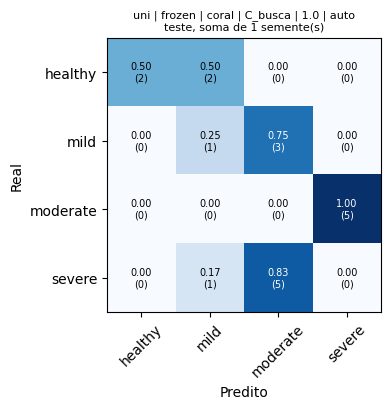

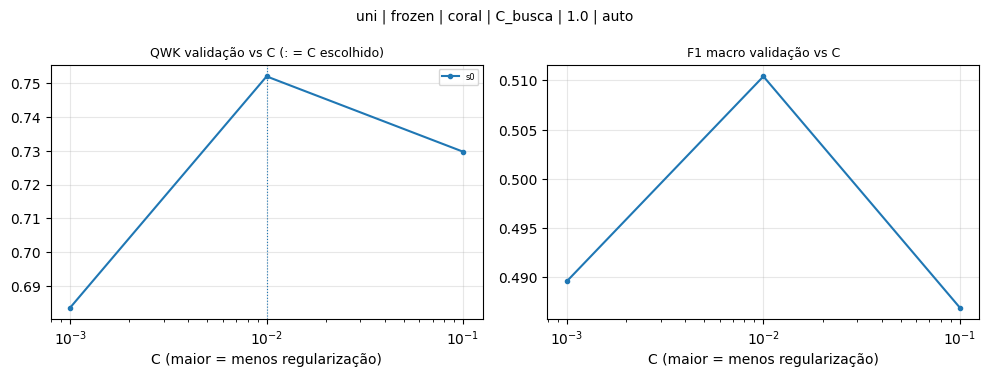

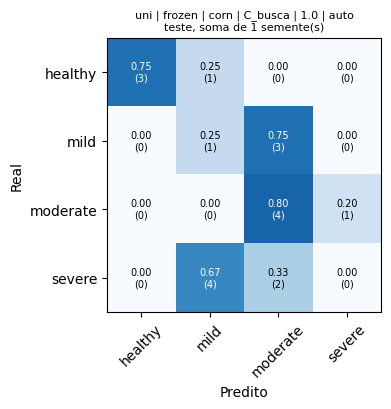

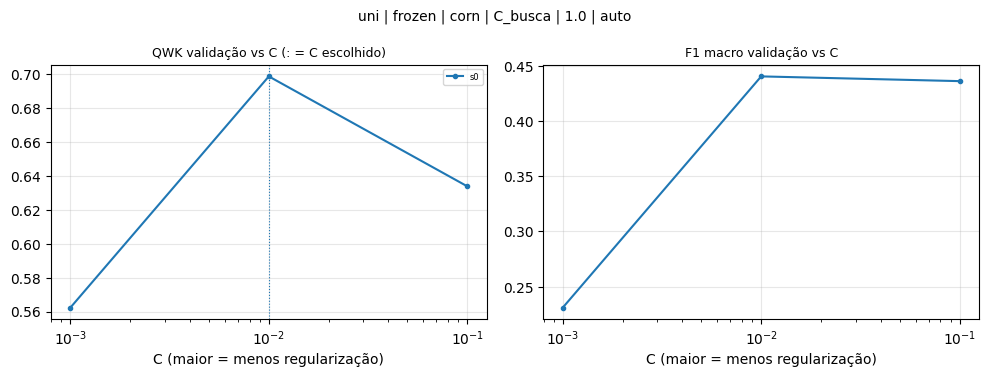

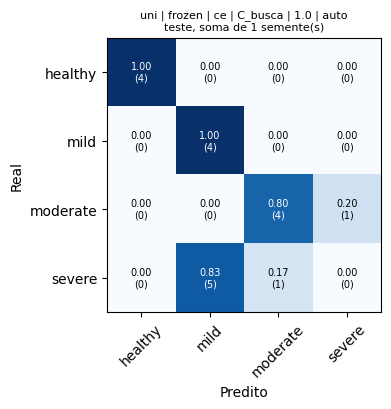

...

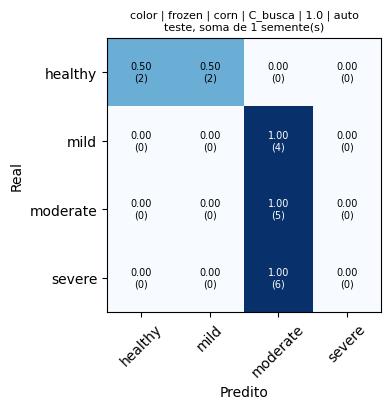

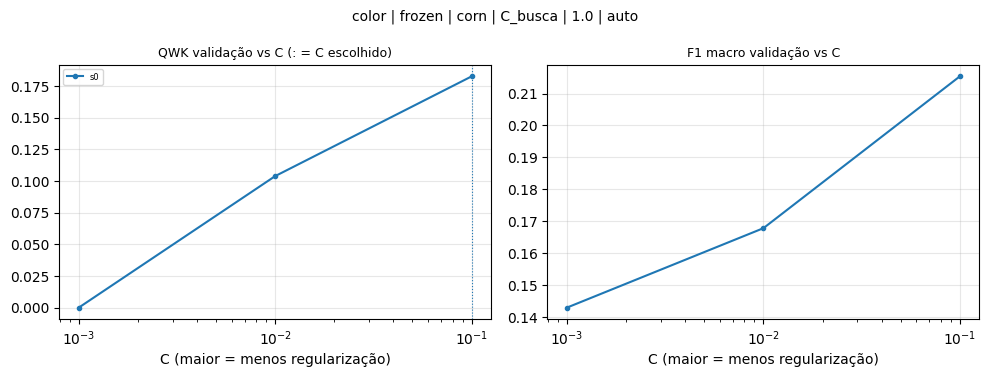

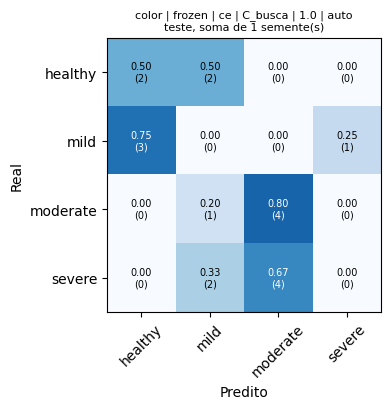

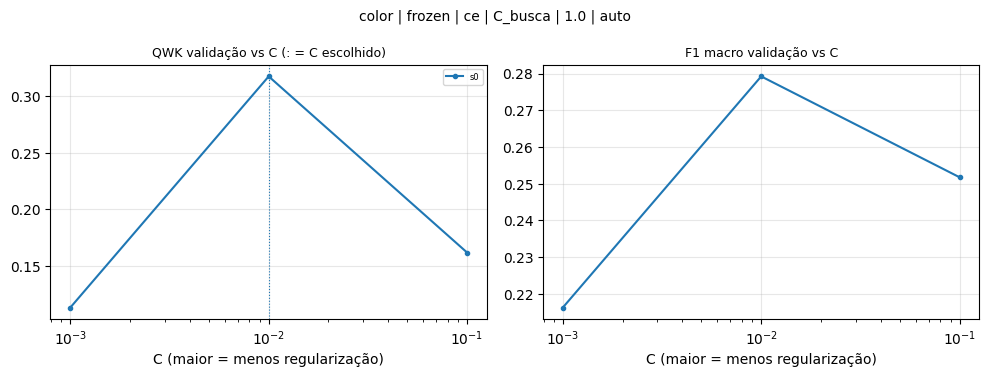

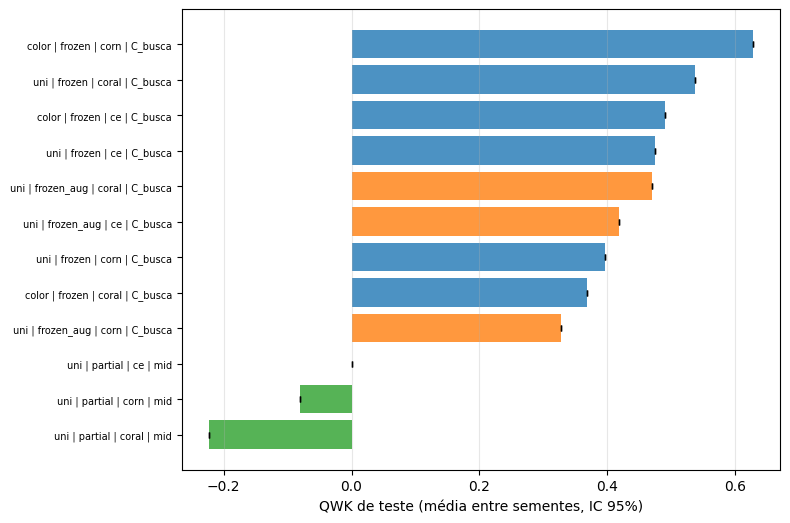


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/smoke_uni_20261010_204151
[fase 0_smoke] concluída em 2.9 min

##########################################################################################
# FASE 1_frozen_baselines | uni | run 'bateria_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"
5,5,311,68.2,75,"[76, 82, 77, 76]",101,22.1,22,"[26, 25, 25, 25]",44,9.6,11,"[12, 7, 12, 13]"
6,6,331,72.6,75,"[82, 89, 83, 77]",78,17.1,22,"[19, 16, 18, 25]",47,10.3,11,"[13, 9, 13, 12]"
7,7,321,70.4,75,"[76, 88, 78, 79]",92,20.2,22,"[29, 18, 22, 23]",43,9.4,11,"[9, 8, 14, 12]"
8,8,316,69.3,75,"[81, 83, 81, 71]",87,19.1,22,"[18, 20, 19, 30]",53,11.6,11,"[15, 11, 14, 13]"
9,9,299,65.6,75,"[76, 74, 79, 70]",101,22.1,22,"[25, 25, 23, 28]",56,12.3,11,"[13, 15, 12, 16]"


[retomada] 200 execução(ões) já salvas em bateria_uni serão puladas
[plano] 9 cenário(s), 90 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
0,uni,frozen,coral,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,2.6991,NaN,NaN,0.8325,0.5720,0.5769,0.5800,0.8630,0.4200,0.8365
1,uni,frozen,coral,C_busca,1.0,auto,1,extracao_embeddings,64.0,NaN,...,3.0759,NaN,NaN,0.8426,0.7438,0.7276,0.7115,0.8725,0.2885,0.8358
2,uni,frozen,coral,C_busca,1.0,auto,2,extracao_embeddings,64.0,NaN,...,5.2194,NaN,NaN,0.7976,0.6147,0.6042,0.5854,0.7891,0.4390,0.7999
3,uni,frozen,coral,C_busca,1.0,auto,3,extracao_embeddings,64.0,NaN,...,2.3079,NaN,NaN,0.7277,0.6235,0.6395,0.6279,0.8672,0.4651,0.8038
4,uni,frozen,coral,C_busca,1.0,auto,4,extracao_embeddings,64.0,NaN,...,1.6556,NaN,NaN,0.7307,0.6448,0.6322,0.5870,0.7769,0.4565,0.8552
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,color,frozen,ce,C_busca,1.0,auto,5,extracao_embeddings,NaN,NaN,...,0.4196,NaN,NaN,0.3400,0.5287,0.5877,0.5455,0.8059,0.7955,0.3944
86,color,frozen,ce,C_busca,1.0,auto,6,extracao_embeddings,NaN,NaN,...,0.9688,NaN,NaN,0.6943,0.6042,0.6651,0.6383,0.8736,0.4894,0.5735
87,color,frozen,ce,C_busca,1.0,auto,7,extracao_embeddings,NaN,NaN,...,0.5092,NaN,NaN,0.3638,0.5526,0.6002,0.5581,0.8178,0.7674,0.5756
88,color,frozen,ce,C_busca,1.0,auto,8,extracao_embeddings,NaN,NaN,...,0.3805,NaN,NaN,0.5613,0.5487,0.5457,0.5660,0.7493,0.6226,0.4394



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.027,NaN,0.066,0.8016 ± 0.0524,0.6238 ± 0.0703,0.6234 ± 0.0631,0.6096 ± 0.0669,0.8474 ± 0.0445,0.4107 ± 0.0763,0.7958 ± 0.0485
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.724,NaN,0.055,0.7941 ± 0.0707,0.6876 ± 0.0613,0.6908 ± 0.0586,0.6860 ± 0.0727,0.8798 ± 0.0437,0.3643 ± 0.0863,0.8065 ± 0.0693
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,...,5.139,NaN,0.001,0.8113 ± 0.0907,0.6946 ± 0.1070,0.7036 ± 0.0965,0.7017 ± 0.0942,0.8763 ± 0.0517,0.3463 ± 0.1225,0.8128 ± 0.0632
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.588,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,...,13.527,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.309,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.630,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.737,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.598,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,22.724,NaN,0.002,0.7995 ± 0.0633,0.6323 ± 0.0807,0.6328 ± 0.0824,0.6214 ± 0.0845,0.8462 ± 0.0447,0.4033 ± 0.0949,0.8045 ± 0.0573



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8016 [0.7525, 0.8371]","0.6238 [0.5699, 0.6668]","0.6234 [0.5816, 0.6779]","0.6096 [0.5621, 0.6630]","0.8474 [0.8207, 0.8782]","0.4107 [0.3500, 0.4671]"
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7941 [0.7335, 0.8402]","0.6876 [0.6366, 0.7353]","0.6908 [0.6509, 0.7435]","0.6860 [0.6358, 0.7405]","0.8798 [0.8526, 0.9135]","0.3643 [0.2956, 0.4275]"
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8113 [0.7592, 0.8550]","0.6946 [0.6471, 0.7425]","0.7036 [0.6670, 0.7539]","0.7017 [0.6563, 0.7529]","0.8763 [0.8479, 0.9131]","0.3463 [0.2851, 0.4044]"
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7995 [0.7476, 0.8381]","0.6323 [0.5714, 0.6762]","0.6328 [0.5861, 0.6856]","0.6214 [0.5693, 0.6763]","0.8462 [0.8184, 0.8764]","0.4033 [0.3364, 0.4615]"


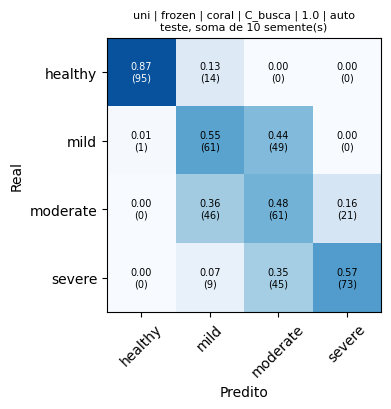

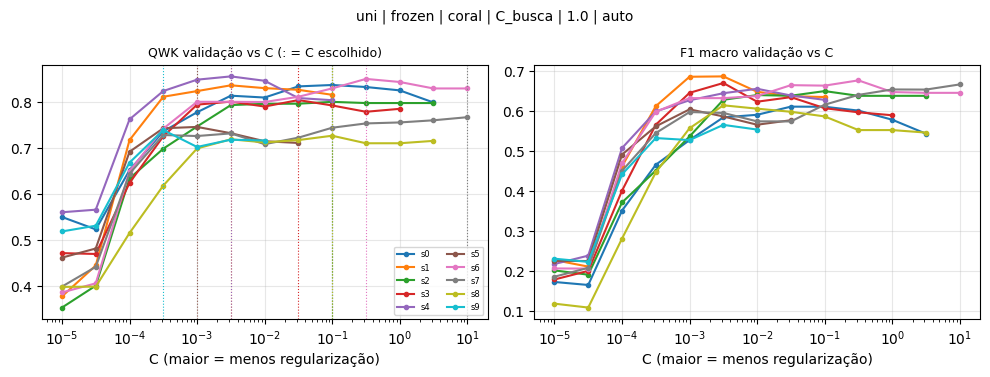

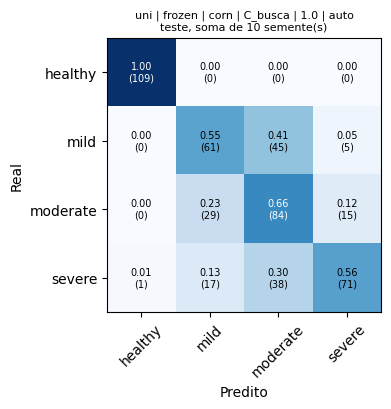

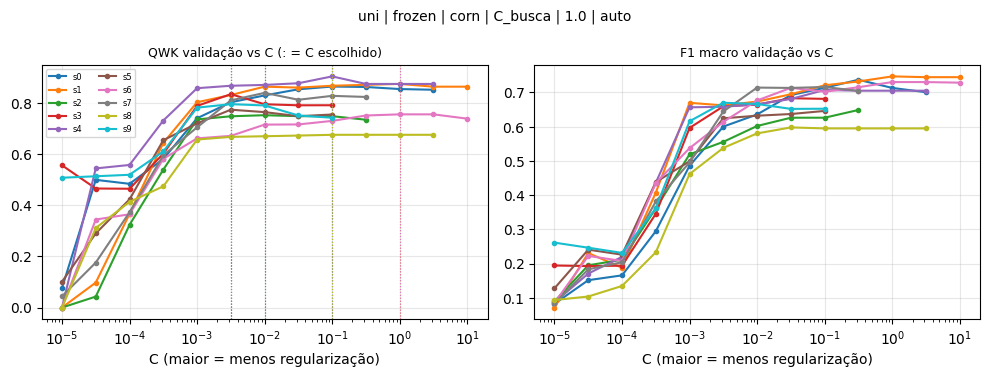

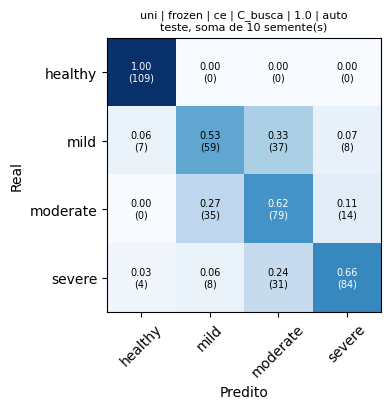

...

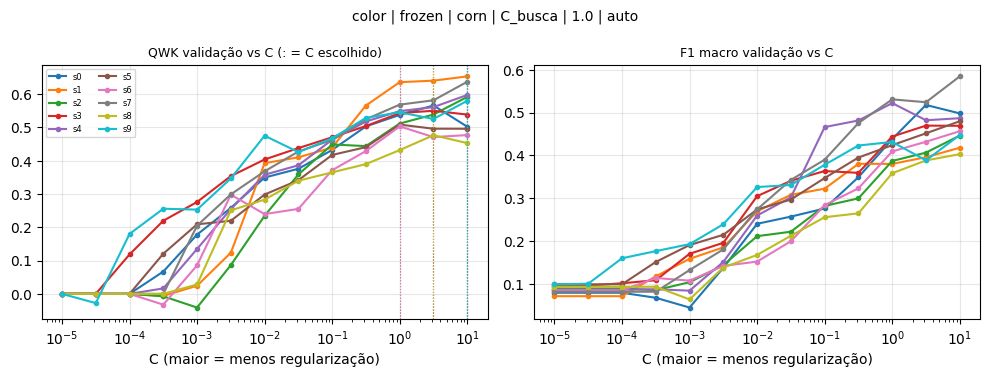

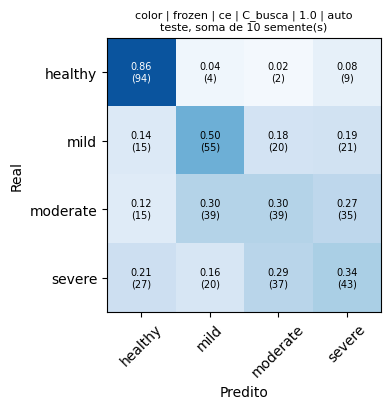

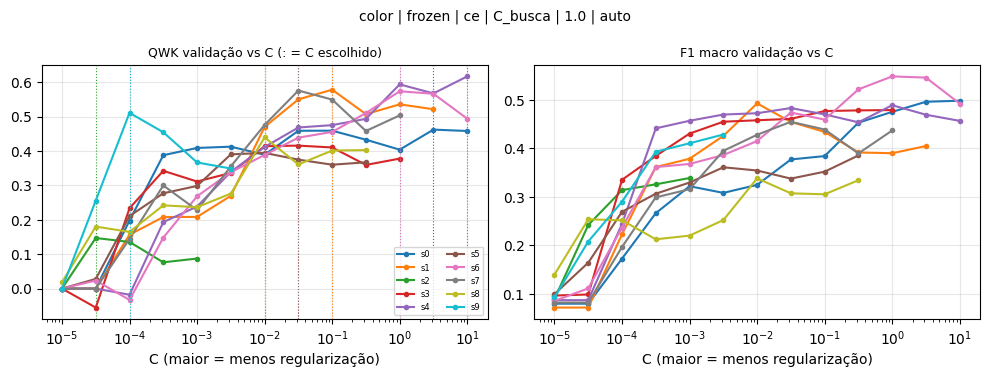

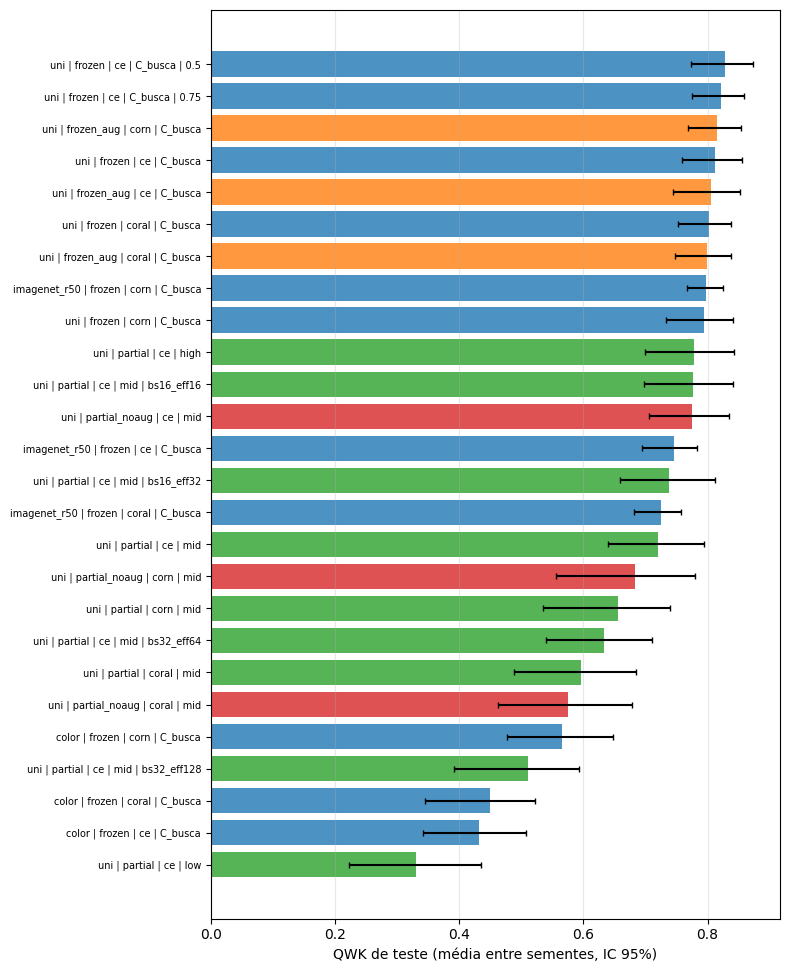

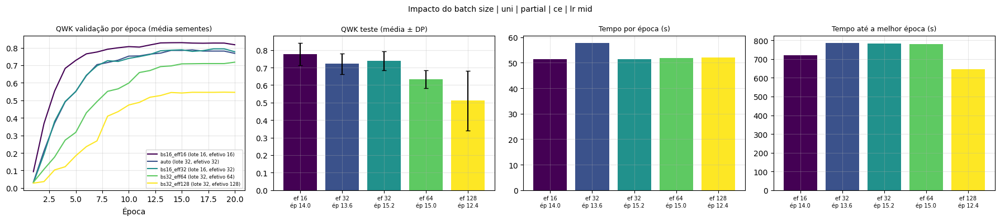


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_uni
[fase 1_frozen_baselines] concluída em 6.8 min

##########################################################################################
# FASE 2_frozen_aug | uni | run 'bateria_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"
5,5,311,68.2,75,"[76, 82, 77, 76]",101,22.1,22,"[26, 25, 25, 25]",44,9.6,11,"[12, 7, 12, 13]"
6,6,331,72.6,75,"[82, 89, 83, 77]",78,17.1,22,"[19, 16, 18, 25]",47,10.3,11,"[13, 9, 13, 12]"
7,7,321,70.4,75,"[76, 88, 78, 79]",92,20.2,22,"[29, 18, 22, 23]",43,9.4,11,"[9, 8, 14, 12]"
8,8,316,69.3,75,"[81, 83, 81, 71]",87,19.1,22,"[18, 20, 19, 30]",53,11.6,11,"[15, 11, 14, 13]"
9,9,299,65.6,75,"[76, 74, 79, 70]",101,22.1,22,"[25, 25, 23, 28]",56,12.3,11,"[13, 15, 12, 16]"


[retomada] 200 execução(ões) já salvas em bateria_uni serão puladas
[plano] 3 cenário(s), 30 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
90,uni,frozen_aug,coral,C_busca,1.0,auto,0,extracao_embeddings,64.0,NaN,...,41.4598,NaN,NaN,0.8216,0.6076,0.6121,0.6200,0.8354,0.4000,0.8324
91,uni,frozen_aug,coral,C_busca,1.0,auto,1,extracao_embeddings,64.0,NaN,...,17.4175,NaN,NaN,0.8413,0.7381,0.7222,0.7115,0.8630,0.2885,0.8566
92,uni,frozen_aug,coral,C_busca,1.0,auto,2,extracao_embeddings,64.0,NaN,...,21.8330,NaN,NaN,0.7602,0.5902,0.5764,0.5610,0.7885,0.4878,0.8386
93,uni,frozen_aug,coral,C_busca,1.0,auto,3,extracao_embeddings,64.0,NaN,...,16.0586,NaN,NaN,0.7466,0.6711,0.6850,0.6744,0.8734,0.4186,0.8365
94,uni,frozen_aug,coral,C_busca,1.0,auto,4,extracao_embeddings,64.0,NaN,...,20.7070,NaN,NaN,0.6854,0.5751,0.5532,0.5217,0.7727,0.5217,0.8529
95,uni,frozen_aug,coral,C_busca,1.0,auto,5,extracao_embeddings,64.0,NaN,...,10.8426,NaN,NaN,0.7540,0.4850,0.5034,0.5000,0.8243,0.5227,0.7851
96,uni,frozen_aug,coral,C_busca,1.0,auto,6,extracao_embeddings,64.0,NaN,...,29.8387,NaN,NaN,0.9095,0.7586,0.7767,0.7660,0.9243,0.2340,0.8462
97,uni,frozen_aug,coral,C_busca,1.0,auto,7,extracao_embeddings,64.0,NaN,...,19.6543,NaN,NaN,0.8281,0.6455,0.6567,0.6279,0.8774,0.3721,0.7673
98,uni,frozen_aug,coral,C_busca,1.0,auto,8,extracao_embeddings,64.0,NaN,...,40.3253,NaN,NaN,0.8357,0.6599,0.6534,0.6604,0.8670,0.3585,0.6841
99,uni,frozen_aug,coral,C_busca,1.0,auto,9,extracao_embeddings,64.0,NaN,...,9.1027,NaN,NaN,0.8123,0.5921,0.5885,0.5714,0.8363,0.4286,0.7449



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.027,NaN,0.066,0.8016 ± 0.0524,0.6238 ± 0.0703,0.6234 ± 0.0631,0.6096 ± 0.0669,0.8474 ± 0.0445,0.4107 ± 0.0763,0.7958 ± 0.0485
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.724,NaN,0.055,0.7941 ± 0.0707,0.6876 ± 0.0613,0.6908 ± 0.0586,0.6860 ± 0.0727,0.8798 ± 0.0437,0.3643 ± 0.0863,0.8065 ± 0.0693
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,...,5.139,NaN,0.001,0.8113 ± 0.0907,0.6946 ± 0.1070,0.7036 ± 0.0965,0.7017 ± 0.0942,0.8763 ± 0.0517,0.3463 ± 0.1225,0.8128 ± 0.0632
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.588,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,...,13.527,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.309,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.630,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.737,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.598,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,22.724,NaN,0.002,0.7995 ± 0.0633,0.6323 ± 0.0807,0.6328 ± 0.0824,0.6214 ± 0.0845,0.8462 ± 0.0447,0.4033 ± 0.0949,0.8045 ± 0.0573



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8016 [0.7525, 0.8371]","0.6238 [0.5699, 0.6668]","0.6234 [0.5816, 0.6779]","0.6096 [0.5621, 0.6630]","0.8474 [0.8207, 0.8782]","0.4107 [0.3500, 0.4671]"
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7941 [0.7335, 0.8402]","0.6876 [0.6366, 0.7353]","0.6908 [0.6509, 0.7435]","0.6860 [0.6358, 0.7405]","0.8798 [0.8526, 0.9135]","0.3643 [0.2956, 0.4275]"
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8113 [0.7592, 0.8550]","0.6946 [0.6471, 0.7425]","0.7036 [0.6670, 0.7539]","0.7017 [0.6563, 0.7529]","0.8763 [0.8479, 0.9131]","0.3463 [0.2851, 0.4044]"
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7995 [0.7476, 0.8381]","0.6323 [0.5714, 0.6762]","0.6328 [0.5861, 0.6856]","0.6214 [0.5693, 0.6763]","0.8462 [0.8184, 0.8764]","0.4033 [0.3364, 0.4615]"


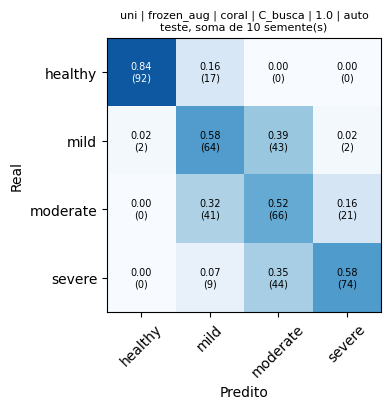

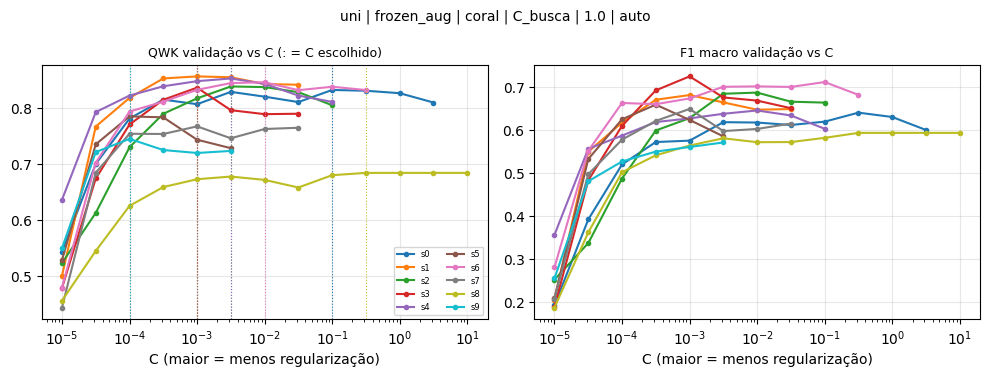

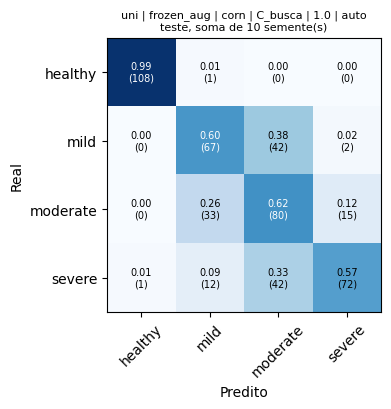

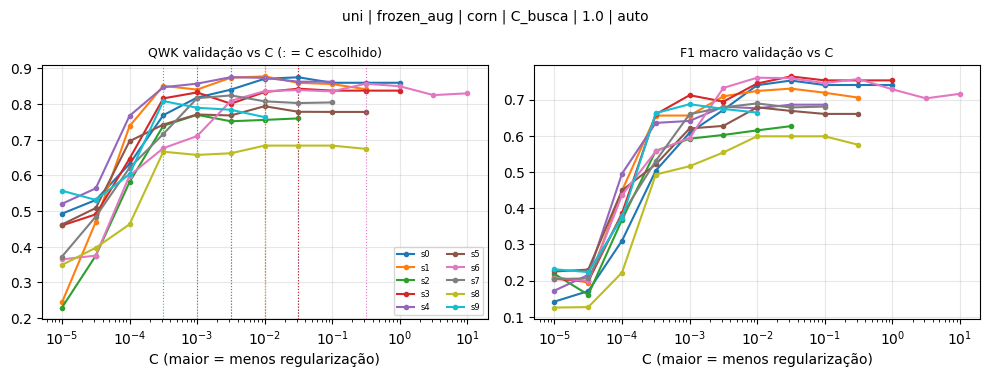

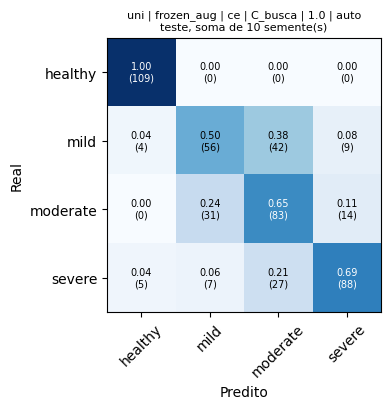

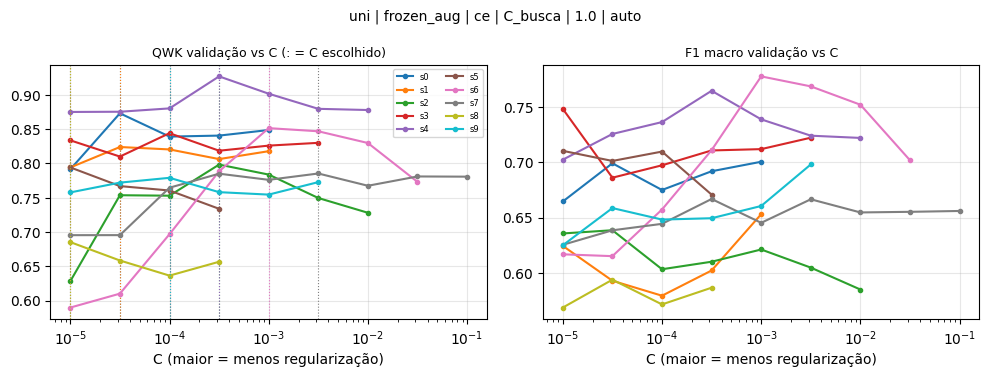

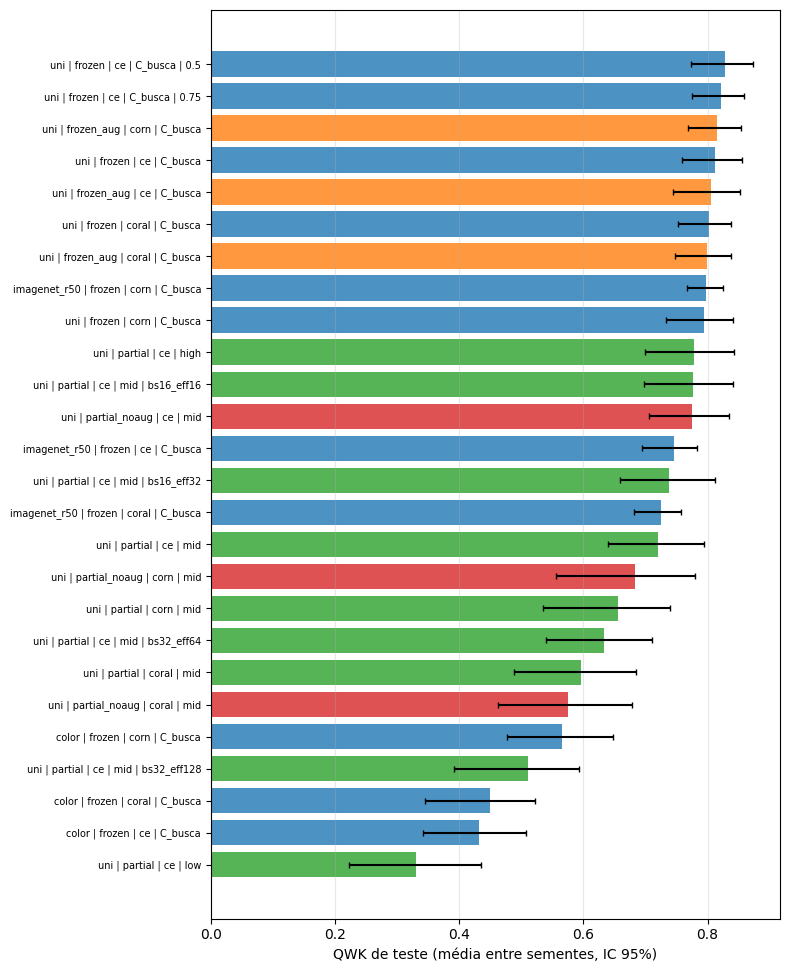

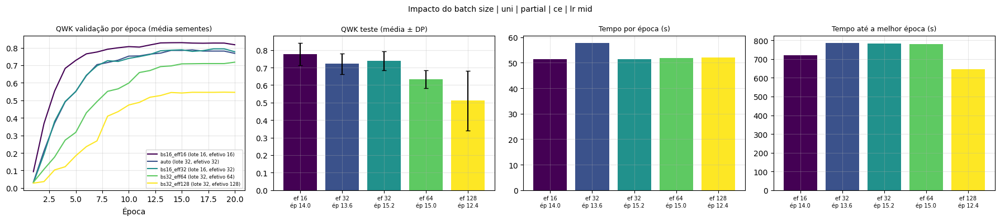


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_uni
[fase 2_frozen_aug] concluída em 3.8 min

##########################################################################################
# FASE 3_partial | uni | run 'bateria_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 200 execução(ões) já salvas em bateria_uni serão puladas
[plano] 3 cenário(s), 15 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
120,uni,partial,coral,mid,1.0,auto,0,treino,32.0,1.0,...,925.3192,3.0037,0.0,0.6799,0.3402,0.5000,0.4800,0.7888,0.7200,0.7530
121,uni,partial,coral,mid,1.0,auto,1,treino,32.0,1.0,...,742.5530,3.0044,0.0,0.5181,0.2677,0.4615,0.3654,0.8208,0.9038,0.7921
122,uni,partial,coral,mid,1.0,auto,2,treino,32.0,1.0,...,705.3325,3.0033,0.0,0.7142,0.3318,0.5000,0.4878,0.7788,0.6585,0.6309
123,uni,partial,coral,mid,1.0,auto,3,treino,32.0,1.0,...,756.5783,3.0033,0.0,0.7124,0.3346,0.4792,0.5116,0.7321,0.6512,0.6973
124,uni,partial,coral,mid,1.0,auto,4,treino,32.0,1.0,...,1162.4756,3.0033,0.0,0.3536,0.2645,0.4375,0.3696,0.7807,1.0870,0.7865
125,uni,partial,corn,mid,1.0,auto,0,treino,32.0,1.0,...,1153.7155,3.0034,0.0,0.7711,0.6420,0.6402,0.6400,0.9054,0.4000,0.6996
126,uni,partial,corn,mid,1.0,auto,1,treino,32.0,1.0,...,1034.9283,3.0034,0.0,0.5815,0.4991,0.5131,0.5385,0.9075,0.5192,0.8402
127,uni,partial,corn,mid,1.0,auto,2,treino,32.0,1.0,...,1173.8854,3.0034,0.0,0.6720,0.4280,0.4340,0.4390,0.8903,0.5610,0.6767
128,uni,partial,corn,mid,1.0,auto,3,treino,32.0,1.0,...,1104.0170,3.0034,0.0,0.7627,0.5283,0.5985,0.5814,0.8855,0.4419,0.7911
129,uni,partial,corn,mid,1.0,auto,4,treino,32.0,1.0,...,1160.0388,3.0034,0.0,0.4911,0.5226,0.5674,0.5217,0.8303,0.6087,0.8136



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.027,NaN,0.066,0.8016 ± 0.0524,0.6238 ± 0.0703,0.6234 ± 0.0631,0.6096 ± 0.0669,0.8474 ± 0.0445,0.4107 ± 0.0763,0.7958 ± 0.0485
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.724,NaN,0.055,0.7941 ± 0.0707,0.6876 ± 0.0613,0.6908 ± 0.0586,0.6860 ± 0.0727,0.8798 ± 0.0437,0.3643 ± 0.0863,0.8065 ± 0.0693
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,...,5.139,NaN,0.001,0.8113 ± 0.0907,0.6946 ± 0.1070,0.7036 ± 0.0965,0.7017 ± 0.0942,0.8763 ± 0.0517,0.3463 ± 0.1225,0.8128 ± 0.0632
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.588,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,...,13.527,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.309,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.630,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.737,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.598,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,22.724,NaN,0.002,0.7995 ± 0.0633,0.6323 ± 0.0807,0.6328 ± 0.0824,0.6214 ± 0.0845,0.8462 ± 0.0447,0.4033 ± 0.0949,0.8045 ± 0.0573



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8016 [0.7525, 0.8371]","0.6238 [0.5699, 0.6668]","0.6234 [0.5816, 0.6779]","0.6096 [0.5621, 0.6630]","0.8474 [0.8207, 0.8782]","0.4107 [0.3500, 0.4671]"
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7941 [0.7335, 0.8402]","0.6876 [0.6366, 0.7353]","0.6908 [0.6509, 0.7435]","0.6860 [0.6358, 0.7405]","0.8798 [0.8526, 0.9135]","0.3643 [0.2956, 0.4275]"
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8113 [0.7592, 0.8550]","0.6946 [0.6471, 0.7425]","0.7036 [0.6670, 0.7539]","0.7017 [0.6563, 0.7529]","0.8763 [0.8479, 0.9131]","0.3463 [0.2851, 0.4044]"
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7995 [0.7476, 0.8381]","0.6323 [0.5714, 0.6762]","0.6328 [0.5861, 0.6856]","0.6214 [0.5693, 0.6763]","0.8462 [0.8184, 0.8764]","0.4033 [0.3364, 0.4615]"


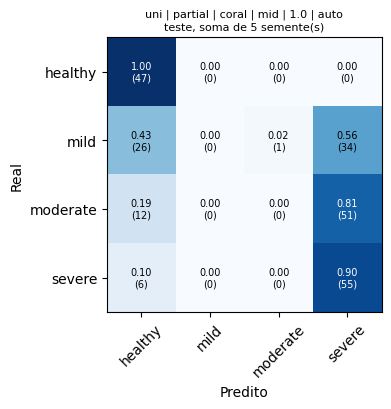

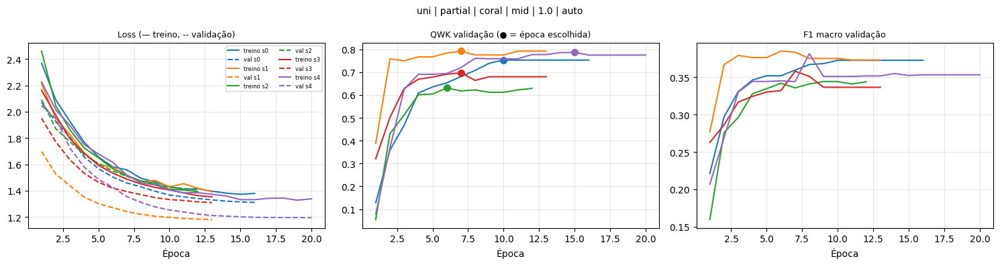

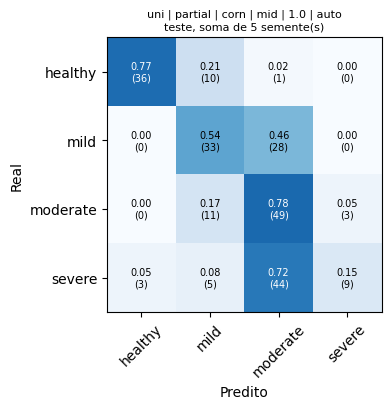

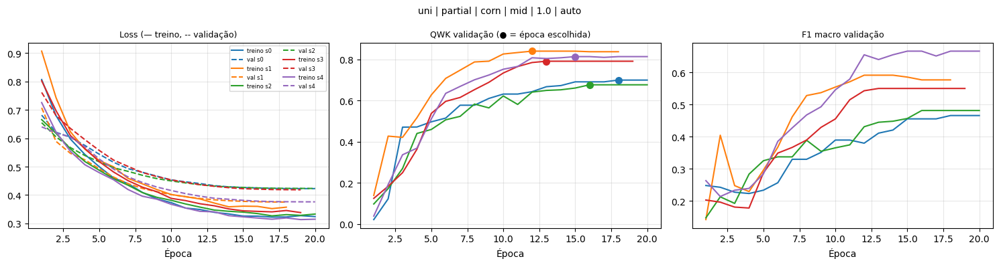

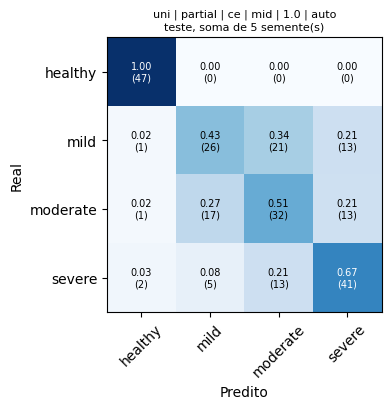

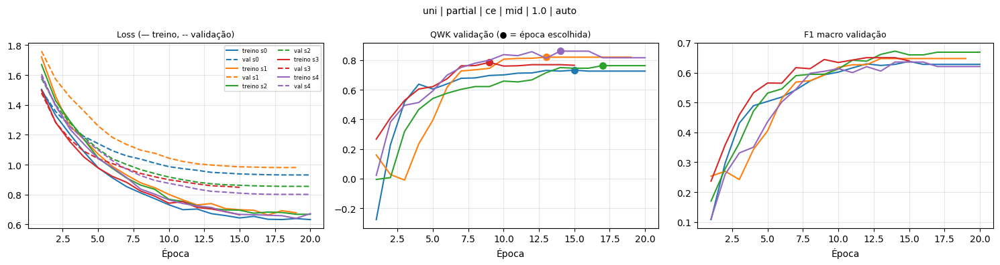

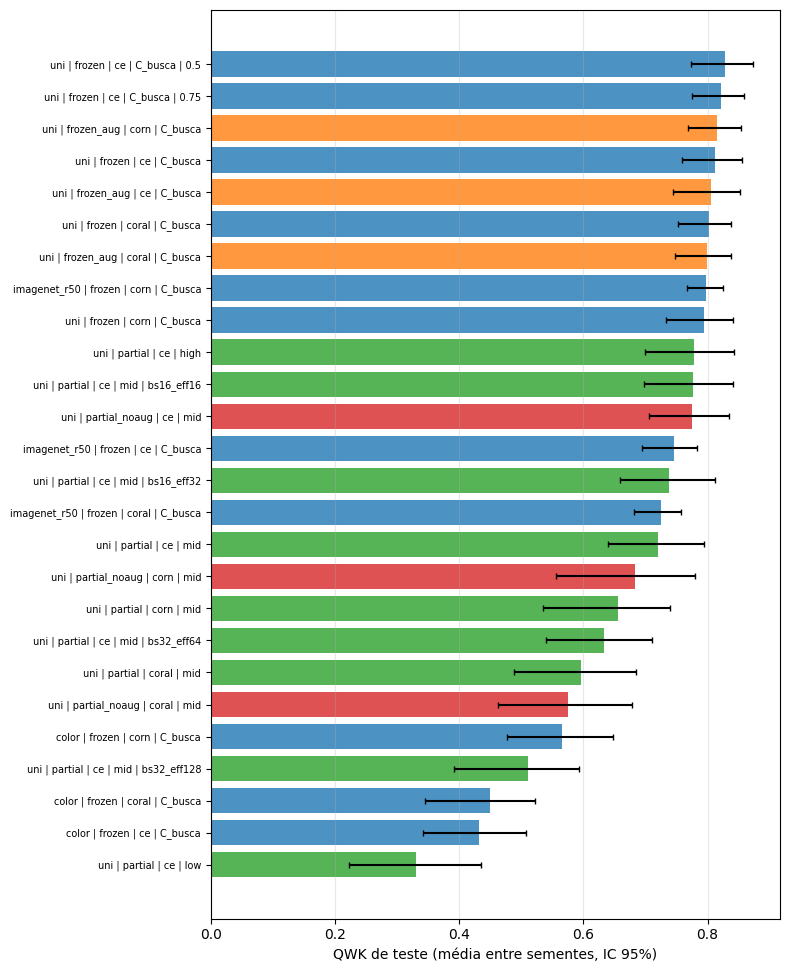

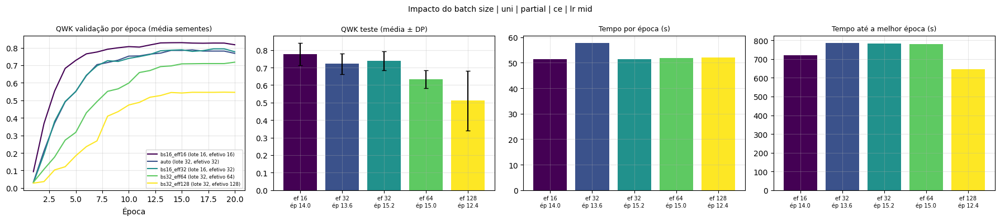


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_uni
[fase 3_partial] concluída em 3.6 min

##########################################################################################
# FASE 4_ablation_aug | uni | run 'bateria_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 200 execução(ões) já salvas em bateria_uni serão puladas
[plano] 3 cenário(s), 15 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
135,uni,partial_noaug,coral,mid,1.0,auto,0,treino,32.0,1.0,...,788.9867,3.0037,0.0,0.6446,0.3215,0.4792,0.4600,0.7660,0.7600,0.6618
136,uni,partial_noaug,coral,mid,1.0,auto,1,treino,32.0,1.0,...,959.9294,3.0044,0.0,0.4920,0.2632,0.4615,0.3654,0.8258,0.9423,0.8006
137,uni,partial_noaug,coral,mid,1.0,auto,2,treino,32.0,1.0,...,983.0462,3.0033,0.0,0.7383,0.3288,0.5000,0.4878,0.7986,0.6341,0.6603
138,uni,partial_noaug,coral,mid,1.0,auto,3,treino,32.0,1.0,...,972.9500,3.0033,0.0,0.6152,0.3042,0.4375,0.4651,0.7740,0.7674,0.6961
139,uni,partial_noaug,coral,mid,1.0,auto,4,treino,32.0,1.0,...,914.7593,3.0033,0.0,0.3850,0.2583,0.4375,0.3696,0.7878,1.0652,0.7725
140,uni,partial_noaug,corn,mid,1.0,auto,0,treino,32.0,1.0,...,1135.9459,3.0034,0.0,0.8058,0.6272,0.6402,0.6400,0.9139,0.3800,0.7377
141,uni,partial_noaug,corn,mid,1.0,auto,1,treino,32.0,1.0,...,1125.8985,3.0034,0.0,0.5813,0.5943,0.6314,0.6154,0.9279,0.4808,0.8295
142,uni,partial_noaug,corn,mid,1.0,auto,2,treino,32.0,1.0,...,1156.9601,3.0034,0.0,0.7930,0.6088,0.5972,0.5854,0.9125,0.4146,0.7301
143,uni,partial_noaug,corn,mid,1.0,auto,3,treino,32.0,1.0,...,1145.9910,3.0034,0.0,0.7578,0.5656,0.6490,0.6279,0.8832,0.4186,0.7909
144,uni,partial_noaug,corn,mid,1.0,auto,4,treino,32.0,1.0,...,1149.9208,3.0034,0.0,0.4810,0.5053,0.5447,0.5000,0.8370,0.6304,0.8541



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.027,NaN,0.066,0.8016 ± 0.0524,0.6238 ± 0.0703,0.6234 ± 0.0631,0.6096 ± 0.0669,0.8474 ± 0.0445,0.4107 ± 0.0763,0.7958 ± 0.0485
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.724,NaN,0.055,0.7941 ± 0.0707,0.6876 ± 0.0613,0.6908 ± 0.0586,0.6860 ± 0.0727,0.8798 ± 0.0437,0.3643 ± 0.0863,0.8065 ± 0.0693
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,...,5.139,NaN,0.001,0.8113 ± 0.0907,0.6946 ± 0.1070,0.7036 ± 0.0965,0.7017 ± 0.0942,0.8763 ± 0.0517,0.3463 ± 0.1225,0.8128 ± 0.0632
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.588,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,...,13.527,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.309,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.630,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.737,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.598,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,22.724,NaN,0.002,0.7995 ± 0.0633,0.6323 ± 0.0807,0.6328 ± 0.0824,0.6214 ± 0.0845,0.8462 ± 0.0447,0.4033 ± 0.0949,0.8045 ± 0.0573



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8016 [0.7525, 0.8371]","0.6238 [0.5699, 0.6668]","0.6234 [0.5816, 0.6779]","0.6096 [0.5621, 0.6630]","0.8474 [0.8207, 0.8782]","0.4107 [0.3500, 0.4671]"
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7941 [0.7335, 0.8402]","0.6876 [0.6366, 0.7353]","0.6908 [0.6509, 0.7435]","0.6860 [0.6358, 0.7405]","0.8798 [0.8526, 0.9135]","0.3643 [0.2956, 0.4275]"
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8113 [0.7592, 0.8550]","0.6946 [0.6471, 0.7425]","0.7036 [0.6670, 0.7539]","0.7017 [0.6563, 0.7529]","0.8763 [0.8479, 0.9131]","0.3463 [0.2851, 0.4044]"
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7995 [0.7476, 0.8381]","0.6323 [0.5714, 0.6762]","0.6328 [0.5861, 0.6856]","0.6214 [0.5693, 0.6763]","0.8462 [0.8184, 0.8764]","0.4033 [0.3364, 0.4615]"


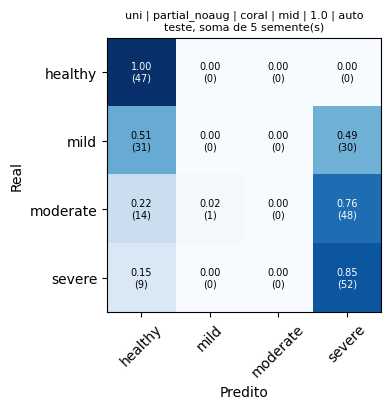

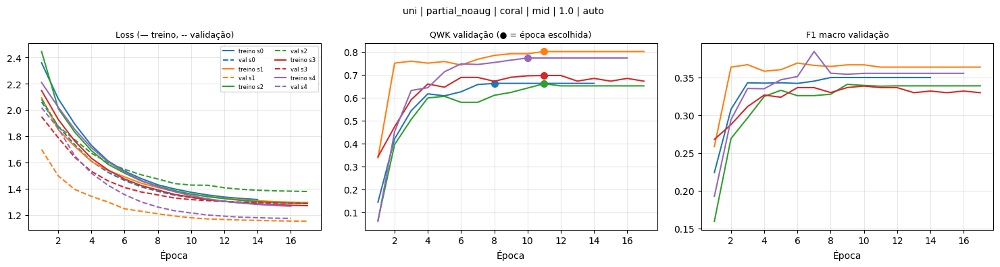

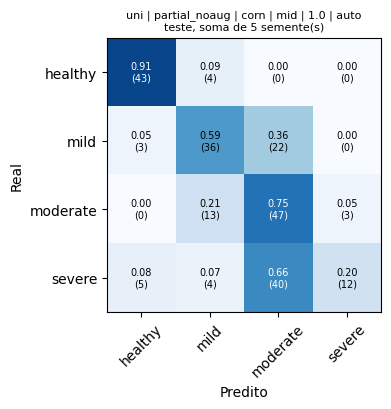

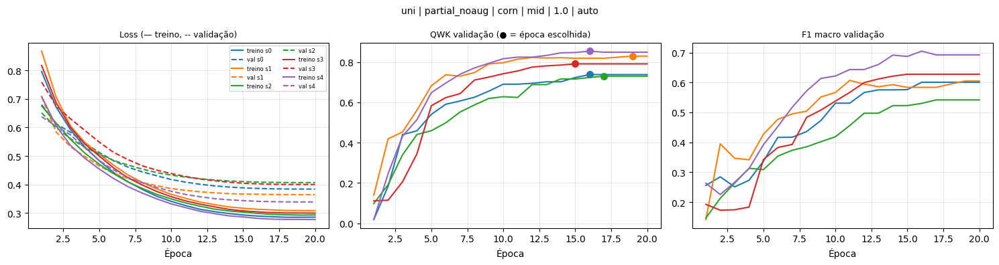

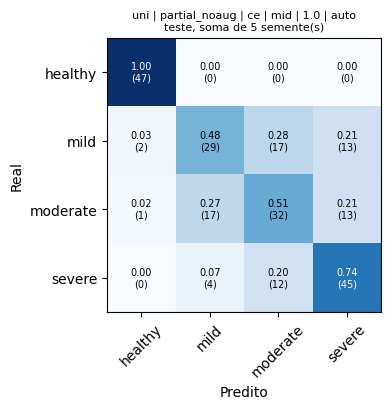

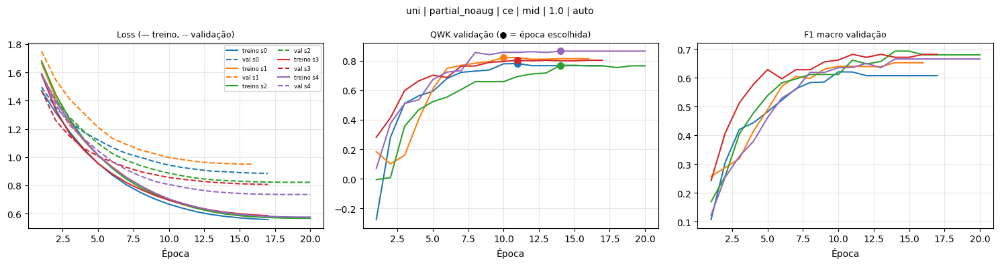

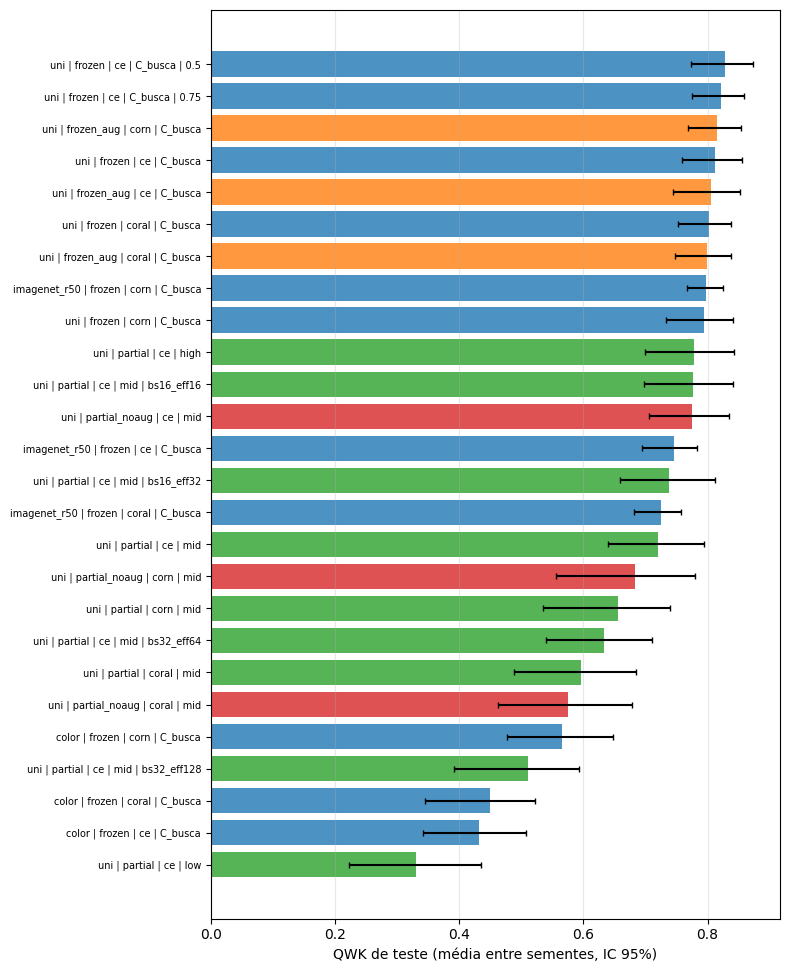

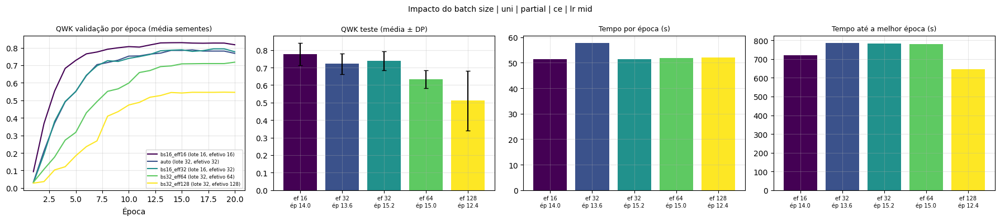


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_uni
[fase 4_ablation_aug] concluída em 3.6 min
[seleção] QWK médio de VALIDAÇÃO por loss (uni, partial): {'ce': 0.7919, 'corn': 0.7642, 'coral': 0.732} -> ce

##########################################################################################
# FASE 5_lr | uni | run 'bateria_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 200 execução(ões) já salvas em bateria_uni serão puladas
[plano] 2 cenário(s), 10 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
150,uni,partial,ce,low,1.0,auto,0,treino,32.0,1.0,...,1145.0297,3.0038,0.0,0.3311,0.2906,0.3580,0.3400,0.5711,1.0000,0.3166
151,uni,partial,ce,low,1.0,auto,1,treino,32.0,1.0,...,398.3933,3.0045,0.0,0.2312,0.3013,0.3868,0.4615,0.5899,0.7692,0.1914
152,uni,partial,ce,low,1.0,auto,2,treino,32.0,1.0,...,1172.6410,3.0034,0.0,0.3486,0.3684,0.4201,0.3902,0.6306,0.9268,0.1127
153,uni,partial,ce,low,1.0,auto,3,treino,32.0,1.0,...,1163.3181,3.0034,0.0,0.2720,0.3372,0.3346,0.3256,0.6246,0.9070,0.4495
154,uni,partial,ce,low,1.0,auto,4,treino,32.0,1.0,...,1226.8424,5.5333,0.0,0.4659,0.3293,0.3326,0.3043,0.5898,0.8261,0.4196
155,uni,partial,ce,high,1.0,auto,0,treino,32.0,1.0,...,849.4283,5.5349,0.0,0.7171,0.5589,0.5871,0.5800,0.8048,0.5400,0.8038
156,uni,partial,ce,high,1.0,auto,1,treino,32.0,1.0,...,960.8455,5.5349,0.0,0.8434,0.7792,0.7714,0.7500,0.9395,0.2692,0.8561
157,uni,partial,ce,high,1.0,auto,2,treino,32.0,1.0,...,873.6281,5.5349,0.0,0.7845,0.6333,0.6528,0.6341,0.8554,0.4390,0.7823
158,uni,partial,ce,high,1.0,auto,3,treino,32.0,1.0,...,1153.1944,5.5349,0.0,0.7126,0.6458,0.6452,0.6512,0.8517,0.4651,0.8495
159,uni,partial,ce,high,1.0,auto,4,treino,32.0,1.0,...,992.9571,3.0046,0.0,0.8316,0.7429,0.7383,0.7174,0.8653,0.3043,0.8847



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.027,NaN,0.066,0.8016 ± 0.0524,0.6238 ± 0.0703,0.6234 ± 0.0631,0.6096 ± 0.0669,0.8474 ± 0.0445,0.4107 ± 0.0763,0.7958 ± 0.0485
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.724,NaN,0.055,0.7941 ± 0.0707,0.6876 ± 0.0613,0.6908 ± 0.0586,0.6860 ± 0.0727,0.8798 ± 0.0437,0.3643 ± 0.0863,0.8065 ± 0.0693
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,...,5.139,NaN,0.001,0.8113 ± 0.0907,0.6946 ± 0.1070,0.7036 ± 0.0965,0.7017 ± 0.0942,0.8763 ± 0.0517,0.3463 ± 0.1225,0.8128 ± 0.0632
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.588,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,...,13.527,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.309,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.630,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.737,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.598,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,22.724,NaN,0.002,0.7995 ± 0.0633,0.6323 ± 0.0807,0.6328 ± 0.0824,0.6214 ± 0.0845,0.8462 ± 0.0447,0.4033 ± 0.0949,0.8045 ± 0.0573



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8016 [0.7525, 0.8371]","0.6238 [0.5699, 0.6668]","0.6234 [0.5816, 0.6779]","0.6096 [0.5621, 0.6630]","0.8474 [0.8207, 0.8782]","0.4107 [0.3500, 0.4671]"
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7941 [0.7335, 0.8402]","0.6876 [0.6366, 0.7353]","0.6908 [0.6509, 0.7435]","0.6860 [0.6358, 0.7405]","0.8798 [0.8526, 0.9135]","0.3643 [0.2956, 0.4275]"
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8113 [0.7592, 0.8550]","0.6946 [0.6471, 0.7425]","0.7036 [0.6670, 0.7539]","0.7017 [0.6563, 0.7529]","0.8763 [0.8479, 0.9131]","0.3463 [0.2851, 0.4044]"
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7995 [0.7476, 0.8381]","0.6323 [0.5714, 0.6762]","0.6328 [0.5861, 0.6856]","0.6214 [0.5693, 0.6763]","0.8462 [0.8184, 0.8764]","0.4033 [0.3364, 0.4615]"


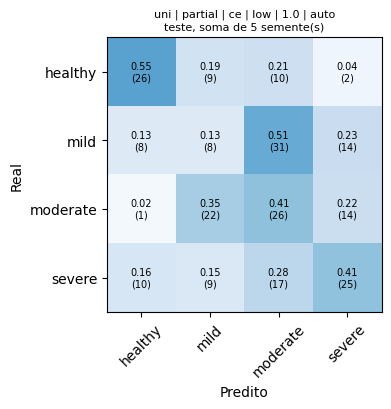

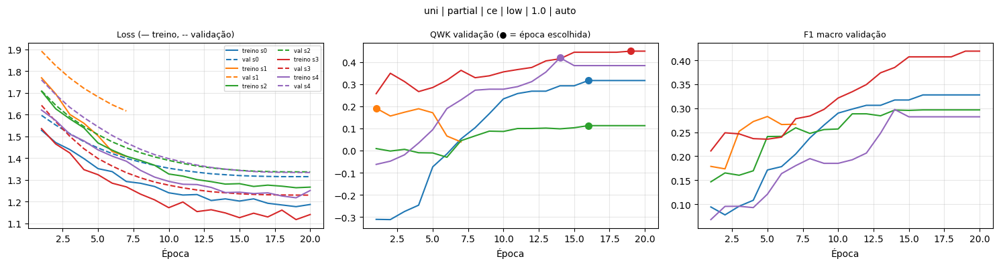

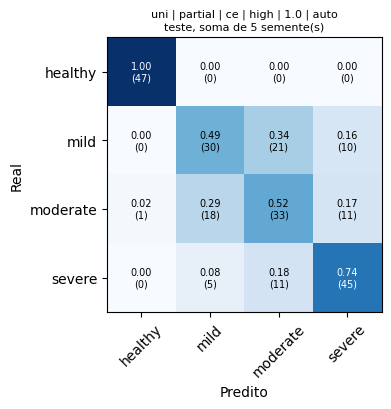

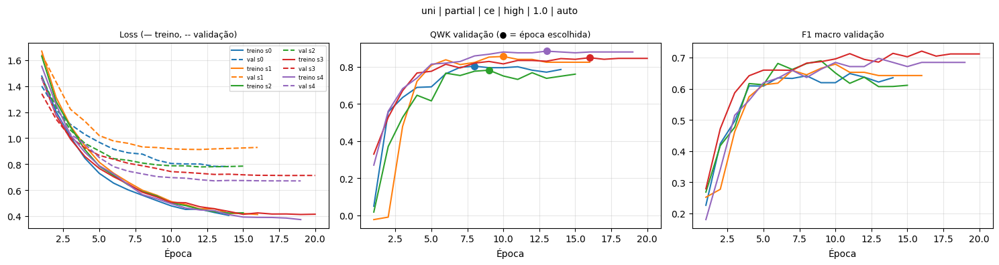

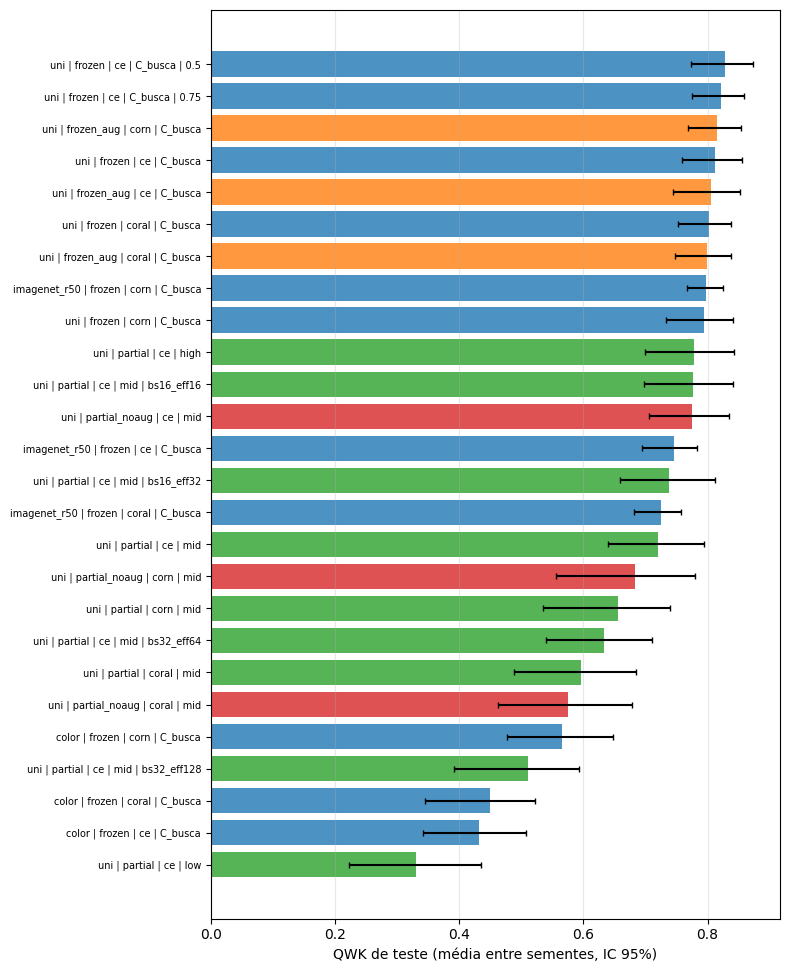

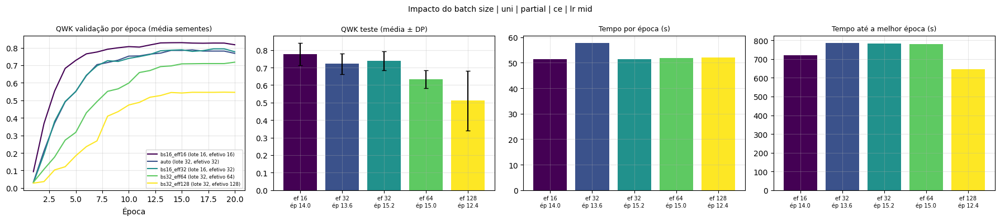


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_uni
[fase 5_lr] concluída em 3.6 min
[seleção] QWK médio de VALIDAÇÃO por loss (uni, partial): {'ce': 0.7919, 'corn': 0.7642, 'coral': 0.732} -> ce

##########################################################################################
# FASE 6_batch_size | uni | run 'bateria_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 200 execução(ões) já salvas em bateria_uni serão puladas
[plano] 4 cenário(s), 20 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
160,uni,partial,ce,mid,1.0,bs16_eff16,0,treino,16.0,1.0,...,1022.8772,2.9364,0.0,0.7171,0.5589,0.5871,0.5800,0.8083,0.5400,0.8007
161,uni,partial,ce,mid,1.0,bs16_eff16,1,treino,16.0,1.0,...,965.3793,2.9271,0.0,0.8434,0.7792,0.7714,0.7500,0.9315,0.2692,0.8561
162,uni,partial,ce,mid,1.0,bs16_eff16,2,treino,16.0,1.0,...,938.7661,2.9262,0.0,0.7845,0.6333,0.6528,0.6341,0.8685,0.4390,0.7840
163,uni,partial,ce,mid,1.0,bs16_eff16,3,treino,16.0,1.0,...,1033.7528,2.9274,0.0,0.7027,0.6194,0.6174,0.6279,0.8447,0.4884,0.8393
164,uni,partial,ce,mid,1.0,bs16_eff16,4,treino,16.0,1.0,...,929.0398,2.9330,0.0,0.8316,0.7429,0.7383,0.7174,0.8577,0.3043,0.8739
165,uni,partial,ce,mid,1.0,bs16_eff32,0,treino,16.0,2.0,...,1020.0282,2.9366,0.0,0.6512,0.4839,0.5371,0.5200,0.7849,0.6600,0.7405
166,uni,partial,ce,mid,1.0,bs16_eff32,1,treino,16.0,2.0,...,1015.0372,2.9275,0.0,0.7474,0.7321,0.7329,0.7115,0.9129,0.3462,0.8248
167,uni,partial,ce,mid,1.0,bs16_eff32,2,treino,16.0,2.0,...,1044.0573,2.9265,0.0,0.7965,0.6480,0.6736,0.6585,0.8514,0.4146,0.7665
168,uni,partial,ce,mid,1.0,bs16_eff32,3,treino,16.0,2.0,...,984.2852,2.9275,0.0,0.7545,0.5964,0.5947,0.6047,0.7999,0.4651,0.7825
169,uni,partial,ce,mid,1.0,bs16_eff32,4,treino,16.0,2.0,...,982.8905,2.9330,0.0,0.7427,0.7096,0.7174,0.6957,0.8428,0.3696,0.8604



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.027,NaN,0.066,0.8016 ± 0.0524,0.6238 ± 0.0703,0.6234 ± 0.0631,0.6096 ± 0.0669,0.8474 ± 0.0445,0.4107 ± 0.0763,0.7958 ± 0.0485
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.724,NaN,0.055,0.7941 ± 0.0707,0.6876 ± 0.0613,0.6908 ± 0.0586,0.6860 ± 0.0727,0.8798 ± 0.0437,0.3643 ± 0.0863,0.8065 ± 0.0693
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,...,5.139,NaN,0.001,0.8113 ± 0.0907,0.6946 ± 0.1070,0.7036 ± 0.0965,0.7017 ± 0.0942,0.8763 ± 0.0517,0.3463 ± 0.1225,0.8128 ± 0.0632
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.588,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,...,13.527,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.309,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.630,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.737,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.598,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,22.724,NaN,0.002,0.7995 ± 0.0633,0.6323 ± 0.0807,0.6328 ± 0.0824,0.6214 ± 0.0845,0.8462 ± 0.0447,0.4033 ± 0.0949,0.8045 ± 0.0573



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8016 [0.7525, 0.8371]","0.6238 [0.5699, 0.6668]","0.6234 [0.5816, 0.6779]","0.6096 [0.5621, 0.6630]","0.8474 [0.8207, 0.8782]","0.4107 [0.3500, 0.4671]"
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7941 [0.7335, 0.8402]","0.6876 [0.6366, 0.7353]","0.6908 [0.6509, 0.7435]","0.6860 [0.6358, 0.7405]","0.8798 [0.8526, 0.9135]","0.3643 [0.2956, 0.4275]"
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8113 [0.7592, 0.8550]","0.6946 [0.6471, 0.7425]","0.7036 [0.6670, 0.7539]","0.7017 [0.6563, 0.7529]","0.8763 [0.8479, 0.9131]","0.3463 [0.2851, 0.4044]"
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7995 [0.7476, 0.8381]","0.6323 [0.5714, 0.6762]","0.6328 [0.5861, 0.6856]","0.6214 [0.5693, 0.6763]","0.8462 [0.8184, 0.8764]","0.4033 [0.3364, 0.4615]"


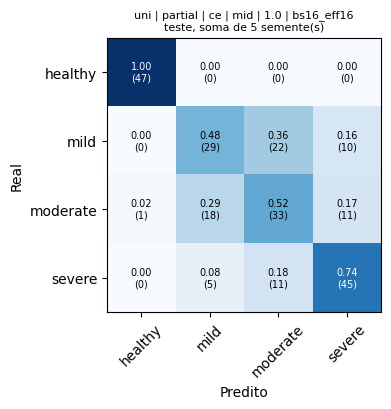

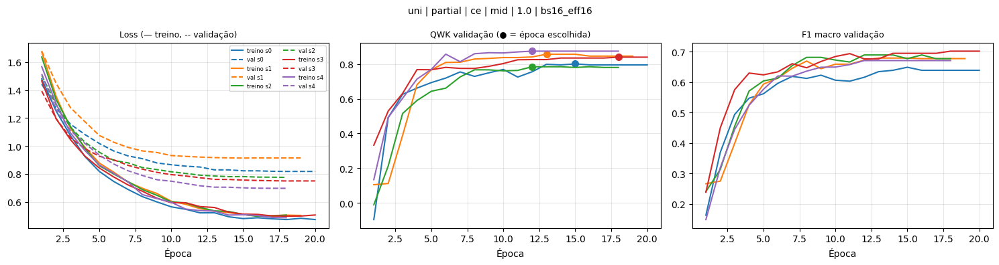

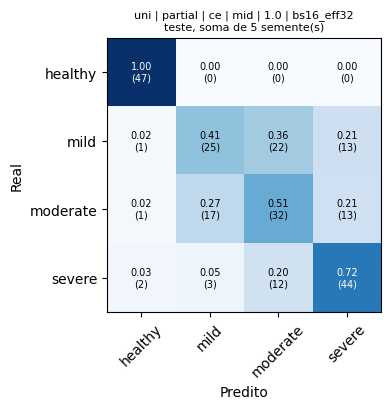

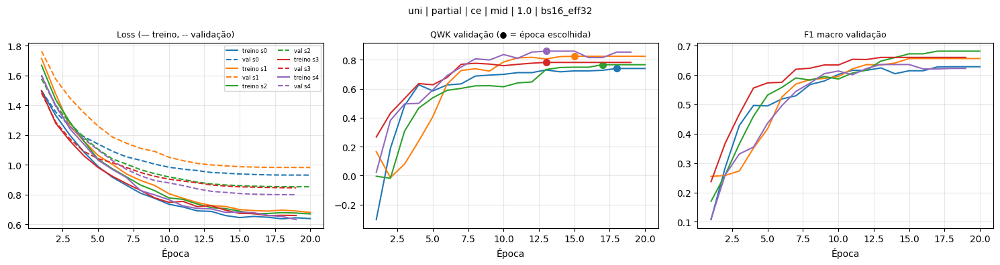

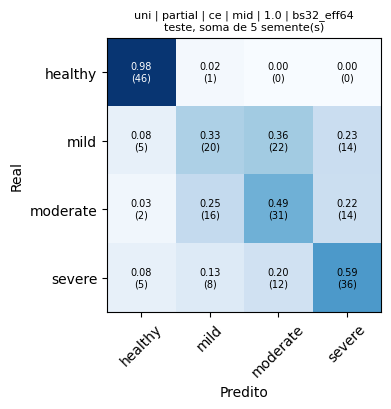

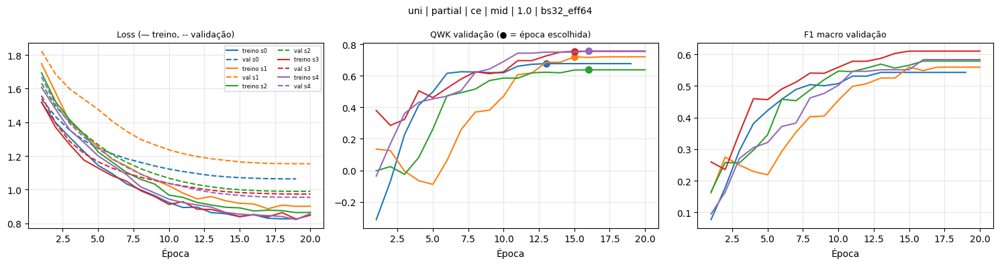

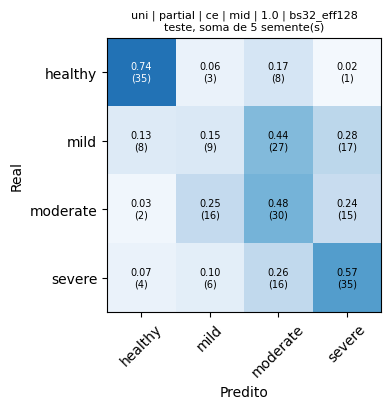

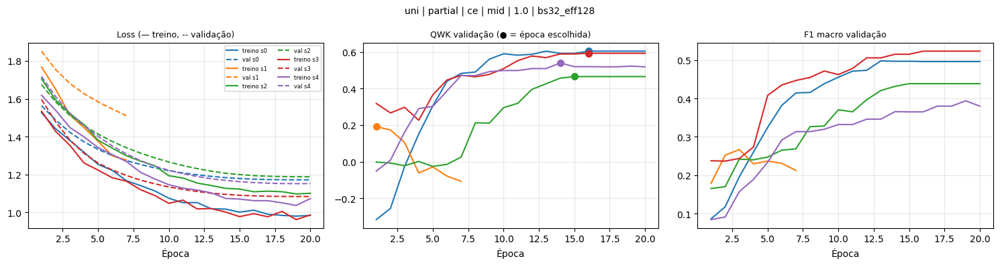

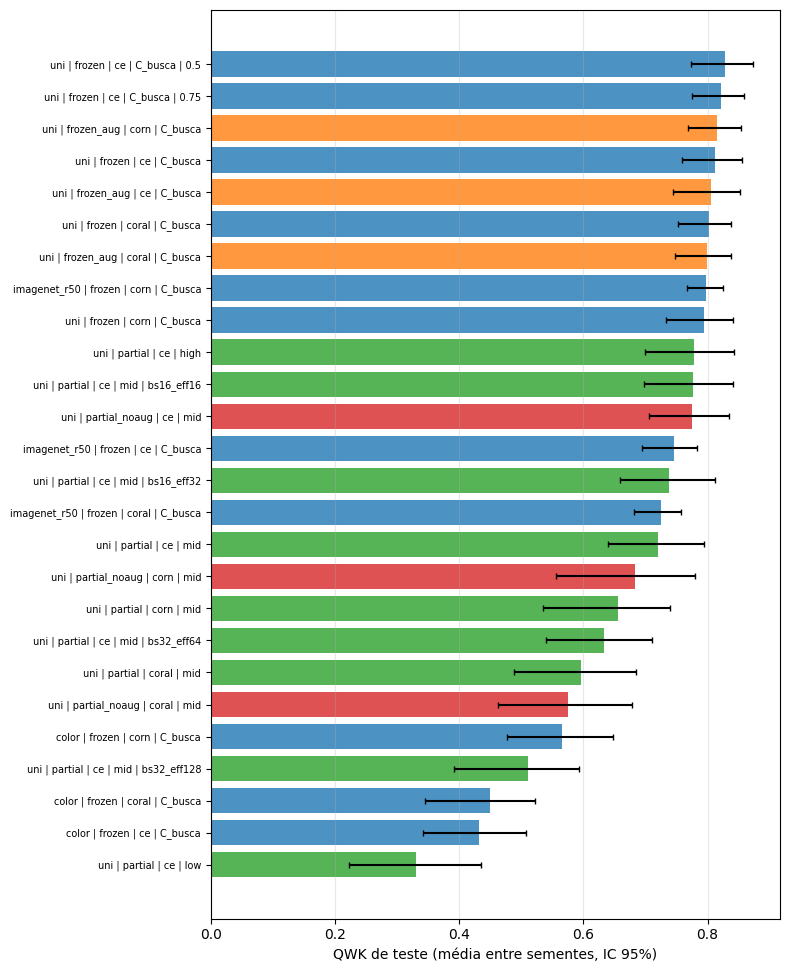

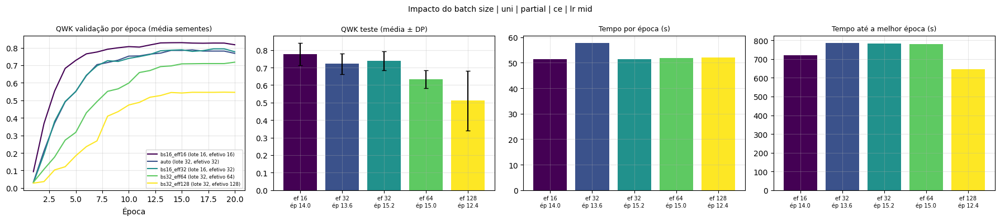


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_uni
[fase 6_batch_size] concluída em 3.5 min
[seleção] QWK médio de VALIDAÇÃO por loss (uni, frozen): {'ce': 0.8128, 'corn': 0.8065, 'coral': 0.7958} -> ce

##########################################################################################
# FASE 7_magnificacao | uni | run 'bateria_uni'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"
5,5,311,68.2,75,"[76, 82, 77, 76]",101,22.1,22,"[26, 25, 25, 25]",44,9.6,11,"[12, 7, 12, 13]"
6,6,331,72.6,75,"[82, 89, 83, 77]",78,17.1,22,"[19, 16, 18, 25]",47,10.3,11,"[13, 9, 13, 12]"
7,7,321,70.4,75,"[76, 88, 78, 79]",92,20.2,22,"[29, 18, 22, 23]",43,9.4,11,"[9, 8, 14, 12]"
8,8,316,69.3,75,"[81, 83, 81, 71]",87,19.1,22,"[18, 20, 19, 30]",53,11.6,11,"[15, 11, 14, 13]"
9,9,299,65.6,75,"[76, 74, 79, 70]",101,22.1,22,"[25, 25, 23, 28]",56,12.3,11,"[13, 15, 12, 16]"


[retomada] 200 execução(ões) já salvas em bateria_uni serão puladas
[plano] 3 cenário(s), 30 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
20,uni,frozen,ce,C_busca,1.00,auto,0,extracao_embeddings,64.0,NaN,...,11.0768,NaN,NaN,0.7710,0.5919,0.6205,0.6200,0.8266,0.4600,0.8772
21,uni,frozen,ce,C_busca,1.00,auto,1,extracao_embeddings,64.0,NaN,...,3.8298,NaN,NaN,0.7355,0.7386,0.7382,0.7115,0.9121,0.3654,0.8058
22,uni,frozen,ce,C_busca,1.00,auto,2,extracao_embeddings,64.0,NaN,...,7.0336,NaN,NaN,0.8734,0.7725,0.7778,0.7561,0.8819,0.2683,0.7792
23,uni,frozen,ce,C_busca,1.00,auto,3,extracao_embeddings,64.0,NaN,...,1.9840,NaN,NaN,0.7946,0.7195,0.7235,0.7209,0.8236,0.3488,0.8273
24,uni,frozen,ce,C_busca,1.00,auto,4,extracao_embeddings,64.0,NaN,...,3.7011,NaN,NaN,0.8424,0.7052,0.7049,0.6739,0.8277,0.3261,0.8939
25,uni,frozen,ce,C_busca,1.00,auto,5,extracao_embeddings,64.0,NaN,...,2.1631,NaN,NaN,0.8369,0.6439,0.6564,0.7045,0.9195,0.3409,0.8034
26,uni,frozen,ce,C_busca,1.00,auto,6,extracao_embeddings,64.0,NaN,...,9.8268,NaN,NaN,0.9414,0.9073,0.9028,0.9149,0.9822,0.1064,0.8713
27,uni,frozen,ce,C_busca,1.00,auto,7,extracao_embeddings,64.0,NaN,...,6.5829,NaN,NaN,0.8788,0.7387,0.7366,0.7209,0.8921,0.2791,0.8218
28,uni,frozen,ce,C_busca,1.00,auto,8,extracao_embeddings,64.0,NaN,...,2.5322,NaN,NaN,0.8261,0.5674,0.5859,0.6226,0.8375,0.3962,0.6764
29,uni,frozen,ce,C_busca,1.00,auto,9,extracao_embeddings,64.0,NaN,...,2.6608,NaN,NaN,0.6132,0.5613,0.5896,0.5714,0.8602,0.5714,0.7720



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.027,NaN,0.066,0.8016 ± 0.0524,0.6238 ± 0.0703,0.6234 ± 0.0631,0.6096 ± 0.0669,0.8474 ± 0.0445,0.4107 ± 0.0763,0.7958 ± 0.0485
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,...,3.724,NaN,0.055,0.7941 ± 0.0707,0.6876 ± 0.0613,0.6908 ± 0.0586,0.6860 ± 0.0727,0.8798 ± 0.0437,0.3643 ± 0.0863,0.8065 ± 0.0693
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,...,5.139,NaN,0.001,0.8113 ± 0.0907,0.6946 ± 0.1070,0.7036 ± 0.0965,0.7017 ± 0.0942,0.8763 ± 0.0517,0.3463 ± 0.1225,0.8128 ± 0.0632
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.588,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,...,13.527,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,...,10.309,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.630,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.737,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,...,0.598,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,...,22.724,NaN,0.002,0.7995 ± 0.0633,0.6323 ± 0.0807,0.6328 ± 0.0824,0.6214 ± 0.0845,0.8462 ± 0.0447,0.4033 ± 0.0949,0.8045 ± 0.0573



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_uni/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,uni,frozen,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8016 [0.7525, 0.8371]","0.6238 [0.5699, 0.6668]","0.6234 [0.5816, 0.6779]","0.6096 [0.5621, 0.6630]","0.8474 [0.8207, 0.8782]","0.4107 [0.3500, 0.4671]"
1,uni,frozen,corn,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7941 [0.7335, 0.8402]","0.6876 [0.6366, 0.7353]","0.6908 [0.6509, 0.7435]","0.6860 [0.6358, 0.7405]","0.8798 [0.8526, 0.9135]","0.3643 [0.2956, 0.4275]"
2,uni,frozen,ce,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.8113 [0.7592, 0.8550]","0.6946 [0.6471, 0.7425]","0.7036 [0.6670, 0.7539]","0.7017 [0.6563, 0.7529]","0.8763 [0.8479, 0.9131]","0.3463 [0.2851, 0.4044]"
3,imagenet_r50,frozen,coral,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.00,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.00,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,uni,frozen_aug,coral,C_busca,1.00,auto,10,64.0,NaN,NaN,"0.7995 [0.7476, 0.8381]","0.6323 [0.5714, 0.6762]","0.6328 [0.5861, 0.6856]","0.6214 [0.5693, 0.6763]","0.8462 [0.8184, 0.8764]","0.4033 [0.3364, 0.4615]"


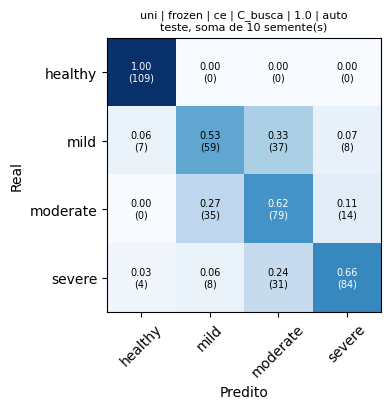

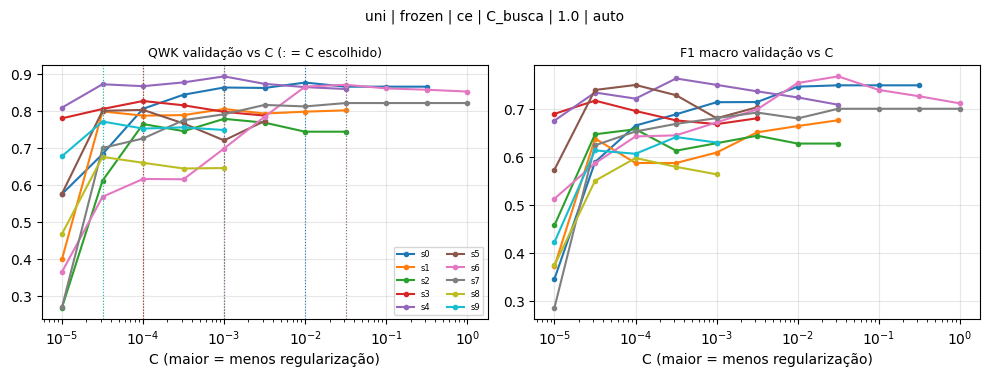

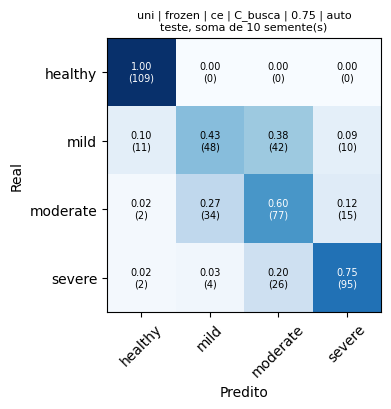

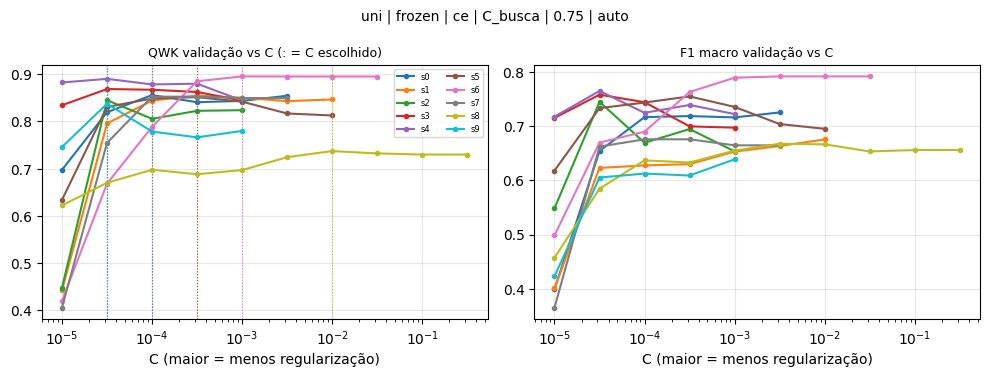

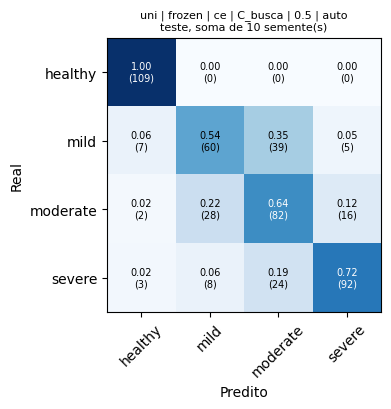

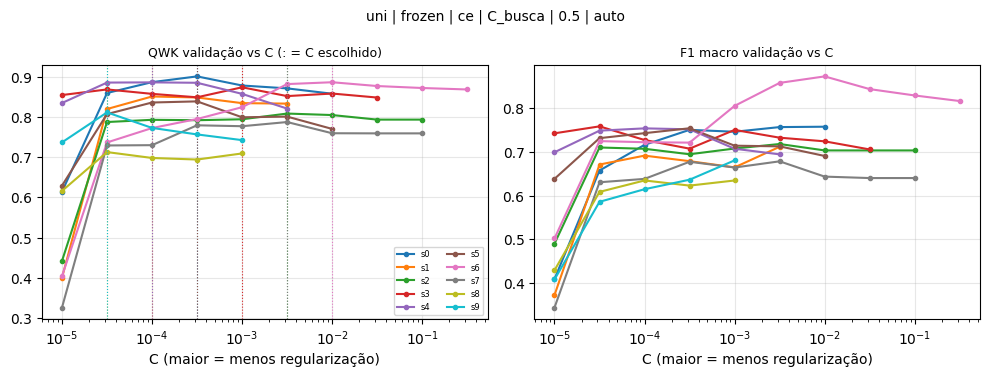

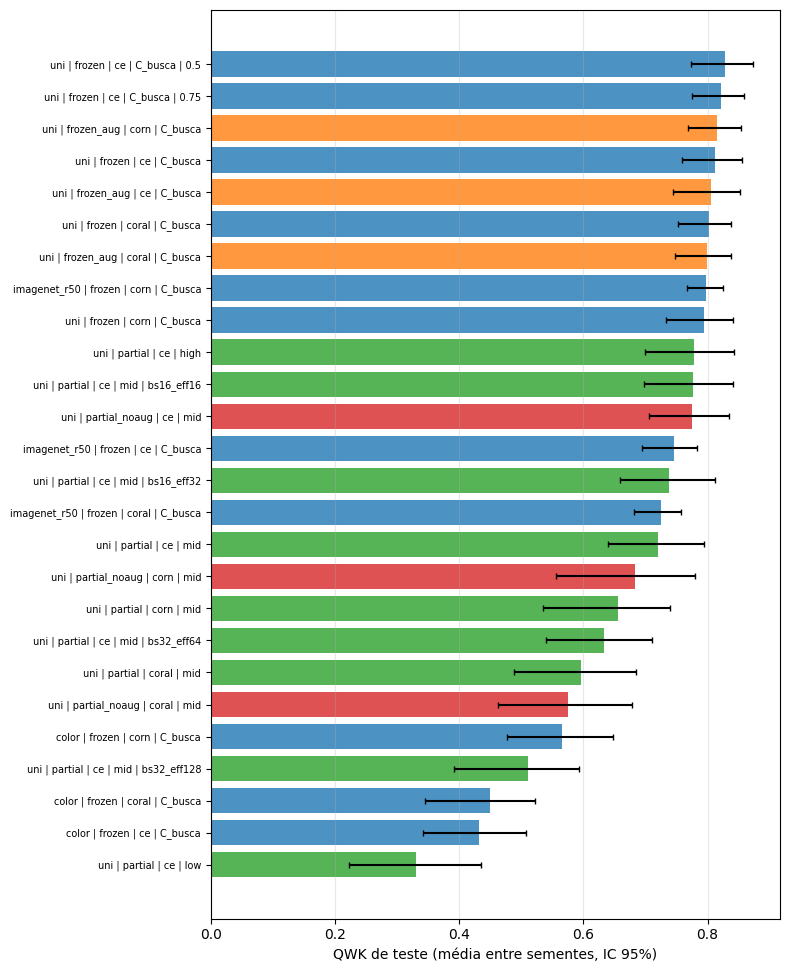

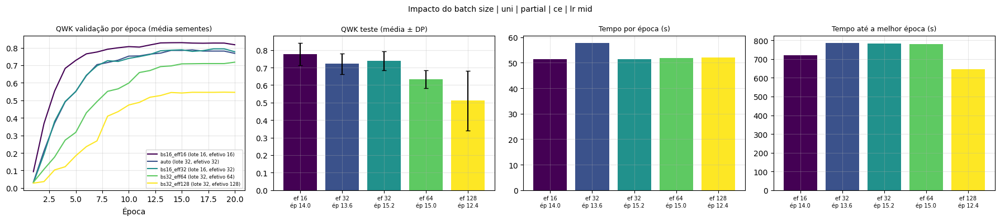


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_uni
[fase 7_magnificacao] concluída em 3.6 min

  INICIANDO BATERIA: CONCH

##########################################################################################
# FASE 0_smoke | conch | run 'smoke_conch'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] SUBCONJUNTO de teste: 8 imagens/classe
[dataset] 133 ROIs de 32 imagens de origem | por classe: {'healthy': 26, 'mild': 44, 'moderate': 33, 'severe': 30} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/smoke_conch_20261010_211321/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,89,66.9,21,"[17, 30, 25, 17]",25,18.8,7,"[5, 10, 3, 7]",19,14.3,4,"[4, 4, 5, 6]"


[plano] 12 cenário(s), 12 execução(ões), 12 pendente(s)

===== conch: 9 execução(ões) pendente(s) =====


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


meta.yaml:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  802MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[conch] janela=448px | Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
[magnificação] conch scale=1: ROI 450x250 -> fator 1.792, 2 janela(s) de 448px | informe Config.native_mpp para comparar com o pré-treino
[embeddings] cache reutilizado: conch_1fc75f7df518b3dc.npz (133, 512) (lote=32)
[embeddings] cache reutilizado: conch_c314b83628357aa8.npz (133, 512) (lote=32)
  >> conch | frozen | coral | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.3607 F1=0.1917 AUROC=0.5702 | val QWK=0.7937 | 1s | 1/12 | ETA ~0 min
  >> conch | frozen | corn | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.2549 F1=0.1548 AUROC=0.5109 | val QWK=0.6858 | 1s | 2/12 | ETA ~0 min
  >> conch | frozen | ce | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.3559 F1=0.2167 AUROC=0.4863 | val QWK=0.5440 | 1s | 3/12 | ETA ~0 min
  >> conch | frozen_aug | coral | C_busca | 1.0 | auto | semente 0
     teste: QWK=0.1802 F1=0.1972 AUROC=0.5677 | val QWK=0.8216 | 1s |

,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
0,conch,frozen,coral,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,0.5497,NaN,NaN,0.3607,0.1917,0.1750,0.1579,0.5702,1.0000,0.7937
1,conch,frozen,corn,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,0.5260,NaN,NaN,0.2549,0.1548,0.2250,0.2105,0.5109,0.9474,0.6858
2,conch,frozen,ce,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,1.0120,NaN,NaN,0.3559,0.2167,0.1875,0.1579,0.4863,1.0526,0.5440
3,conch,frozen_aug,coral,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,0.9507,NaN,NaN,0.1802,0.1972,0.1750,0.1579,0.5677,1.1579,0.8216
4,conch,frozen_aug,corn,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,0.6506,NaN,NaN,0.1111,0.0714,0.1000,0.1053,0.4815,1.1579,0.7210
5,conch,frozen_aug,ce,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,0.9950,NaN,NaN,0.3492,0.2000,0.1667,0.1579,0.4325,1.1053,0.6960
6,conch,partial,coral,mid,1.0,auto,0,treino,8.0,4.0,...,47.6780,5.7862,0.0,0.0000,0.1200,0.2500,0.3158,0.5774,1.3158,0.0000
7,conch,partial,corn,mid,1.0,auto,0,treino,8.0,4.0,...,49.9323,5.7862,0.0,0.0000,0.0870,0.2500,0.2105,0.7703,1.1053,0.0000
8,conch,partial,ce,mid,1.0,auto,0,treino,8.0,4.0,...,49.7684,5.7862,0.0,-0.1021,0.1048,0.1667,0.1579,0.2362,1.6316,0.3637
9,color,frozen,coral,C_busca,1.0,auto,0,extracao_embeddings,NaN,NaN,...,0.0657,NaN,NaN,0.3688,0.3000,0.4500,0.4211,0.8250,0.7368,0.3012



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/smoke_conch_20261010_211321/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,conch,frozen,coral,C_busca,1.0,auto,1,32.0,NaN,NaN,...,0.550,NaN,0.01,0.3607 ± n/a,0.1917 ± n/a,0.1750 ± n/a,0.1579 ± n/a,0.5702 ± n/a,1.0000 ± n/a,0.7937 ± n/a
1,conch,frozen,corn,C_busca,1.0,auto,1,32.0,NaN,NaN,...,0.526,NaN,0.01,0.2549 ± n/a,0.1548 ± n/a,0.2250 ± n/a,0.2105 ± n/a,0.5109 ± n/a,0.9474 ± n/a,0.6858 ± n/a
2,conch,frozen,ce,C_busca,1.0,auto,1,32.0,NaN,NaN,...,1.012,NaN,0.10,0.3559 ± n/a,0.2167 ± n/a,0.1875 ± n/a,0.1579 ± n/a,0.4863 ± n/a,1.0526 ± n/a,0.5440 ± n/a
3,conch,frozen_aug,coral,C_busca,1.0,auto,1,32.0,NaN,NaN,...,0.951,NaN,0.01,0.1802 ± n/a,0.1972 ± n/a,0.1750 ± n/a,0.1579 ± n/a,0.5677 ± n/a,1.1579 ± n/a,0.8216 ± n/a
4,conch,frozen_aug,corn,C_busca,1.0,auto,1,32.0,NaN,NaN,...,0.651,NaN,0.01,0.1111 ± n/a,0.0714 ± n/a,0.1000 ± n/a,0.1053 ± n/a,0.4815 ± n/a,1.1579 ± n/a,0.7210 ± n/a
5,conch,frozen_aug,ce,C_busca,1.0,auto,1,32.0,NaN,NaN,...,0.995,NaN,0.10,0.3492 ± n/a,0.2000 ± n/a,0.1667 ± n/a,0.1579 ± n/a,0.4325 ± n/a,1.1053 ± n/a,0.6960 ± n/a
6,conch,partial,coral,mid,1.0,auto,1,8.0,4.0,32.0,...,47.678,5.786,NaN,0.0000 ± n/a,0.1200 ± n/a,0.2500 ± n/a,0.3158 ± n/a,0.5774 ± n/a,1.3158 ± n/a,0.0000 ± n/a
7,conch,partial,corn,mid,1.0,auto,1,8.0,4.0,32.0,...,49.932,5.786,NaN,0.0000 ± n/a,0.0870 ± n/a,0.2500 ± n/a,0.2105 ± n/a,0.7703 ± n/a,1.1053 ± n/a,0.0000 ± n/a
8,conch,partial,ce,mid,1.0,auto,1,8.0,4.0,32.0,...,49.768,5.786,NaN,-0.1021 ± n/a,0.1048 ± n/a,0.1667 ± n/a,0.1579 ± n/a,0.2362 ± n/a,1.6316 ± n/a,0.3637 ± n/a
9,color,frozen,coral,C_busca,1.0,auto,1,NaN,NaN,NaN,...,0.066,NaN,0.01,0.3688 ± n/a,0.3000 ± n/a,0.4500 ± n/a,0.4211 ± n/a,0.8250 ± n/a,0.7368 ± n/a,0.3012 ± n/a



===== Teste: média entre sementes + IC 95% (bootstrap de 50 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/smoke_conch_20261010_211321/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,conch,frozen,coral,C_busca,1.0,auto,1,32.0,NaN,NaN,"0.3607 [0.3607, 0.3607]","0.1917 [0.1917, 0.1917]","0.1750 [0.1750, 0.1750]","0.1579 [0.1579, 0.1579]","0.5702 [0.5702, 0.5702]","1.0000 [1.0000, 1.0000]"
1,conch,frozen,corn,C_busca,1.0,auto,1,32.0,NaN,NaN,"0.2549 [0.2549, 0.2549]","0.1548 [0.1548, 0.1548]","0.2250 [0.2250, 0.2250]","0.2105 [0.2105, 0.2105]","0.5109 [0.5109, 0.5109]","0.9474 [0.9474, 0.9474]"
2,conch,frozen,ce,C_busca,1.0,auto,1,32.0,NaN,NaN,"0.3559 [0.3559, 0.3559]","0.2167 [0.2167, 0.2167]","0.1875 [0.1875, 0.1875]","0.1579 [0.1579, 0.1579]","0.4863 [0.4863, 0.4863]","1.0526 [1.0526, 1.0526]"
3,conch,frozen_aug,coral,C_busca,1.0,auto,1,32.0,NaN,NaN,"0.1802 [0.1802, 0.1802]","0.1972 [0.1972, 0.1972]","0.1750 [0.1750, 0.1750]","0.1579 [0.1579, 0.1579]","0.5677 [0.5677, 0.5677]","1.1579 [1.1579, 1.1579]"
4,conch,frozen_aug,corn,C_busca,1.0,auto,1,32.0,NaN,NaN,"0.1111 [0.1111, 0.1111]","0.0714 [0.0714, 0.0714]","0.1000 [0.1000, 0.1000]","0.1053 [0.1053, 0.1053]","0.4815 [0.4815, 0.4815]","1.1579 [1.1579, 1.1579]"
5,conch,frozen_aug,ce,C_busca,1.0,auto,1,32.0,NaN,NaN,"0.3492 [0.3492, 0.3492]","0.2000 [0.2000, 0.2000]","0.1667 [0.1667, 0.1667]","0.1579 [0.1579, 0.1579]","0.4325 [0.4325, 0.4325]","1.1053 [1.1053, 1.1053]"
6,conch,partial,coral,mid,1.0,auto,1,8.0,32.0,1.0,"0.0000 [0.0000, 0.0000]","0.1200 [0.1200, 0.1200]","0.2500 [0.2500, 0.2500]","0.3158 [0.3158, 0.3158]","0.5774 [0.5774, 0.5774]","1.3158 [1.3158, 1.3158]"
7,conch,partial,corn,mid,1.0,auto,1,8.0,32.0,1.0,"0.0000 [0.0000, 0.0000]","0.0870 [0.0870, 0.0870]","0.2500 [0.2500, 0.2500]","0.2105 [0.2105, 0.2105]","0.7724 [0.7724, 0.7724]","1.1053 [1.1053, 1.1053]"
8,conch,partial,ce,mid,1.0,auto,1,8.0,32.0,1.0,"-0.1021 [-0.1021, -0.1021]","0.1048 [0.1048, 0.1048]","0.1667 [0.1667, 0.1667]","0.1579 [0.1579, 0.1579]","0.2362 [0.2362, 0.2362]","1.6316 [1.6316, 1.6316]"
9,color,frozen,coral,C_busca,1.0,auto,1,NaN,NaN,NaN,"0.3688 [0.3688, 0.3688]","0.3000 [0.3000, 0.3000]","0.4500 [0.4500, 0.4500]","0.4211 [0.4211, 0.4211]","0.8250 [0.8250, 0.8250]","0.7368 [0.7368, 0.7368]"


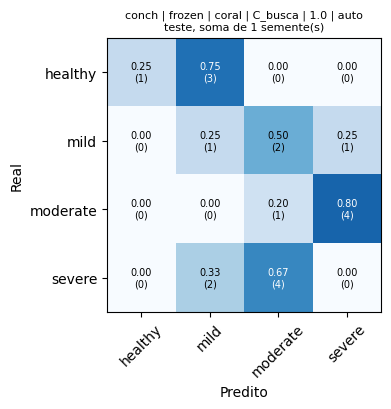

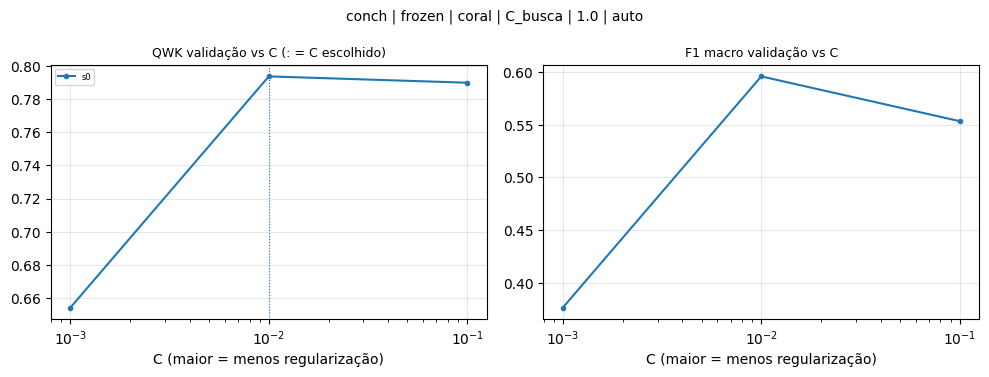

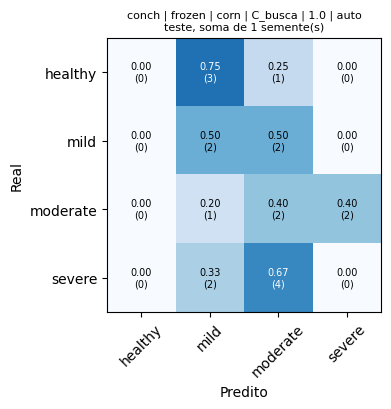

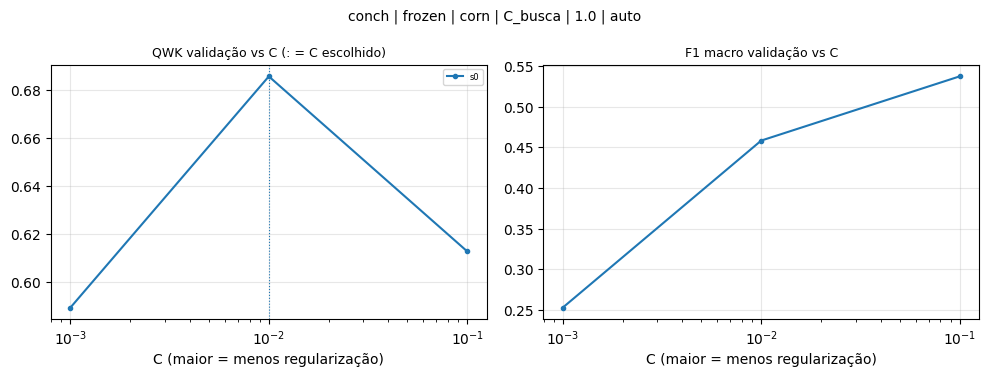

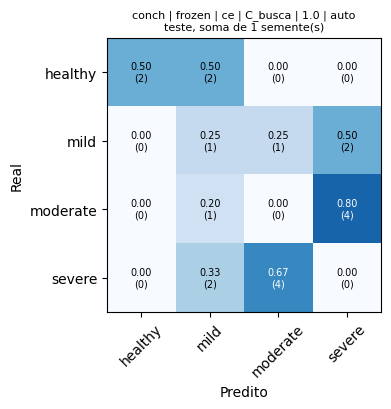

...

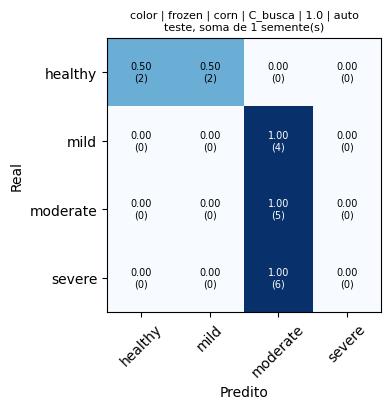

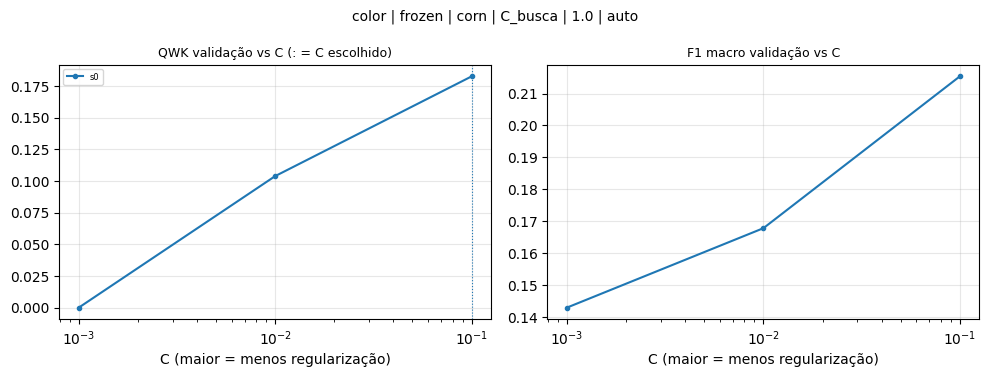

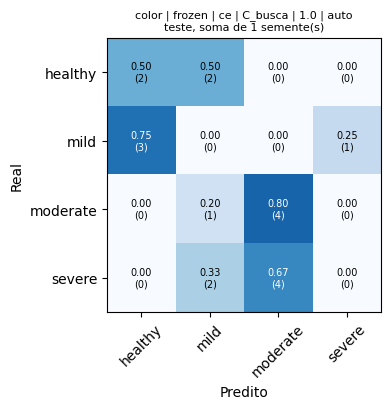

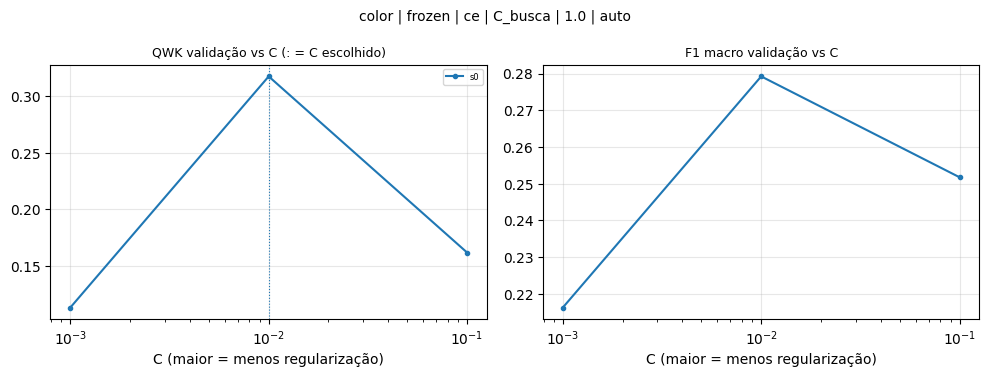

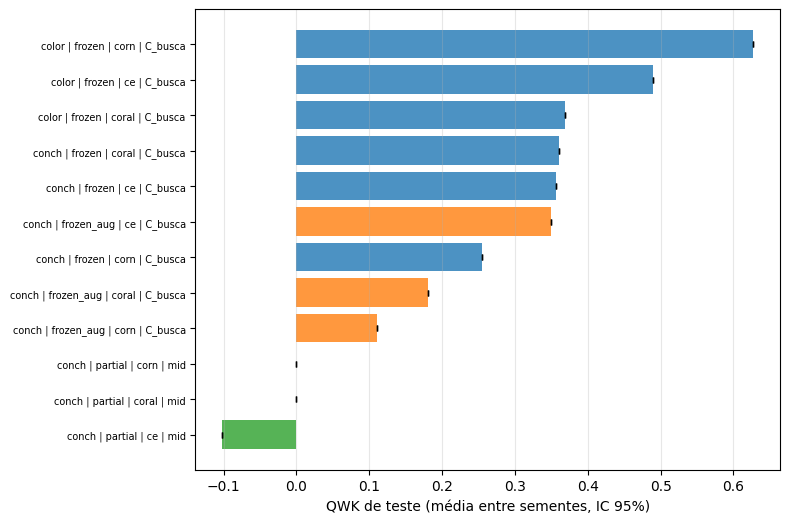


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/smoke_conch_20261010_211321
[fase 0_smoke] concluída em 3.7 min

##########################################################################################
# FASE 1_frozen_baselines | conch | run 'bateria_conch'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"
5,5,311,68.2,75,"[76, 82, 77, 76]",101,22.1,22,"[26, 25, 25, 25]",44,9.6,11,"[12, 7, 12, 13]"
6,6,331,72.6,75,"[82, 89, 83, 77]",78,17.1,22,"[19, 16, 18, 25]",47,10.3,11,"[13, 9, 13, 12]"
7,7,321,70.4,75,"[76, 88, 78, 79]",92,20.2,22,"[29, 18, 22, 23]",43,9.4,11,"[9, 8, 14, 12]"
8,8,316,69.3,75,"[81, 83, 81, 71]",87,19.1,22,"[18, 20, 19, 30]",53,11.6,11,"[15, 11, 14, 13]"
9,9,299,65.6,75,"[76, 74, 79, 70]",101,22.1,22,"[25, 25, 23, 28]",56,12.3,11,"[13, 15, 12, 16]"


[retomada] 125 execução(ões) já salvas em bateria_conch serão puladas
[plano] 9 cenário(s), 90 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
0,conch,frozen,coral,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,1.8325,NaN,NaN,0.7432,0.5546,0.5409,0.5400,0.7865,0.5000,0.8228
1,conch,frozen,coral,C_busca,1.0,auto,1,extracao_embeddings,32.0,NaN,...,0.6170,NaN,NaN,0.8116,0.6914,0.6827,0.6346,0.8444,0.3654,0.7939
2,conch,frozen,coral,C_busca,1.0,auto,2,extracao_embeddings,32.0,NaN,...,2.7561,NaN,NaN,0.7566,0.5333,0.5486,0.5122,0.7198,0.5366,0.7293
3,conch,frozen,coral,C_busca,1.0,auto,3,extracao_embeddings,32.0,NaN,...,2.4764,NaN,NaN,0.6569,0.5420,0.5284,0.5349,0.7822,0.5814,0.8194
4,conch,frozen,coral,C_busca,1.0,auto,4,extracao_embeddings,32.0,NaN,...,1.3951,NaN,NaN,0.6444,0.4882,0.4742,0.4565,0.7730,0.5870,0.8681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,color,frozen,ce,C_busca,1.0,auto,5,extracao_embeddings,NaN,NaN,...,0.4648,NaN,NaN,0.3400,0.5287,0.5877,0.5455,0.8059,0.7955,0.3944
86,color,frozen,ce,C_busca,1.0,auto,6,extracao_embeddings,NaN,NaN,...,1.0060,NaN,NaN,0.6943,0.6042,0.6651,0.6383,0.8736,0.4894,0.5735
87,color,frozen,ce,C_busca,1.0,auto,7,extracao_embeddings,NaN,NaN,...,0.5423,NaN,NaN,0.3638,0.5526,0.6002,0.5581,0.8178,0.7674,0.5756
88,color,frozen,ce,C_busca,1.0,auto,8,extracao_embeddings,NaN,NaN,...,0.4821,NaN,NaN,0.5613,0.5487,0.5457,0.5660,0.7493,0.6226,0.4394



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.522,NaN,0.032,0.7711 ± 0.0804,0.5927 ± 0.0941,0.5894 ± 0.0998,0.5791 ± 0.0961,0.8145 ± 0.0637,0.4555 ± 0.1179,0.7773 ± 0.0598
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.542,NaN,0.066,0.7490 ± 0.0866,0.6423 ± 0.1012,0.6439 ± 0.0974,0.6350 ± 0.1084,0.8704 ± 0.0465,0.4253 ± 0.1217,0.7760 ± 0.0450
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.422,NaN,0.007,0.7307 ± 0.1013,0.6553 ± 0.1154,0.6718 ± 0.1028,0.6618 ± 0.1020,0.8696 ± 0.0616,0.4296 ± 0.1061,0.7696 ± 0.0849
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.990,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,...,11.454,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.847,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.494,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.827,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.617,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,14.389,NaN,0.003,0.7708 ± 0.0788,0.5902 ± 0.0919,0.5869 ± 0.0937,0.5800 ± 0.0894,0.8250 ± 0.0642,0.4545 ± 0.1121,0.7811 ± 0.0601



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7711 [0.7241, 0.8088]","0.5927 [0.5497, 0.6273]","0.5894 [0.5532, 0.6335]","0.5791 [0.5375, 0.6202]","0.8145 [0.7898, 0.8436]","0.4555 [0.4027, 0.5082]"
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7490 [0.6979, 0.7921]","0.6423 [0.5952, 0.6874]","0.6439 [0.6058, 0.6938]","0.6350 [0.5908, 0.6825]","0.8704 [0.8448, 0.9004]","0.4253 [0.3664, 0.4803]"
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7307 [0.6625, 0.7847]","0.6553 [0.6043, 0.6951]","0.6718 [0.6317, 0.7147]","0.6618 [0.6175, 0.7084]","0.8696 [0.8445, 0.8987]","0.4296 [0.3679, 0.4963]"
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7708 [0.7195, 0.8111]","0.5902 [0.5420, 0.6294]","0.5869 [0.5471, 0.6412]","0.5800 [0.5377, 0.6262]","0.8250 [0.7984, 0.8579]","0.4545 [0.3950, 0.5089]"


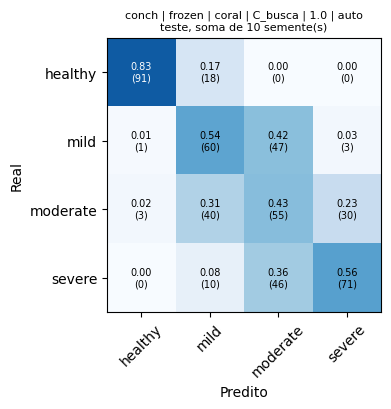

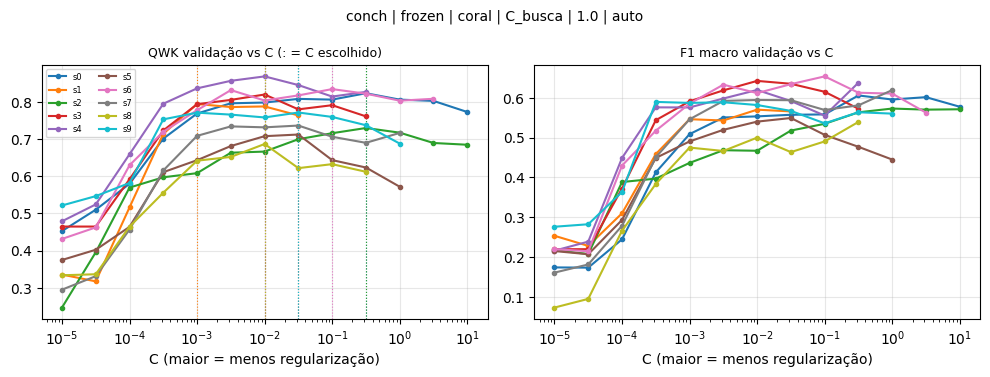

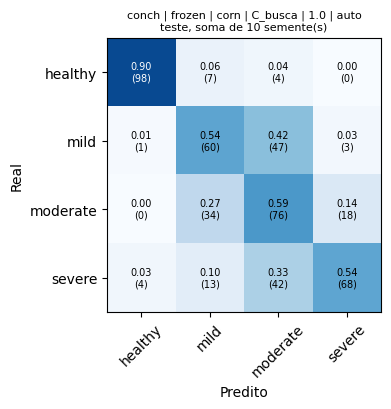

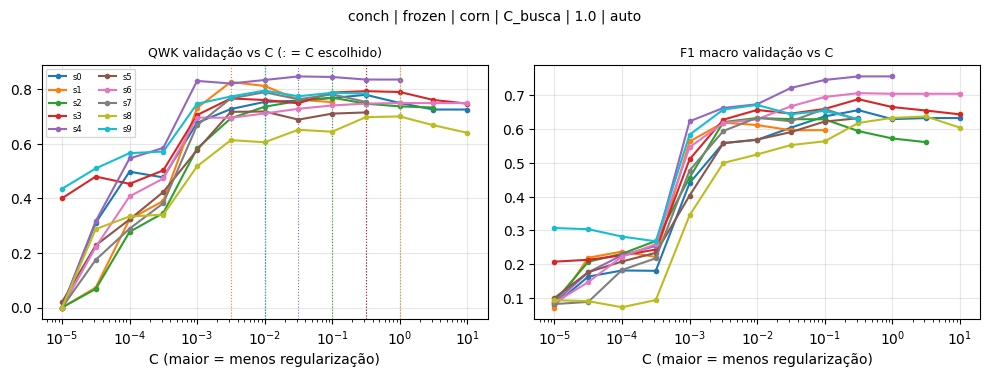

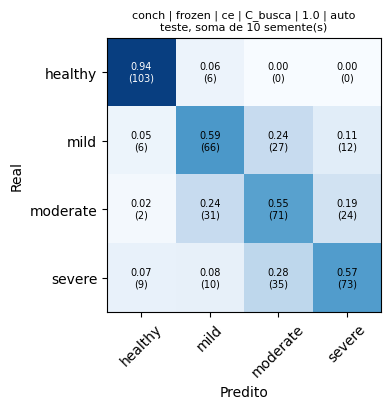

...

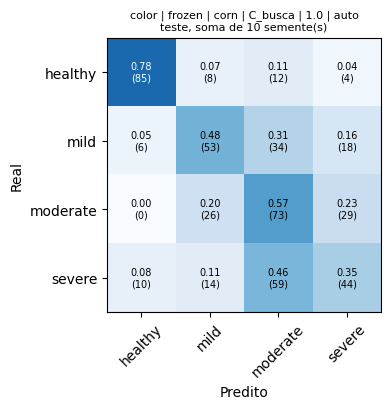

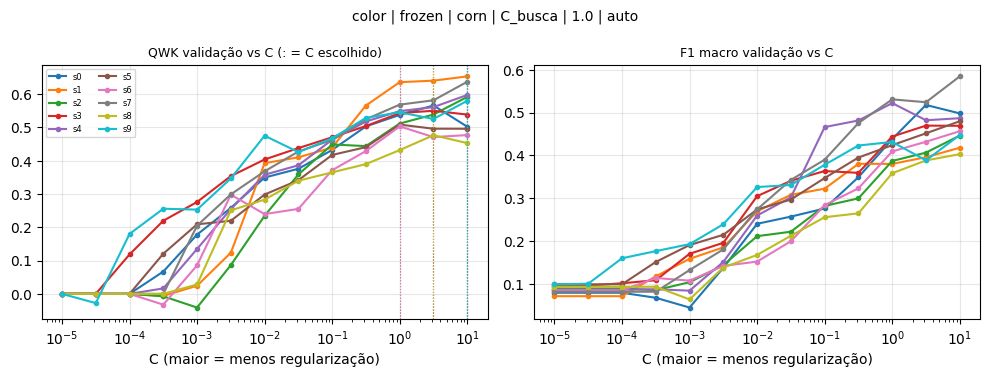

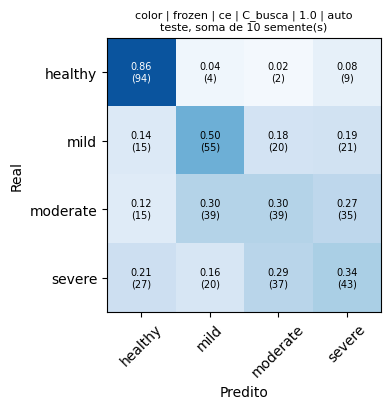

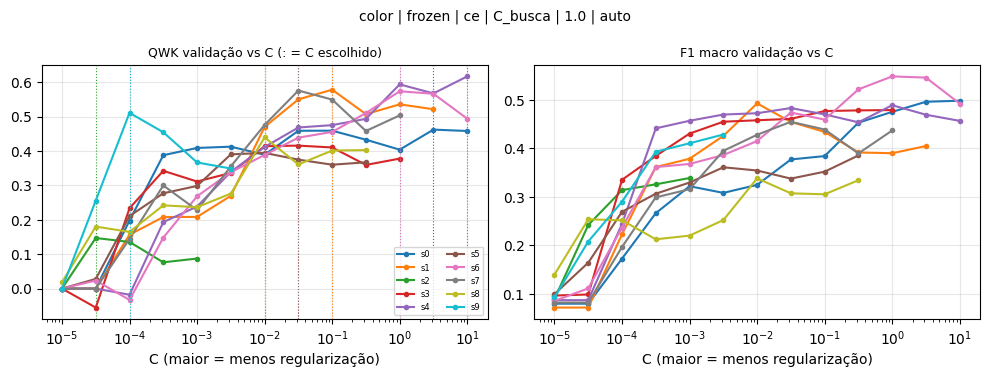

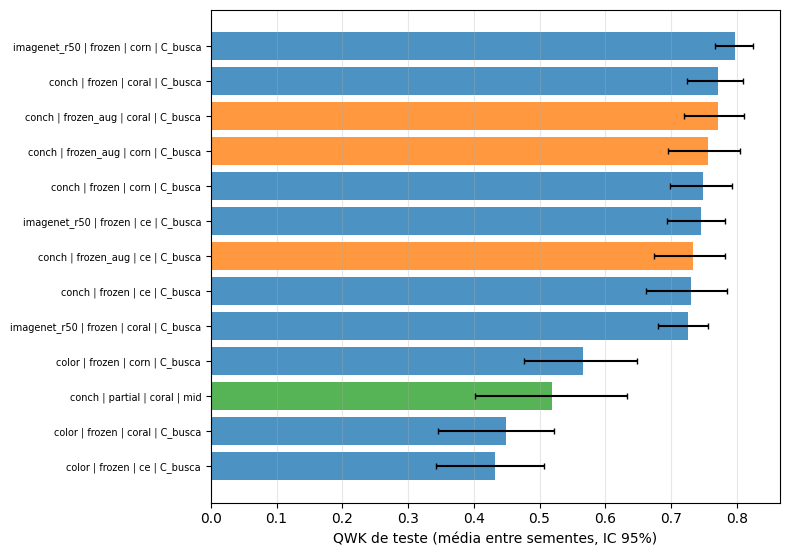


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_conch
[fase 1_frozen_baselines] concluída em 4.8 min

##########################################################################################
# FASE 2_frozen_aug | conch | run 'bateria_conch'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"
5,5,311,68.2,75,"[76, 82, 77, 76]",101,22.1,22,"[26, 25, 25, 25]",44,9.6,11,"[12, 7, 12, 13]"
6,6,331,72.6,75,"[82, 89, 83, 77]",78,17.1,22,"[19, 16, 18, 25]",47,10.3,11,"[13, 9, 13, 12]"
7,7,321,70.4,75,"[76, 88, 78, 79]",92,20.2,22,"[29, 18, 22, 23]",43,9.4,11,"[9, 8, 14, 12]"
8,8,316,69.3,75,"[81, 83, 81, 71]",87,19.1,22,"[18, 20, 19, 30]",53,11.6,11,"[15, 11, 14, 13]"
9,9,299,65.6,75,"[76, 74, 79, 70]",101,22.1,22,"[25, 25, 23, 28]",56,12.3,11,"[13, 15, 12, 16]"


[retomada] 125 execução(ões) já salvas em bateria_conch serão puladas
[plano] 3 cenário(s), 30 execução(ões), 0 pendente(s)

===== Execuções (cenários desta chamada) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/execucoes_desta_chamada.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
90,conch,frozen_aug,coral,C_busca,1.0,auto,0,extracao_embeddings,32.0,NaN,...,11.1360,NaN,NaN,0.7749,0.5230,0.4973,0.5000,0.7841,0.5000,0.8058
91,conch,frozen_aug,coral,C_busca,1.0,auto,1,extracao_embeddings,32.0,NaN,...,6.0580,NaN,NaN,0.7976,0.6952,0.6912,0.6538,0.8445,0.3654,0.7852
92,conch,frozen_aug,coral,C_busca,1.0,auto,2,extracao_embeddings,32.0,NaN,...,39.2191,NaN,NaN,0.7189,0.5359,0.5521,0.5366,0.7514,0.5610,0.7440
93,conch,frozen_aug,coral,C_busca,1.0,auto,3,extracao_embeddings,32.0,NaN,...,8.0792,NaN,NaN,0.6828,0.5779,0.5669,0.5814,0.7823,0.5349,0.8340
94,conch,frozen_aug,coral,C_busca,1.0,auto,4,extracao_embeddings,32.0,NaN,...,10.9213,NaN,NaN,0.6394,0.5017,0.4951,0.4783,0.7965,0.5870,0.8621
95,conch,frozen_aug,coral,C_busca,1.0,auto,5,extracao_embeddings,32.0,NaN,...,8.7157,NaN,NaN,0.7395,0.4503,0.4485,0.4545,0.7446,0.5682,0.7456
96,conch,frozen_aug,coral,C_busca,1.0,auto,6,extracao_embeddings,32.0,NaN,...,28.1731,NaN,NaN,0.8387,0.6202,0.6357,0.6170,0.8555,0.3830,0.8515
97,conch,frozen_aug,coral,C_busca,1.0,auto,7,extracao_embeddings,32.0,NaN,...,7.0789,NaN,NaN,0.7683,0.5843,0.5809,0.5814,0.8668,0.4419,0.7462
98,conch,frozen_aug,coral,C_busca,1.0,auto,8,extracao_embeddings,32.0,NaN,...,17.7741,NaN,NaN,0.8912,0.7382,0.7360,0.7358,0.9488,0.2642,0.6643
99,conch,frozen_aug,coral,C_busca,1.0,auto,9,extracao_embeddings,32.0,NaN,...,6.7344,NaN,NaN,0.8563,0.6750,0.6656,0.6607,0.8755,0.3393,0.7726



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.522,NaN,0.032,0.7711 ± 0.0804,0.5927 ± 0.0941,0.5894 ± 0.0998,0.5791 ± 0.0961,0.8145 ± 0.0637,0.4555 ± 0.1179,0.7773 ± 0.0598
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.542,NaN,0.066,0.7490 ± 0.0866,0.6423 ± 0.1012,0.6439 ± 0.0974,0.6350 ± 0.1084,0.8704 ± 0.0465,0.4253 ± 0.1217,0.7760 ± 0.0450
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.422,NaN,0.007,0.7307 ± 0.1013,0.6553 ± 0.1154,0.6718 ± 0.1028,0.6618 ± 0.1020,0.8696 ± 0.0616,0.4296 ± 0.1061,0.7696 ± 0.0849
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.990,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,...,11.454,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.847,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.494,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.827,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.617,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,14.389,NaN,0.003,0.7708 ± 0.0788,0.5902 ± 0.0919,0.5869 ± 0.0937,0.5800 ± 0.0894,0.8250 ± 0.0642,0.4545 ± 0.1121,0.7811 ± 0.0601



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7711 [0.7241, 0.8088]","0.5927 [0.5497, 0.6273]","0.5894 [0.5532, 0.6335]","0.5791 [0.5375, 0.6202]","0.8145 [0.7898, 0.8436]","0.4555 [0.4027, 0.5082]"
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7490 [0.6979, 0.7921]","0.6423 [0.5952, 0.6874]","0.6439 [0.6058, 0.6938]","0.6350 [0.5908, 0.6825]","0.8704 [0.8448, 0.9004]","0.4253 [0.3664, 0.4803]"
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7307 [0.6625, 0.7847]","0.6553 [0.6043, 0.6951]","0.6718 [0.6317, 0.7147]","0.6618 [0.6175, 0.7084]","0.8696 [0.8445, 0.8987]","0.4296 [0.3679, 0.4963]"
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7708 [0.7195, 0.8111]","0.5902 [0.5420, 0.6294]","0.5869 [0.5471, 0.6412]","0.5800 [0.5377, 0.6262]","0.8250 [0.7984, 0.8579]","0.4545 [0.3950, 0.5089]"


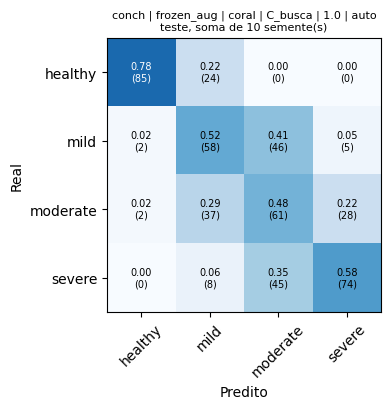

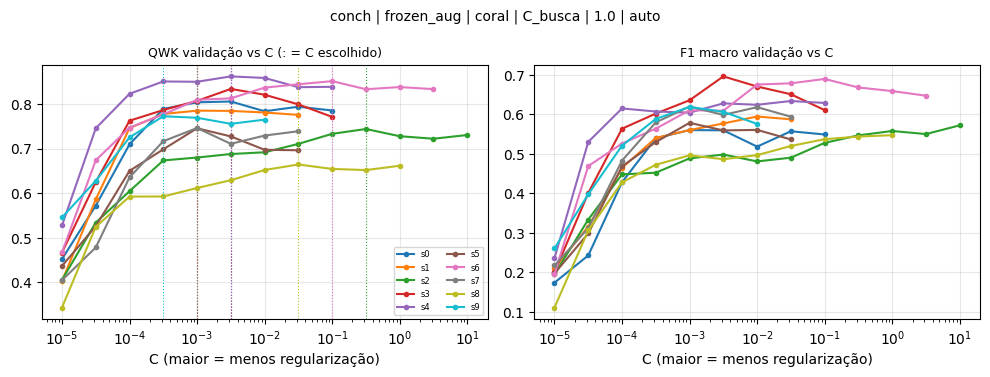

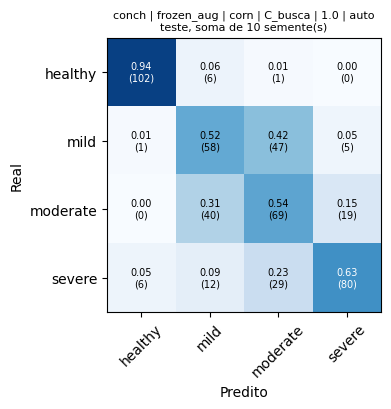

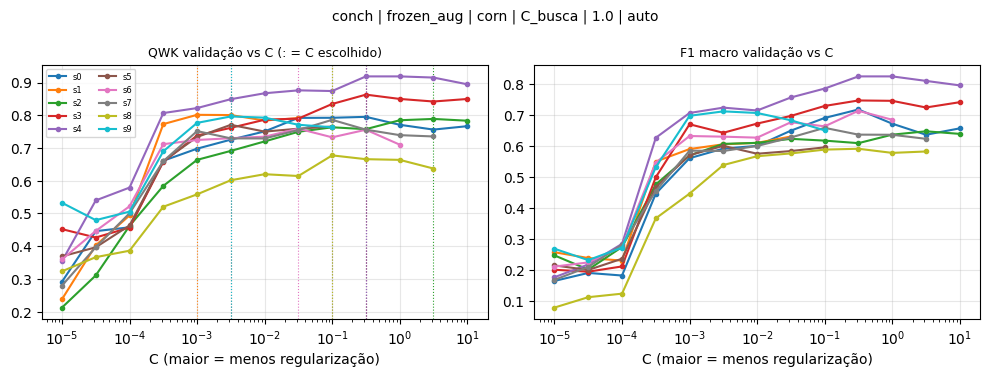

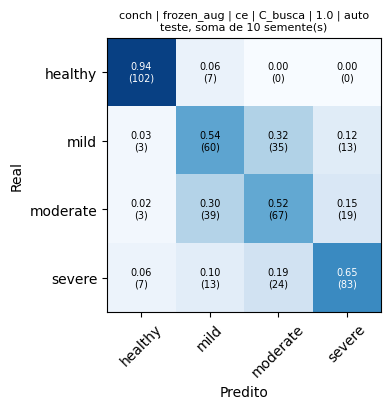

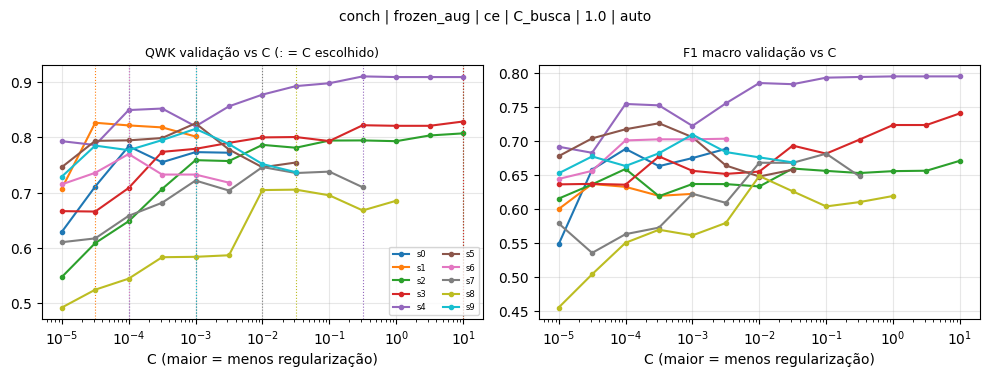

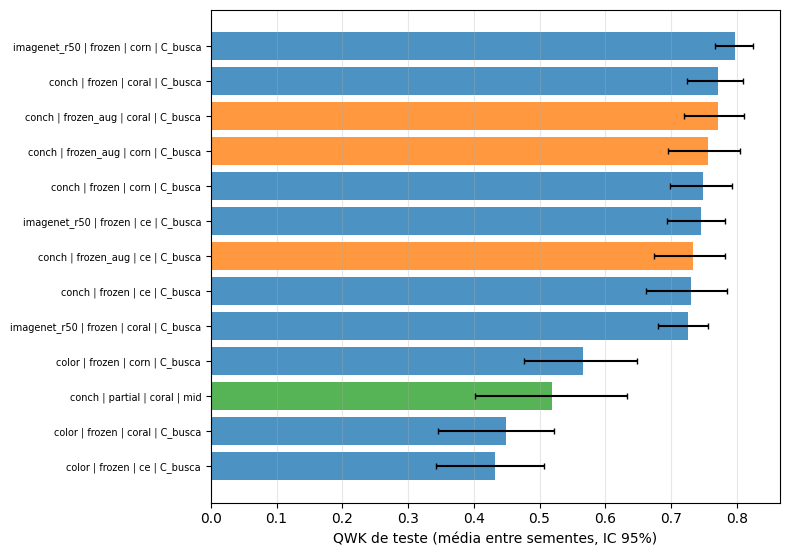


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_conch
[fase 2_frozen_aug] concluída em 2.6 min

##########################################################################################
# FASE 3_partial | conch | run 'bateria_conch'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 125 execução(ões) já salvas em bateria_conch serão puladas
[plano] 3 cenário(s), 15 execução(ões), 10 pendente(s)

===== conch: 10 execução(ões) pendente(s) =====
[conch] janela=448px | Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
[magnificação] conch scale=1: ROI 450x250 -> fator 1.792, 2 janela(s) de 448px | informe Config.native_mpp para comparar com o pré-treino
  >> conch | partial | corn | mid | 1.0 | auto | semente 0
      lote=8 ROIs x accum 4 (efetivo alvo 32)
      ep 01 loss=0.6690 val_loss=0.7677 val_qwk=0.0000 (87.7s)
      ep 02 loss=0.6280 val_loss=0.7523 val_qwk=0.0000 (85.7s)
      ep 03 loss=0.5995 val_loss=0.7351 val_qwk=0.1928 (85.0s)
      ep 04 loss=0.5743 val_loss=0.7118 val_qwk=0.2978 (85.8s)
      ep 05 loss=0.5436 val_loss=0.6973 val_qwk=0.4011 (85.9s)
      ep 06 loss=0.5310 val_loss=0.6768 val_qwk=0.4356 (85.9s)
      ep 07 loss=0.5112 val_loss=0.6558 val_qwk=0.4626 (85.6s)
      ep 08 loss=0.4953 v

,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
120,conch,partial,coral,mid,1.0,auto,0,treino,8.0,4.0,...,1277.1756,6.9681,0.0,0.6091,0.3160,0.4792,0.4600,0.7271,0.8000,0.6530
121,conch,partial,coral,mid,1.0,auto,1,treino,8.0,4.0,...,1582.3247,6.9681,0.0,0.5168,0.2713,0.4808,0.3846,0.8695,0.9231,0.8192
122,conch,partial,coral,mid,1.0,auto,2,treino,8.0,4.0,...,1467.0812,6.9636,0.0,0.6649,0.3405,0.5000,0.4878,0.7225,0.7073,0.6944
123,conch,partial,coral,mid,1.0,auto,3,treino,8.0,4.0,...,1612.3177,6.9681,0.0,0.4274,0.2697,0.3958,0.4186,0.7899,1.0000,0.6264
124,conch,partial,coral,mid,1.0,auto,4,treino,8.0,4.0,...,1135.5937,6.9546,0.0,0.3761,0.2433,0.4167,0.3478,0.7717,1.0870,0.7271
125,conch,partial,corn,mid,1.0,auto,0,treino,8.0,4.0,...,1709.8976,6.9681,0.0,0.6584,0.4935,0.5087,0.5000,0.8287,0.5400,0.5793
126,conch,partial,corn,mid,1.0,auto,1,treino,8.0,4.0,...,1690.2384,6.9681,0.0,0.5972,0.4415,0.4338,0.4231,0.8885,0.5962,0.7409
127,conch,partial,corn,mid,1.0,auto,2,treino,8.0,4.0,...,1744.5492,6.9636,0.0,0.5512,0.3486,0.3333,0.3171,0.7564,0.7317,0.6557
128,conch,partial,corn,mid,1.0,auto,3,treino,8.0,4.0,...,1720.7791,6.9681,0.0,0.5046,0.4144,0.4703,0.4419,0.8764,0.6744,0.5273
129,conch,partial,corn,mid,1.0,auto,4,treino,8.0,4.0,...,1731.1236,6.9547,0.0,0.5969,0.4445,0.4472,0.4130,0.7988,0.6304,0.8034



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.522,NaN,0.032,0.7711 ± 0.0804,0.5927 ± 0.0941,0.5894 ± 0.0998,0.5791 ± 0.0961,0.8145 ± 0.0637,0.4555 ± 0.1179,0.7773 ± 0.0598
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.542,NaN,0.066,0.7490 ± 0.0866,0.6423 ± 0.1012,0.6439 ± 0.0974,0.6350 ± 0.1084,0.8704 ± 0.0465,0.4253 ± 0.1217,0.7760 ± 0.0450
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.422,NaN,0.007,0.7307 ± 0.1013,0.6553 ± 0.1154,0.6718 ± 0.1028,0.6618 ± 0.1020,0.8696 ± 0.0616,0.4296 ± 0.1061,0.7696 ± 0.0849
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.990,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,...,11.454,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.847,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.494,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.827,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.617,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,14.389,NaN,0.003,0.7708 ± 0.0788,0.5902 ± 0.0919,0.5869 ± 0.0937,0.5800 ± 0.0894,0.8250 ± 0.0642,0.4545 ± 0.1121,0.7811 ± 0.0601



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7711 [0.7241, 0.8088]","0.5927 [0.5497, 0.6273]","0.5894 [0.5532, 0.6335]","0.5791 [0.5375, 0.6202]","0.8145 [0.7898, 0.8436]","0.4555 [0.4027, 0.5082]"
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7490 [0.6979, 0.7921]","0.6423 [0.5952, 0.6874]","0.6439 [0.6058, 0.6938]","0.6350 [0.5908, 0.6825]","0.8704 [0.8448, 0.9004]","0.4253 [0.3664, 0.4803]"
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7307 [0.6625, 0.7847]","0.6553 [0.6043, 0.6951]","0.6718 [0.6317, 0.7147]","0.6618 [0.6175, 0.7084]","0.8696 [0.8445, 0.8987]","0.4296 [0.3679, 0.4963]"
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7708 [0.7195, 0.8111]","0.5902 [0.5420, 0.6294]","0.5869 [0.5471, 0.6412]","0.5800 [0.5377, 0.6262]","0.8250 [0.7984, 0.8579]","0.4545 [0.3950, 0.5089]"


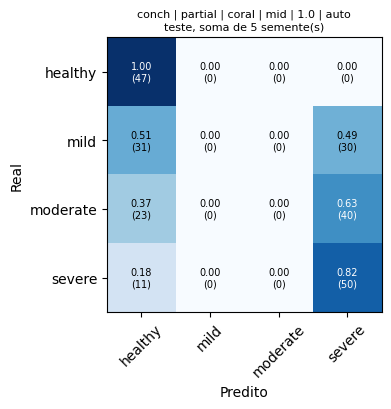

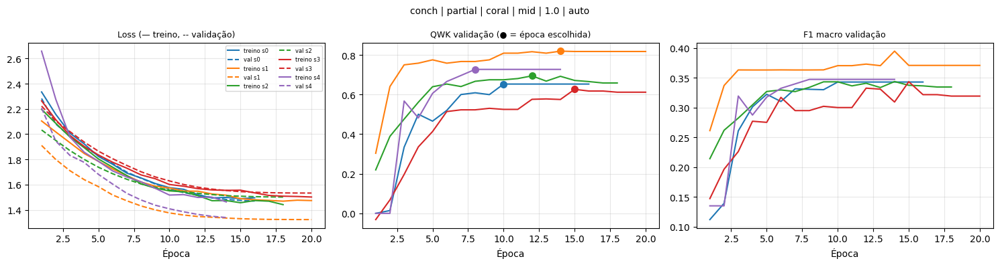

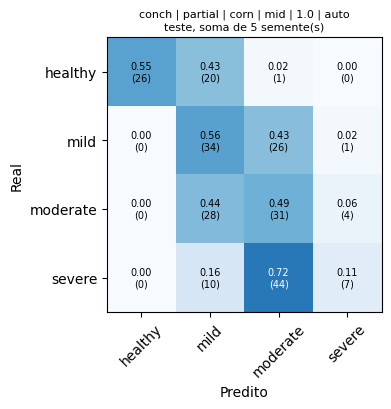

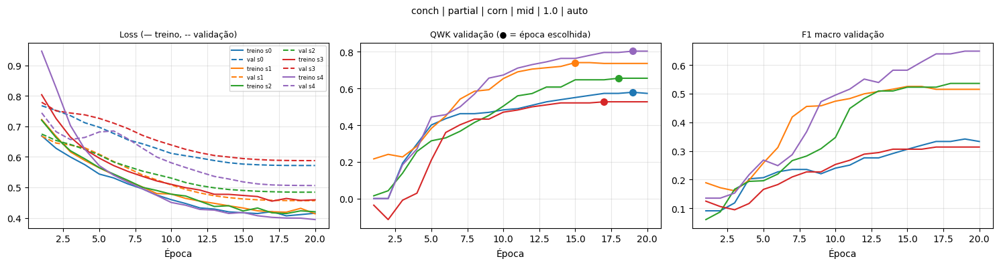

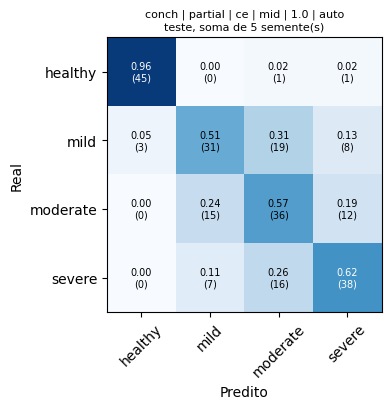

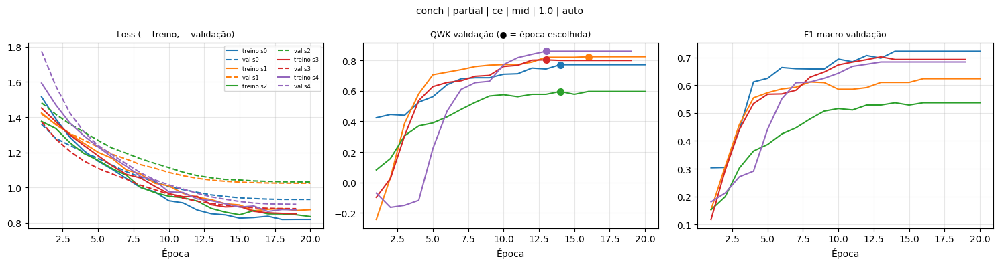

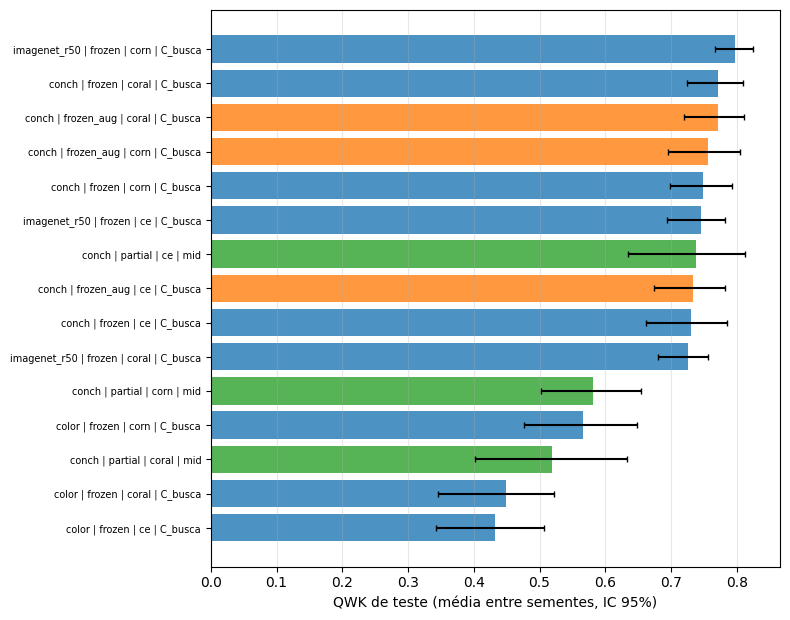


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_conch
[fase 3_partial] concluída em 290.3 min

##########################################################################################
# FASE 4_ablation_aug | conch | run 'bateria_conch'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 135 execução(ões) já salvas em bateria_conch serão puladas
[plano] 3 cenário(s), 15 execução(ões), 15 pendente(s)

===== conch: 15 execução(ões) pendente(s) =====
[conch] janela=448px | Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
[magnificação] conch scale=1: ROI 450x250 -> fator 1.792, 2 janela(s) de 448px | informe Config.native_mpp para comparar com o pré-treino
  >> conch | partial_noaug | coral | mid | 1.0 | auto | semente 0
      lote=8 ROIs x accum 4 (efetivo alvo 32)
      ep 01 loss=2.3482 val_loss=2.2741 val_qwk=0.0000 (86.9s)
      ep 02 loss=2.1533 val_loss=2.0731 val_qwk=0.0201 (85.1s)
      ep 03 loss=2.0045 val_loss=1.9714 val_qwk=0.4813 (86.0s)
      ep 04 loss=1.9096 val_loss=1.8827 val_qwk=0.5521 (85.9s)
      ep 05 loss=1.8173 val_loss=1.8015 val_qwk=0.5801 (85.1s)
      ep 06 loss=1.7381 val_loss=1.7269 val_qwk=0.6349 (84.8s)
      ep 07 loss=1.6702 val_loss=1.6549 val_qwk=0.6925 (84.9s)
      ep 08 loss=1

,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
135,conch,partial_noaug,coral,mid,1.0,auto,0,treino,8.0,4.0,...,1702.3346,6.9681,0.0,0.6217,0.2991,0.4583,0.4400,0.7356,0.7800,0.7139
136,conch,partial_noaug,coral,mid,1.0,auto,1,treino,8.0,4.0,...,1684.7932,6.9681,0.0,0.5489,0.2750,0.4808,0.3846,0.8664,0.8846,0.8174
137,conch,partial_noaug,coral,mid,1.0,auto,2,treino,8.0,4.0,...,1219.0137,6.9636,0.0,0.6649,0.3405,0.5000,0.4878,0.7316,0.7073,0.6678
138,conch,partial_noaug,coral,mid,1.0,auto,3,treino,8.0,4.0,...,1719.9667,6.9681,0.0,0.4067,0.2693,0.3958,0.4186,0.7926,1.0233,0.6598
139,conch,partial_noaug,coral,mid,1.0,auto,4,treino,8.0,4.0,...,1642.6329,6.9546,0.0,0.4229,0.2618,0.4375,0.3696,0.7905,1.0217,0.7338
140,conch,partial_noaug,corn,mid,1.0,auto,0,treino,8.0,4.0,...,1448.2709,6.9681,0.0,0.6116,0.5064,0.5360,0.5400,0.8400,0.5400,0.6714
141,conch,partial_noaug,corn,mid,1.0,auto,1,treino,8.0,4.0,...,1686.7092,6.9681,0.0,0.6564,0.5010,0.5190,0.4615,0.9202,0.5577,0.7414
142,conch,partial_noaug,corn,mid,1.0,auto,2,treino,8.0,4.0,...,1737.7763,6.9636,0.0,0.6949,0.4806,0.4757,0.4390,0.7801,0.5854,0.6797
143,conch,partial_noaug,corn,mid,1.0,auto,3,treino,8.0,4.0,...,1717.9399,6.9681,0.0,0.5659,0.4833,0.5631,0.5349,0.8975,0.6047,0.6608
144,conch,partial_noaug,corn,mid,1.0,auto,4,treino,8.0,4.0,...,1728.8510,6.9547,0.0,0.4802,0.4373,0.4638,0.4348,0.8055,0.6739,0.8112



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.522,NaN,0.032,0.7711 ± 0.0804,0.5927 ± 0.0941,0.5894 ± 0.0998,0.5791 ± 0.0961,0.8145 ± 0.0637,0.4555 ± 0.1179,0.7773 ± 0.0598
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.542,NaN,0.066,0.7490 ± 0.0866,0.6423 ± 0.1012,0.6439 ± 0.0974,0.6350 ± 0.1084,0.8704 ± 0.0465,0.4253 ± 0.1217,0.7760 ± 0.0450
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.422,NaN,0.007,0.7307 ± 0.1013,0.6553 ± 0.1154,0.6718 ± 0.1028,0.6618 ± 0.1020,0.8696 ± 0.0616,0.4296 ± 0.1061,0.7696 ± 0.0849
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.990,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,...,11.454,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.847,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.494,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.827,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.617,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,14.389,NaN,0.003,0.7708 ± 0.0788,0.5902 ± 0.0919,0.5869 ± 0.0937,0.5800 ± 0.0894,0.8250 ± 0.0642,0.4545 ± 0.1121,0.7811 ± 0.0601



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7711 [0.7241, 0.8088]","0.5927 [0.5497, 0.6273]","0.5894 [0.5532, 0.6335]","0.5791 [0.5375, 0.6202]","0.8145 [0.7898, 0.8436]","0.4555 [0.4027, 0.5082]"
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7490 [0.6979, 0.7921]","0.6423 [0.5952, 0.6874]","0.6439 [0.6058, 0.6938]","0.6350 [0.5908, 0.6825]","0.8704 [0.8448, 0.9004]","0.4253 [0.3664, 0.4803]"
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7307 [0.6625, 0.7847]","0.6553 [0.6043, 0.6951]","0.6718 [0.6317, 0.7147]","0.6618 [0.6175, 0.7084]","0.8696 [0.8445, 0.8987]","0.4296 [0.3679, 0.4963]"
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7708 [0.7195, 0.8111]","0.5902 [0.5420, 0.6294]","0.5869 [0.5471, 0.6412]","0.5800 [0.5377, 0.6262]","0.8250 [0.7984, 0.8579]","0.4545 [0.3950, 0.5089]"


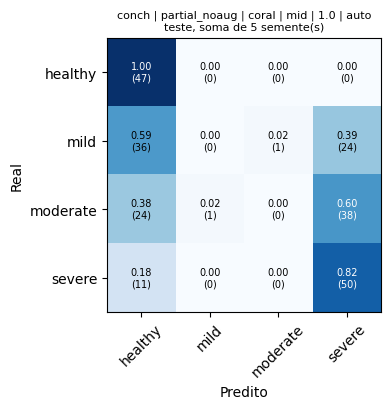

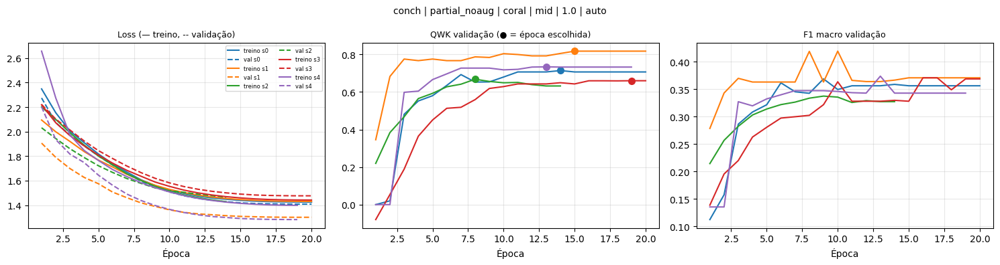

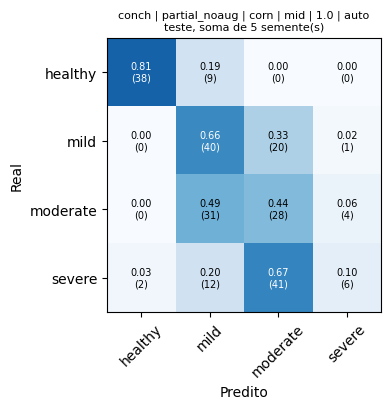

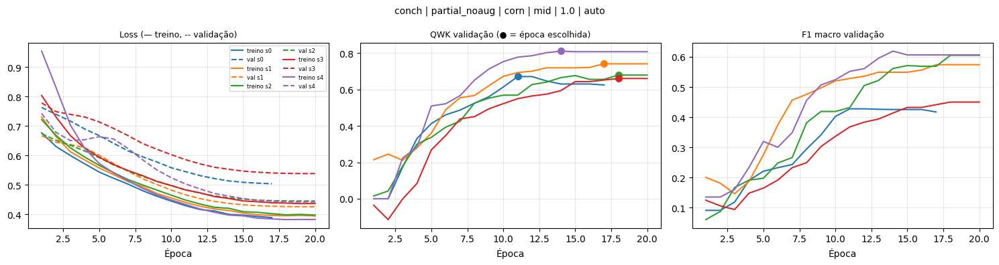

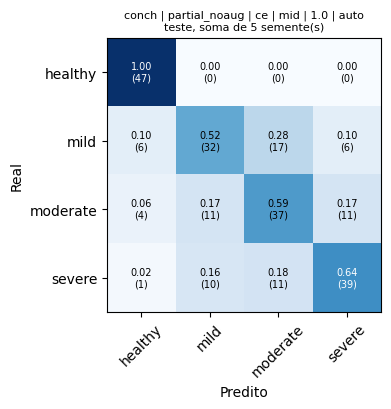

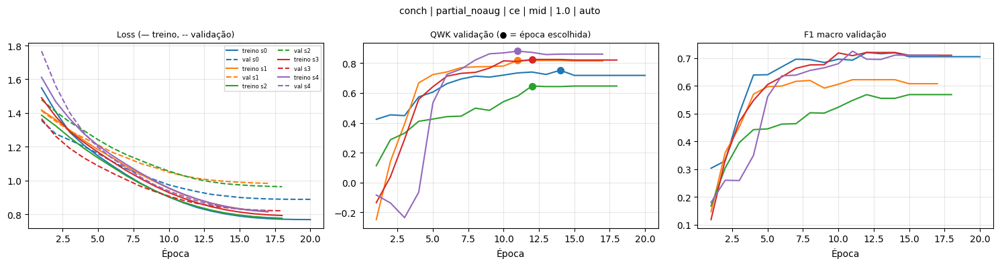

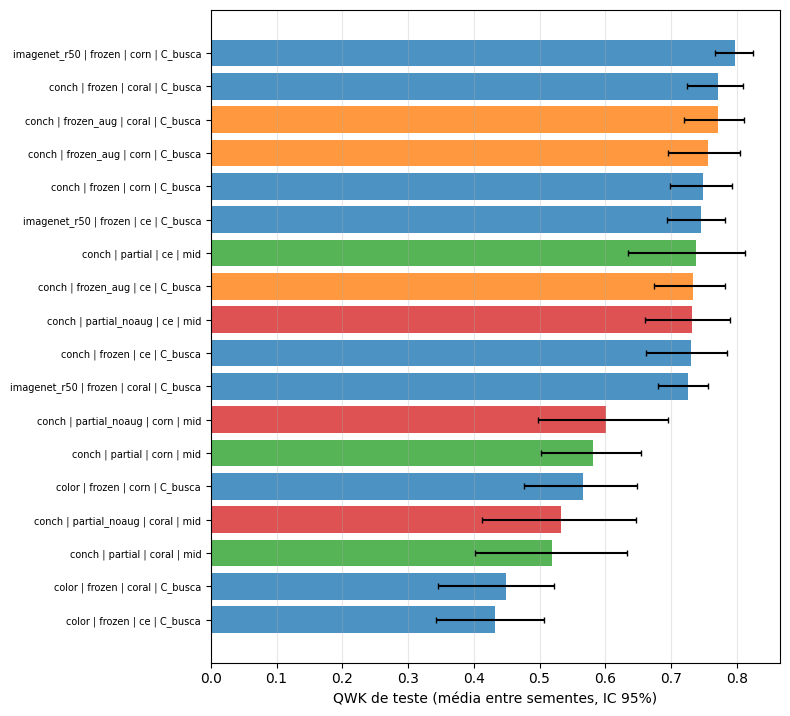


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_conch
[fase 4_ablation_aug] concluída em 409.4 min
[seleção] QWK médio de VALIDAÇÃO por loss (conch, partial): {'ce': 0.7707, 'coral': 0.704, 'corn': 0.6613} -> ce

##########################################################################################
# FASE 5_lr | conch | run 'bateria_conch'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 150 execução(ões) já salvas em bateria_conch serão puladas
[plano] 2 cenário(s), 10 execução(ões), 10 pendente(s)

===== conch: 10 execução(ões) pendente(s) =====
[conch] janela=448px | Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
[magnificação] conch scale=1: ROI 450x250 -> fator 1.792, 2 janela(s) de 448px | informe Config.native_mpp para comparar com o pré-treino
  >> conch | partial | ce | low | 1.0 | auto | semente 0
      lote=8 ROIs x accum 4 (efetivo alvo 32)
      ep 01 loss=1.5416 val_loss=1.4132 val_qwk=0.3777 (83.8s)
      ep 02 loss=1.5076 val_loss=1.3877 val_qwk=0.4330 (84.7s)
      ep 03 loss=1.4718 val_loss=1.3655 val_qwk=0.4235 (85.2s)
      ep 04 loss=1.4402 val_loss=1.3444 val_qwk=0.4235 (85.1s)
      ep 05 loss=1.4132 val_loss=1.3270 val_qwk=0.4518 (85.3s)
      ep 06 loss=1.3911 val_loss=1.3123 val_qwk=0.4606 (84.9s)
      ep 07 loss=1.3623 val_loss=1.2999 val_qwk=0.4361 (85.3s)
      ep 08 loss=1.3460 val

,Modelo,Regime,Loss,LR,Escala,Config. batch,Semente,batch_role,Batch size,accum_steps,...,train_time_s,peak_vram_gb,oom_retries,test_qwk,test_f1_macro,test_bacc,test_acc,test_auroc,test_mod,val_qwk
150,conch,partial,ce,low,1.0,auto,0,treino,8.0,4.0,...,1018.9770,6.9681,0.0,0.3313,0.2582,0.3958,0.3800,0.6672,1.1200,0.4606
151,conch,partial,ce,low,1.0,auto,1,treino,8.0,4.0,...,1688.0555,6.9681,0.0,0.1463,0.3053,0.2804,0.2885,0.6783,0.9808,0.2246
152,conch,partial,ce,low,1.0,auto,2,treino,8.0,4.0,...,1220.7224,6.9636,0.0,0.5271,0.3460,0.3194,0.3415,0.6024,0.7561,0.1359
153,conch,partial,ce,low,1.0,auto,3,treino,8.0,4.0,...,1726.4121,6.9681,0.0,0.2279,0.2020,0.2689,0.2791,0.5718,0.9302,0.0709
154,conch,partial,ce,low,1.0,auto,4,treino,8.0,4.0,...,607.3955,6.9547,0.0,0.0465,0.1367,0.2708,0.2609,0.5600,0.9130,-0.0313
155,conch,partial,ce,high,1.0,auto,0,treino,8.0,4.0,...,1280.6573,6.9681,0.0,0.8149,0.6521,0.6765,0.6800,0.8827,0.3800,0.7778
156,conch,partial,ce,high,1.0,auto,1,treino,8.0,4.0,...,1355.1181,6.9681,0.0,0.8831,0.7876,0.7853,0.7692,0.9258,0.2308,0.8321
157,conch,partial,ce,high,1.0,auto,2,treino,8.0,4.0,...,1742.6439,6.9636,0.0,0.8077,0.6353,0.6528,0.6341,0.8589,0.4146,0.7515
158,conch,partial,ce,high,1.0,auto,3,treino,8.0,4.0,...,1205.3160,6.9681,0.0,0.7076,0.6452,0.6521,0.6512,0.8317,0.4651,0.8582
159,conch,partial,ce,high,1.0,auto,4,treino,8.0,4.0,...,1387.1706,6.9547,0.0,0.7279,0.7085,0.7193,0.6957,0.8900,0.3696,0.8871



===== Teste: média ± DP entre sementes (com metadados de batch, épocas e tempo) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_media_dp.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,accum_steps,batch_efetivo,...,tempo_total_s,vram_pico_gb,C_mediano,QWK,F1 macro,Bal. acc,Acc,AUROC,MOD,QWK val
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.522,NaN,0.032,0.7711 ± 0.0804,0.5927 ± 0.0941,0.5894 ± 0.0998,0.5791 ± 0.0961,0.8145 ± 0.0637,0.4555 ± 0.1179,0.7773 ± 0.0598
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.542,NaN,0.066,0.7490 ± 0.0866,0.6423 ± 0.1012,0.6439 ± 0.0974,0.6350 ± 0.1084,0.8704 ± 0.0465,0.4253 ± 0.1217,0.7760 ± 0.0450
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,...,1.422,NaN,0.007,0.7307 ± 0.1013,0.6553 ± 0.1154,0.6718 ± 0.1028,0.6618 ± 0.1020,0.8696 ± 0.0616,0.4296 ± 0.1061,0.7696 ± 0.0849
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.990,NaN,0.003,0.7251 ± 0.0630,0.5131 ± 0.0997,0.5204 ± 0.0991,0.5036 ± 0.0913,0.8076 ± 0.0469,0.5237 ± 0.0963,0.7456 ± 0.0586
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,...,11.454,NaN,0.066,0.7971 ± 0.0765,0.6572 ± 0.0810,0.6534 ± 0.0797,0.6466 ± 0.0852,0.8568 ± 0.0437,0.3901 ± 0.1173,0.8014 ± 0.0349
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,...,8.847,NaN,0.001,0.7456 ± 0.1424,0.6106 ± 0.1250,0.6310 ± 0.1078,0.6225 ± 0.1279,0.8443 ± 0.0432,0.4607 ± 0.1996,0.7928 ± 0.0566
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.494,NaN,0.658,0.4490 ± 0.1482,0.3781 ± 0.0855,0.3982 ± 0.0895,0.3972 ± 0.0818,0.6576 ± 0.0666,0.7541 ± 0.1087,0.4901 ± 0.0798
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.827,NaN,6.581,0.5661 ± 0.1948,0.5362 ± 0.0480,0.5488 ± 0.0600,0.5401 ± 0.0633,0.7932 ± 0.0444,0.6117 ± 0.1436,0.5661 ± 0.0577
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,...,0.617,NaN,0.032,0.4324 ± 0.1985,0.4575 ± 0.1394,0.5065 ± 0.1102,0.4857 ± 0.1201,0.7678 ± 0.0668,0.7950 ± 0.2545,0.4713 ± 0.1377
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,...,14.389,NaN,0.003,0.7708 ± 0.0788,0.5902 ± 0.0919,0.5869 ± 0.0937,0.5800 ± 0.0894,0.8250 ± 0.0642,0.4545 ± 0.1121,0.7811 ± 0.0601



===== Teste: média entre sementes + IC 95% (bootstrap de 1000 por imagem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/resumo_ic_bootstrap.csv


,Modelo,Regime,Loss,LR,Escala,Config. batch,n_sementes,batch_size,batch_efetivo,melhor_epoca,qwk,f1_macro,bacc,acc,auroc,mod
0,conch,frozen,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7711 [0.7241, 0.8088]","0.5927 [0.5497, 0.6273]","0.5894 [0.5532, 0.6335]","0.5791 [0.5375, 0.6202]","0.8145 [0.7898, 0.8436]","0.4555 [0.4027, 0.5082]"
1,conch,frozen,corn,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7490 [0.6979, 0.7921]","0.6423 [0.5952, 0.6874]","0.6439 [0.6058, 0.6938]","0.6350 [0.5908, 0.6825]","0.8704 [0.8448, 0.9004]","0.4253 [0.3664, 0.4803]"
2,conch,frozen,ce,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7307 [0.6625, 0.7847]","0.6553 [0.6043, 0.6951]","0.6718 [0.6317, 0.7147]","0.6618 [0.6175, 0.7084]","0.8696 [0.8445, 0.8987]","0.4296 [0.3679, 0.4963]"
3,imagenet_r50,frozen,coral,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7251 [0.6810, 0.7564]","0.5131 [0.4629, 0.5495]","0.5204 [0.4813, 0.5670]","0.5036 [0.4630, 0.5445]","0.8076 [0.7850, 0.8325]","0.5237 [0.4782, 0.5692]"
4,imagenet_r50,frozen,corn,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7971 [0.7672, 0.8246]","0.6572 [0.6102, 0.6963]","0.6534 [0.6122, 0.7027]","0.6466 [0.6045, 0.6896]","0.8568 [0.8334, 0.8834]","0.3901 [0.3416, 0.4348]"
5,imagenet_r50,frozen,ce,C_busca,1.0,auto,10,128.0,NaN,NaN,"0.7456 [0.6942, 0.7825]","0.6106 [0.5616, 0.6505]","0.6310 [0.5882, 0.6764]","0.6225 [0.5800, 0.6646]","0.8443 [0.8164, 0.8700]","0.4607 [0.4050, 0.5186]"
6,color,frozen,coral,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4490 [0.3452, 0.5225]","0.3781 [0.3140, 0.4262]","0.3982 [0.3442, 0.4566]","0.3972 [0.3418, 0.4573]","0.6576 [0.6075, 0.7082]","0.7541 [0.6761, 0.8326]"
7,color,frozen,corn,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.5661 [0.4770, 0.6476]","0.5362 [0.4914, 0.5806]","0.5488 [0.5118, 0.5978]","0.5401 [0.5004, 0.5837]","0.7932 [0.7604, 0.8293]","0.6117 [0.5360, 0.6828]"
8,color,frozen,ce,C_busca,1.0,auto,10,NaN,NaN,NaN,"0.4324 [0.3420, 0.5073]","0.4575 [0.4001, 0.4999]","0.5065 [0.4570, 0.5508]","0.4857 [0.4360, 0.5348]","0.7678 [0.7346, 0.8026]","0.7950 [0.7133, 0.8847]"
9,conch,frozen_aug,coral,C_busca,1.0,auto,10,32.0,NaN,NaN,"0.7708 [0.7195, 0.8111]","0.5902 [0.5420, 0.6294]","0.5869 [0.5471, 0.6412]","0.5800 [0.5377, 0.6262]","0.8250 [0.7984, 0.8579]","0.4545 [0.3950, 0.5089]"


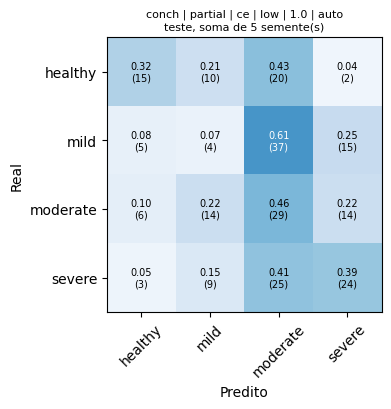

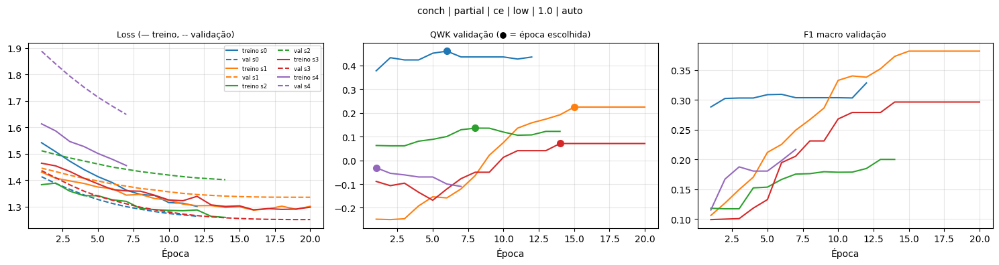

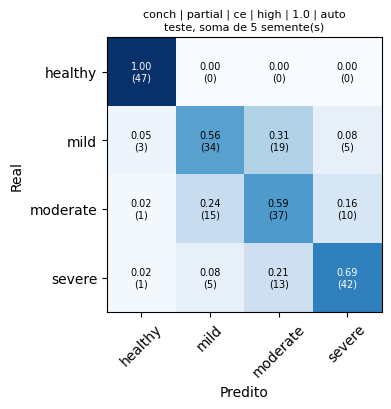

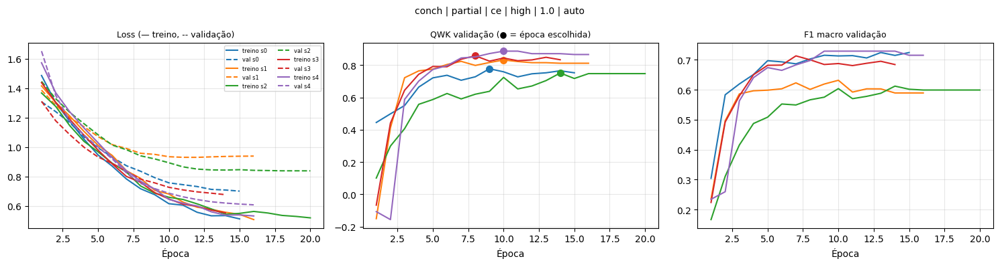

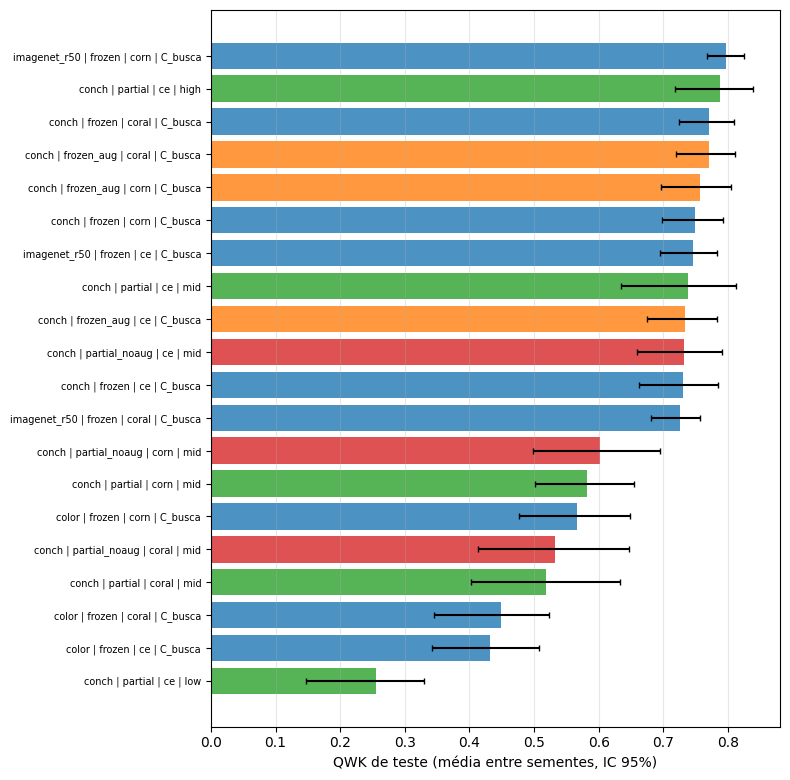


[ok] artefatos salvos em /content/drive/MyDrive/resultados_histopatologia/bateria_conch
[fase 5_lr] concluída em 227.6 min
[seleção] QWK médio de VALIDAÇÃO por loss (conch, partial): {'ce': 0.7707, 'coral': 0.704, 'corn': 0.6613} -> ce

##########################################################################################
# FASE 6_batch_size | conch | run 'bateria_conch'
##########################################################################################
[dataset] cópia local já completa (456 imagens) em /content/dataset
[dataset] 456 ROIs de 108 imagens de origem | por classe: {'healthy': 114, 'mild': 114, 'moderate': 114, 'severe': 114} | ROI 450x250

===== Split 70%/20%/10% por semente (por imagem de origem) =====  ->  /content/drive/MyDrive/resultados_histopatologia/bateria_conch/tabelas/splits_resumo.csv


,semente,train_rois,train_%,train_imagens,train_por_classe,val_rois,val_%,val_imagens,val_por_classe,test_rois,test_%,test_imagens,test_por_classe
0,0,316,69.3,75,"[75, 79, 86, 76]",90,19.7,22,"[27, 20, 17, 26]",50,11.0,11,"[12, 15, 11, 12]"
1,1,308,67.5,75,"[76, 85, 74, 73]",96,21.1,22,"[30, 16, 22, 28]",52,11.4,11,"[8, 13, 18, 13]"
2,2,323,70.8,75,"[82, 85, 83, 73]",92,20.2,22,"[24, 20, 19, 29]",41,9.0,11,"[8, 9, 12, 12]"
3,3,308,67.5,75,"[73, 80, 78, 77]",105,23.0,22,"[30, 25, 25, 25]",43,9.4,11,"[11, 9, 11, 12]"
4,4,329,72.1,75,"[76, 82, 86, 85]",81,17.8,22,"[30, 17, 17, 17]",46,10.1,11,"[8, 15, 11, 12]"


[retomada] 160 execução(ões) já salvas em bateria_conch serão puladas
[plano] 4 cenário(s), 20 execução(ões), 20 pendente(s)

===== conch: 20 execução(ões) pendente(s) =====
[conch] janela=448px | Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
[magnificação] conch scale=1: ROI 450x250 -> fator 1.792, 2 janela(s) de 448px | informe Config.native_mpp para comparar com o pré-treino
  >> conch | partial | ce | mid | 1.0 | bs16_eff16 | semente 0
      lote=16 ROIs x accum 1 (efetivo alvo 16)
      ep 01 loss=1.4965 val_loss=1.3274 val_qwk=0.4606 (87.2s)
      ep 02 loss=1.3320 val_loss=1.2409 val_qwk=0.4924 (86.3s)
      ep 03 loss=1.1982 val_loss=1.1779 val_qwk=0.5958 (87.0s)
      ep 04 loss=1.1053 val_loss=1.1113 val_qwk=0.6510 (86.6s)
      ep 05 loss=1.0176 val_loss=1.0516 val_qwk=0.6656 (86.3s)
      ep 06 loss=0.9398 val_loss=0.9860 val_qwk=0.7020 (86.6s)
      ep 07 loss=0.8698 val_loss=0.9327 val_qwk=0.7251 (86.8s)
      ep 08 loss=0.8

In [ ]:
# %% [CÉLULA 10] Rotina de testes: checagens de sanidade, smoke test e bateria para uma foundation
from scipy.optimize import check_grad  # noqa: E402


def run_sanity_checks(cfg: Config, check_data: bool = True) -> None:
    """Testes rápidos (segundos, sem GPU pesada) que pegam erros silenciosos antes de gastar
    horas de Colab. Qualquer falha levanta AssertionError."""
    rng = np.random.default_rng(0)
    K = NUM_CLASSES

    # 1) gradiente analítico da sonda linear == gradiente numérico
    X, y = rng.normal(size=(40, 6)), rng.integers(0, K, 40)
    for loss in LOSSES:
        wshape, nb = _probe_shapes(loss, 6)
        th = rng.normal(scale=0.1, size=wshape[0] * wshape[1] + nb)
        err = check_grad(lambda t: _probe_objective(t, X, y, loss, 0.01)[0],
                         lambda t: _probe_objective(t, X, y, loss, 0.01)[1], th)
        assert err < 1e-4, f"gradiente da sonda {loss} incorreto (erro {err:.2e})"

    # 2) losses torch (partial) == objetivo numpy (frozen) com lam=0
    Z = rng.normal(size=(30, K))
    yt = rng.integers(0, K, 30)
    ce_np = _probe_objective(np.concatenate([np.eye(K).ravel(), np.zeros(K)]), Z, yt, "ce", 0.0)[0]
    Zc = Z[:, :K - 1]
    corn_np = _probe_objective(np.concatenate([np.eye(K - 1).ravel(), np.zeros(K - 1)]), Zc, yt, "corn", 0.0)[0]
    x1, bias = Z[:, :1], rng.normal(size=K - 1)
    coral_np = _probe_objective(np.concatenate([[1.0], bias]), x1, yt, "coral", 0.0)[0]
    tz, ty = torch.tensor(Z), torch.tensor(yt)
    assert abs(float(make_criterion("ce", 0.0)(tz, ty)) - ce_np) < 1e-8, "CE torch != numpy"
    assert abs(float(corn_loss(torch.tensor(Zc), ty)) - corn_np) < 1e-8, "CORN torch != numpy"
    assert abs(float(coral_loss(torch.tensor(x1 + bias), ty)) - coral_np) < 1e-8, "CORAL torch != numpy"

    # 3) decodificação: probabilidades somam 1 e a predição ordinal é coerente
    for loss in LOSSES:
        P, d = np_probs_preds(rng.normal(size=(50, K if loss == "ce" else K - 1)), loss)
        assert np.allclose(P.sum(1), 1) and d.min() >= 0 and d.max() < K, f"decodificação {loss}"

    # 4) métricas rápidas (bootstrap) == métricas sklearn (inclui classes ausentes)
    for trial in range(30):
        n = int(rng.integers(8, 60))
        yy = rng.integers(0, K - (trial % 3 == 0), n)
        PP = rng.dirichlet(np.ones(K), n)
        dd = PP.argmax(1) if trial % 2 else rng.integers(0, K, n)
        a, b = compute_metrics(yy, PP, dd), fast_metrics(yy, PP, dd)
        for k in METRIC_KEYS:
            assert (np.isnan(a[k]) and np.isnan(b[k])) or abs(a[k] - b[k]) < 1e-9, f"métrica {k}: {a[k]} x {b[k]}"

    # 5) multi-crop cobre a ROI inteira com janelas no tamanho nativo
    views = roi_views(Image.new("RGB", (450, 250)), 224)
    assert len(views) == 2 and all(v.size == (224, 224) for v in views), "multi-crop inesperado"

    # 6) split 70/20/10 sem vazamento, em todas as sementes, no dataset real
    if check_data:
        paths, labels, groups = prepare_data(cfg)
        for s in cfg.seeds:
            make_holdout_split(labels, groups, s, cfg)
        display(split_summary({s: make_holdout_split(labels, groups, s, cfg) for s in cfg.seeds[:3]},
                              labels, groups))

    # 7) plano de batch size para esta GPU
    print(f"[batch] GPU {ENV_INFO['gpu']} ({ENV_INFO.get('vram_gb')} GB) -> fator {vram_factor()}x")
    display(pd.DataFrame([{"backbone": b, "extract": resolve_batch_size(b, "extract", cfg),
                           **{f"partial_{k}": v for k, v in partial_batch_plan(b, cfg, None).items()}}
                          for b in BACKBONES if BATCH_SIZE_T4[b]["partial"]]))
    print("[sanidade] todas as checagens passaram")


def suite_phases(bb: str) -> Dict[str, Dict]:
    s5 = SEEDS[:5]
    return {
        "0_smoke": dict(run_name=f"smoke_{bb}", resume=False, backbone=[bb, "color"],
                        regime=["frozen", "frozen_aug", "partial"], loss=["all"], seeds=[0],
                        epochs=2, patience=2, subset_groups_per_class=8, c_grid=[1e-3, 1e-2, 1e-1],
                        frozen_aug_copies=1, n_boot=50),
        "1_frozen_baselines": dict(backbone=[bb, "imagenet_r50", "color"], regime=["frozen"], loss=["all"]),
        "2_frozen_aug": dict(backbone=[bb], regime=["frozen_aug"], loss=["all"]),
        "3_partial": dict(backbone=[bb], regime=["partial"], loss=["all"], seeds=s5),
        "4_ablation_aug": dict(backbone=[bb], regime=["partial_noaug"], loss=["all"], seeds=s5),
        "5_lr": dict(backbone=[bb], regime=["partial"], loss=["@best_partial"], lr_variant=["low", "high"],
                     seeds=s5),
        "6_batch_size": dict(backbone=[bb], regime=["partial"], loss=["@best_partial"], seeds=s5,
                             partial_batch_configs=[(16, 16), (16, 32), (32, 64), (32, 128)]),
        "7_magnificacao": dict(backbone=[bb], regime=["frozen"], loss=["@best_frozen"],
                               scales=[1.0, 0.75, 0.5]),
    }


def pick_best_loss(run_dir: Path, bb: str, regime: str) -> str:
    f = run_dir / "tabelas" / "execucoes_por_semente.csv"
    if not f.exists():
        raise RuntimeError(f"Rode antes a fase com regime '{regime}' (não achei {f}).")
    df = pd.read_csv(f)
    df = df[(df.backbone == bb) & (df.regime == regime) & (df.batch_cfg == "auto") &
            (df.lr_variant.isin(["mid", "C_busca"])) & (df.scale.round(6) == 1.0)]
    if df.empty:
        raise RuntimeError(f"Sem execuções de {bb}/{regime} em {f}.")
    by = df.groupby("loss").val_qwk.mean().sort_values(ascending=False)
    print(f"[seleção] QWK médio de VALIDAÇÃO por loss ({bb}, {regime}): {by.round(4).to_dict()}"
          f" -> {by.index[0]}")
    return str(by.index[0])


def run_suite(bb: str, fases: List[str], base: Config, run_name: Optional[str] = None,
              seeds: Optional[List[int]] = None) -> Dict[str, Dict]:
    run_name = run_name or f"bateria_{bb}"
    run_dir = Path(base.drive_results_dir) / run_name
    phases, results = suite_phases(bb), {}
    for fase in fases:
        ov = dict(phases[fase])
        if seeds is not None and "seeds" not in ov:
            ov["seeds"] = list(seeds)
        if ov.get("loss") == ["@best_partial"]:
            ov["loss"] = [pick_best_loss(run_dir, bb, "partial")]
        elif ov.get("loss") == ["@best_frozen"]:
            ov["loss"] = [pick_best_loss(run_dir, bb, "frozen")]
        ov.setdefault("run_name", run_name)
        ov.setdefault("resume", True)
        cfg = dataclasses.replace(base, **ov)
        print("\n" + "#" * 90 + f"\n# FASE {fase} | {bb} | run '{cfg.run_name}'\n" + "#" * 90)
        t0 = time.time()
        results[fase] = main(cfg)
        print(f"[fase {fase}] concluída em {(time.time() - t0) / 60:.1f} min")
    return results


# ------------------------------- EXECUÇÃO -------------------------------

FASES = ["0_smoke", "1_frozen_baselines", "2_frozen_aug", "3_partial", "4_ablation_aug",
         "5_lr", "6_batch_size", "7_magnificacao"]

RODAR_SANIDADE = True

# ── diagnóstico: mostra quantas execuções já estão salvas antes de rodar ──
import pandas as pd
from pathlib import Path

for _bb in ["uni", "conch", "virchow"]:
    _pasta = Path(CFG.drive_results_dir) / f"bateria_{_bb}"
    _csv   = _pasta / "tabelas" / "execucoes_por_semente.csv"
    if _csv.exists():
        _n = len(pd.read_csv(_csv))
        print(f"[retomada] bateria_{_bb}: {_n} execuções já salvas → vai CONTINUAR de onde parou")
    else:
        print(f"[retomada] bateria_{_bb}: nenhuma execução salva → vai COMEÇAR DO ZERO")

# ── execução principal ────────────────────────────────────────────────────
if RODAR_SANIDADE:
    run_sanity_checks(CFG)

for backbone in ["uni", "conch", "virchow"]:
    print("\n" + "=" * 90)
    print(f"  INICIANDO BATERIA: {backbone.upper()}")
    print("=" * 90)
    globals()[f"RESULTS_{backbone}"] = run_suite(
        bb       = backbone,
        fases    = FASES,
        base     = CFG,
        run_name = f"bateria_{backbone}",  # nome fixo: garante retomada na mesma pasta
    )